# Pronóstico horario del consumo de energía por subestación — Universidad EAFIT

> 🌐 **Versión pública.** Los datos de consumo son de la Universidad EAFIT y no son abiertos. Por eso, en esta versión:
> - las 9 subestaciones aparecen con un código anónimo (**SUB1 a SUB9**);
> - **toda cifra de energía (kWh) y de costo (COP) está multiplicada por un mismo factor confidencial**, elegido para que
>   todos los cálculos (modelos incluidos) den exactamente el mismo resultado que con los valores reales. Las formas de las curvas, las proporciones, los porcentajes y todas las
>   métricas relativas (WAPE, MASE, % de reducción del error, sensibilidad y precisión de alertas) son **idénticos** a los de la
>   versión completa;
> - la capacidad de cada transformador y la relación subestación → bloques no se publican (viven en `datos/privado.json`, que
>   solo tiene el equipo).
>
> Para ejecutarlo se necesitan los datos y ese archivo (ver `datos/README.md`). La versión con los valores reales se presenta en
> la sustentación.

### Proyecto Integrador · Componente de Aprendizaje Automático (SI7009)

**Pregunta que responde este notebook:** *a la medianoche de hoy, ¿cuántos kWh va a comprar cada subestación del campus a EPM en cada una de las 24 horas de mañana, y cuánto costará?*

---

## Cómo leer este notebook (guía rápida)

Este notebook está escrito **"a modo dummie"**: cada paso explica **qué** se hace, **por qué** se decidió así y **qué evidencia** respalda la decisión. Está organizado siguiendo la rúbrica del curso:

| Criterio de la rúbrica | Peso | Dónde está |
|---|---|---|
| 1. Formulación del problema | 15 % | Sección 1 |
| 2. EDA e ingeniería de características | 15 % | Secciones 3, 4 y 5 |
| 3. Entrenamiento, validación y selección | 25 % | Secciones 6, 7, 8 y 9 |
| 4. Métricas y diagnóstico | 15 % | Secciones 6.3, 10 y 11 |
| 5. Métrica de negocio y utilidad | 15 % | Sección 12 |
| 6. Caso aplicado | 10 % | Sección 13 |
| 7. Sustentación | 5 % | Sección 14 (preguntas y respuestas para preparar la defensa) |

**Convenciones**

- 🧠 **Idea dummie:** explicación intuitiva, sin jerga.
- ✅ **Decisión:** lo que elegimos y por qué.
- ⚠️ **Cuidado:** riesgos, supuestos o limitaciones.
- Las celdas de código tienen comentarios línea a línea. Si solo quieres entender el proyecto, puedes leer las celdas de texto y los resultados.

**De dónde salen los datos (versión 4):** el notebook lee las tablas que deja el pipeline **Medallion en Databricks**
(catálogo `workspace.eafit_energia`). Dentro de Databricks las lee con Spark; desde un computador, con el conector SQL y
credenciales guardadas fuera del notebook (variables de entorno o `.env`). Si no hay conexión, usa como respaldo los
mismos archivos originales que recibe Bronze (carpeta `datos/`). La celda 2.1 dice exactamente qué tabla y qué columna usa.

| Dato | Tabla en Databricks | Respaldo en `datos/` |
|---|---|---|
| Energía horaria comprada a la red (kWh) de 9 subestaciones, **valor original** | `silver_consumo` (columna `kwh_original` y su marca de calidad) | `Subestaciones_15_abril_2025_-_22_oct_2026.xlsx` |
| Capacidad (kVA) de cada transformador | `silver_dim_subestacion` (se contrasta con la confirmada por la universidad) | archivo privado `datos/privado.json` (no se publica) |
| Medidor general de la universidad, solo para conciliar | `silver_demanda_total` | `consumo_total.xlsx` |
| Clima horario NASA POWER en el campus | `silver_clima` | `clima_nasa_power_eafit.csv` |

Metodología base: **CRISP-DM** (entender negocio → entender datos → preparar → modelar → evaluar → desplegar) y las prácticas de la **Sesión 3 del curso** (forecasting tabular, baselines temporales, walk-forward, modelos globales, MASE/WAPE).

---
# 1. Formulación del problema (negocio → Machine Learning)

## 1.1 El problema de negocio

La universidad compra la energía a EPM en el **mercado no regulado**, a una tarifa por kWh que cambia cada mes (≈ COP 498–546/kWh en 2025-2026). Hoy existen registros históricos por subestación, pero **no existe una estimación de lo que se va a consumir**. Eso impide:

1. **Planear:** saber mañana qué horas y qué subestaciones tendrán más demanda y cuánto costará el día (presupuesto diario/semanal).
2. **Vigilar:** comparar lo real contra lo esperado para detectar desviaciones (equipos encendidos de más, fallas de medición, cargas transferidas).
3. **Cobrar:** tener un orden de magnitud de cuánta energía extra aparece en un día atípico (por ejemplo, un evento) en un bloque, como insumo para fijar precios cuando se alquilan espacios (sin agenda de eventos es solo una referencia).

## 1.2 ¿Qué decisión apoya el modelo?

| Usuario | Decisión | Cómo la apoya el modelo |
|---|---|---|
| Jefe de mantenimiento / energía | ¿Reviso hoy alguna subestación? | Alerta si el consumo real supera el pronóstico + un umbral (Sección 12.3) |
| Planeación financiera | ¿Cuánto presupuesto de energía reservo para mañana / la semana? | Suma del pronóstico horario × tarifa (Sección 12.2) |
| Gestión de espacios | ¿Cuánto cobro de energía por un evento? | Solo un **orden de magnitud**: diferencia observado − pronosticado en días atípicos (Sección 12.4). Un precio real exigiría eventos identificados y una estimación de su consumo adicional |

## 1.3 Traducción a una tarea de Machine Learning

🧠 **Idea dummie:** el modelo **no** predice "el día de mañana" como un bloque. Predice **una hora a la vez**. Cada fila de la tabla es *una subestación en una hora*, con su consumo real (lo que queremos adivinar) y unas columnas con pistas que **ya se conocían a la medianoche anterior**.

| Elemento | Definición en este proyecto |
|---|---|
| **Tipo de tarea** | Aprendizaje supervisado de **regresión**, formulado como *forecasting tabular* con un **modelo global** (un solo modelo para las 9 subestaciones). |
| **Variable objetivo (y)** | kWh **comprados a la red (EPM)** en una hora, por subestación. |
| **Unidad de observación (fila)** | (subestación, fecha, hora). |
| **Momento de emisión (t)** | **00:00** de cada día. Último dato conocido: 23:00 del día anterior. |
| **Horizonte** | Las 24 horas del día siguiente (de 1 a 24 horas adelante). |
| **Estrategia multi-paso** | Directa: ninguna hora usa la predicción de otra hora; todas las pistas de consumo miran **24 horas atrás o más**. |
| **Salida para el negocio** | 24 × 9 valores en kWh → se pueden sumar en totales diarios de la **suma de las nueve subestaciones** y se multiplican por la tarifa estimada (COP). |

✅ **Decisión: ¿por qué horario y a 24 horas?** Con ~18 meses de historia, la escala horaria da ~13 000 puntos por subestación; la semanal daría ~78 y la mensual ~18, insuficientes para entrenar y validar. Si la universidad necesita un total diario, **se obtiene sumando** las 24 horas del pronóstico emitido a medianoche (Sección 11.3). ⚠️ Sumar siete pronósticos diarios consecutivos **no es lo mismo** que pronosticar la semana completa desde el lunes (cada día se emite con información distinta); por eso el error semanal se reporta solo donde hay semanas completas y con su cobertura.

✅ **Decisión: ¿por qué emitir a medianoche?** Es la hora que fija qué datos pasados están disponibles: a medianoche ya terminó el día anterior completo. Esto hace muy fácil auditar que no hay **fuga de información** (*leakage*).

## 1.4 Supuestos y restricciones (acordados con la universidad)

| # | Supuesto / restricción | Fuente | Consecuencia |
|---|---|---|---|
| S1 | Cada medidor registra **energía comprada a EPM**, no el consumo bruto. En las subestaciones con generación solar propia la compra baja al mediodía. | Respuesta de la universidad | Pronosticamos lo que **se paga**. El sol "esconde" parte del consumo. |
| S2 | **No hay generación solar horaria disponible.** | Universidad | No podemos separar consumo bruto y solar. |
| S3 | Ceros, negativos y picos imposibles son **errores del sistema**, no consumo real (ej.: 21-feb-2026 16:00, valores cientos de veces mayores que lo normal). | Universidad | Se limpian (Sección 4). |
| S4 | SUB3 cambió **transformador y medidor** entre ene y mar-2026; el periodo sin datos no es recuperable (igual que el hueco de SUB1). | Universidad | Solo se usa SUB3 desde el 5-mar-2026. |
| S5 | SUB1 no tiene datos antes del 20-nov-2025 (cambios de infraestructura). | Universidad | SUB1 se usa desde esa fecha. |
| S6 | SUB9 es una carga de **climatización**: casi cero de noche, alta de día. | Universidad | Perfil normal, no se trata como anomalía. |
| S7 | **La agenda de eventos no está disponible** (la universidad indicó que no se puede conseguir; una revisión posterior la describe como intermitente, sin que se haya entregado). | Universidad | No se usa como variable ni para confirmar eventos. Los días atípicos se detectan en el histórico y su error se reporta aparte; **ningún día atípico se llama "evento confirmado"** sin un registro. |
| S8 | Calendario académico: **2026 oficial** según el cronograma de pregrado aprobado el 22-abr-2026 (2026-1: clases 19-ene a 16-may y finales hasta el 30-may; Semana Santa 30-mar a 5-abr; 2026-2: clases 13-jul a 7-nov, receso 5 a 11-oct y finales hasta el 21-nov; vacaciones colectivas desde el 14-dic). **2025 estimado**: las fechas de 2026 trasladadas 52 semanas (mismo día de la semana) y comprobadas con el consumo (inicio de 2025-2 el 14-jul, receso 6 a 12-oct); Semana Santa 2025 con sus fechas reales (14 a 20-abr) y cierre 2025 desde el 20-dic según la caída del consumo. | Universidad (2026) y equipo (2025) | Variable `periodo` y `semana_semestre`. 2025 se trata como supuesto, no como dato. |
| S9 | La hoja "demanda" de `consumo_total.xlsx` (tabla `silver_demanda_total` en Databricks) es el **total de la universidad** (medidor general); se espera que coincida **aproximadamente** con la suma de las nueve series. | Universidad | Se concilia en la Sección 3.3. La causa exacta de la diferencia **no está confirmada**. |
| S10 | Las tarifas se conocen mes a mes hasta jun-2026; después se usa el promedio de 2026. | Universidad | Afecta solo la traducción a COP. |

⚠️ **Supuesto propio (a validar):** no conocemos las fechas de 2025-1. Por los datos (el consumo cae a fin de mayo de 2025) asumimos clases del 20-ene al 30-may-2025.

## 1.5 Qué está confirmado por la universidad y qué sigue siendo hipótesis

| Tema | ✅ Confirmado (respuesta del área técnica) | 🔶 Hipótesis (no confirmada) |
|---|---|---|
| Qué miden los registros | Energía **comprada a EPM** (no el consumo bruto) | — |
| Hoja "demanda" | Es el **total de la universidad** (medidor general); se espera coincidencia aproximada con las nueve series | La causa exacta del 3-9 % de diferencia (¿cargas fuera de las nueve series? ¿pérdidas? ¿error de medición?) |
| Subestaciones | Cada subestación atiende un grupo de bloques (relación confirmada con la universidad, no publicada aquí); SUB9 es una carga de climatización; SUB3 cambió de equipos (transformador y medidor) | Que la subida de SUB3 del 14 al 16-abr-2026 sea una **transferencia de carga desde SUB9** (coincide con el silencio de SUB9, pero no hay registro de la maniobra) |
| Huecos | Los periodos sin dato de SUB1 y SUB3 **no son recuperables** | — |
| Errores de señal | El valor de SUB8 del 21-feb-2026 (cientos de veces su nivel normal) es una **falla de señal**; ceros, nulos y negativos se limpian | — |
| Calendario académico | Semestres y semanas de receso (fechas oficiales) | 2026: todo oficial (cronograma aprobado el 22-abr-2026). 2025: estimado con el patrón de 2026 y comprobado con el consumo |
| Solar | **No hay generación solar horaria** | Cuánto "esconde" el sol en las subestaciones con paneles (solo se infiere con la radiación de NASA POWER) |
| Eventos | La agenda **no está disponible** (a lo sumo, intermitente) | Que un día atípico sea un evento: sin registro solo se llama "día atípico" |

In [1]:
# =============================================================================
# 2. CONFIGURACIÓN: librerías, rutas y parámetros globales
# =============================================================================
import json, os, sys, subprocess, time, warnings
from pathlib import Path

# ¿Estamos dentro de Databricks? (Databricks define esta variable en todos sus entornos de cómputo)
EN_DATABRICKS = "DATABRICKS_RUNTIME_VERSION" in os.environ
if EN_DATABRICKS:
    # El entorno de Databricks no trae todas las librerías del modelo: se instalan una vez por sesión.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm>=4.0", "optuna>=3.5", "shap>=0.44",
                    "holidays>=0.100", "openpyxl>=3.1"], check=True)
# En un PC, si falta alguna librería: pip install -r requirements.txt

import numpy as np                     # cálculo numérico
import pandas as pd                    # tablas de datos
if tuple(int(x) for x in pd.__version__.split(".")[:2]) < (2, 2):   # el notebook usa funciones de pandas >= 2.2
    raise RuntimeError(f"pandas {pd.__version__} es muy antiguo (se necesita >= 2.2). En Databricks: panel "
                       "Environment del notebook -> versión de entorno más reciente. En un PC: pip install -r requirements.txt")
import matplotlib.pyplot as plt        # gráficos
import matplotlib.dates as mdates
import seaborn as sns                  # gráficos estadísticos (heatmaps)
import holidays                        # festivos oficiales de Colombia

from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import lightgbm as lgb                 # gradient boosting (ensamble de árboles)

warnings.filterwarnings("ignore")      # oculta avisos que no afectan los resultados
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

SEMILLA = 42                           # fija el azar para que los resultados se puedan repetir
np.random.seed(SEMILLA)

# ---- Rutas -------------------------------------------------------------------
DATA = Path("../datos")                # archivos originales (carpeta datos/ del repositorio): solo respaldo si no hay conexión a Databricks
# Salidas: en Databricks van directo al Volume que lee el notebook 04_resultados; en un PC, al lado del notebook.
RUTA_VOLUME_MODELO = "/Volumes/workspace/eafit_energia/bronze/modelo"
SALIDA = Path(RUTA_VOLUME_MODELO) if EN_DATABRICKS else Path(".")
RES = SALIDA / "resultados"; RES.mkdir(parents=True, exist_ok=True)   # CSV de resultados (tablero y tablas Gold)
MOD = SALIDA / "modelos";    MOD.mkdir(parents=True, exist_ok=True)   # modelo guardado (.joblib) y su ficha

# ---- Interruptores de ejecución ---------------------------------------------
# MODO_RAPIDO=True reduce el número de pruebas de Optuna para correr en pocos minutos.
MODO_RAPIDO = False
N_TRIALS_OPTUNA = 8 if MODO_RAPIDO else 25

# ---- Fechas clave del diseño experimental (ver Sección 6) ---------------------
INICIO_TEST = pd.Timestamp("2026-08-01")   # desde aquí: TEST reservado, no se toca hasta el final
FIN_DATOS   = pd.Timestamp("2026-10-22 23:00")
FOLDS_VALIDACION = [                        # walk-forward: entrenar con todo lo anterior, validar el mes
    ("2026-04-01", "2026-05-01"),
    ("2026-05-01", "2026-06-01"),
    ("2026-06-01", "2026-07-01"),
    ("2026-07-01", "2026-08-01"),
]
from importlib.metadata import version            # versiones realmente usadas en esta ejecución (reproducibilidad)
VERSIONES = {p: version(p) for p in ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "lightgbm", "optuna",
                                     "shap", "holidays", "openpyxl"]}
print("Entorno:", "Databricks" if EN_DATABRICKS else "local", "· salidas en", SALIDA.resolve())
print("Configuración lista. Versiones:", VERSIONES)


Entorno: local · salidas en <carpeta del proyecto>/modelo
Configuración lista. Versiones: {'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'optuna': '5.1.0', 'shap': '0.54.1', 'holidays': '0.108', 'openpyxl': '3.1.5'}


## 2.1 Fuente de los datos: Databricks o archivos locales

🧠 **Idea dummie:** el modelo no vuelve a leer los Excel: toma los datos de la arquitectura Medallion del proyecto, donde ya
quedaron ingeridos, tipados y con su marca de calidad. Así el modelo y el tablero parten de la misma fuente.

- **Dentro de Databricks** (`FUENTE = "auto"`): lee las tablas con Spark, sin token, y guarda los resultados directamente en el
  Volume `/Volumes/workspace/eafit_energia/bronze/modelo`, que es donde los busca `04_resultados`.
- **Desde un computador**: usa el conector SQL de Databricks (`pip install databricks-sql-connector`) con tres credenciales
  (`DATABRICKS_SERVER_HOSTNAME`, `DATABRICKS_HTTP_PATH`, `DATABRICKS_TOKEN`) definidas como variables de entorno o en un archivo
  `.env` que **no** se entrega ni se sube al repositorio (plantilla: `.env.ejemplo`). El token nunca se escribe en el notebook.
- **Sin conexión**: usa los archivos originales de `datos/` (los mismos que recibe Bronze). Sirve para revisar el notebook en
  cualquier computador; con los mismos datos de entrada, los resultados son idénticos.

⚠️ Si el equipo cambia el nombre de una tabla o de una columna, basta con ajustarlo en `TABLAS` o `COLUMNAS` (celda siguiente).
Si falta algo, el notebook se detiene con un mensaje que lista las columnas que sí encontró.

In [2]:
# =============================================================================
# 2.1 FUENTE DE LOS DATOS: Databricks (arquitectura Medallion) o archivos locales
# =============================================================================
#   FUENTE = "auto"       -> dentro de Databricks lee las tablas con Spark; en un PC usa el conector SQL si encuentra
#                            credenciales; si no las hay, usa los archivos de datos/ (respaldo para correrlo sin conexión).
#   FUENTE = "databricks" -> obliga a leer de Databricks (si no puede, se detiene con un mensaje claro).
#   FUENTE = "local"      -> solo archivos de datos/.
# Credenciales (solo fuera de Databricks): variables de entorno o un archivo .env al lado del notebook, que NO se
# entrega ni se sube al repositorio (plantilla: .env.ejemplo). Nunca se escriben en el notebook.
FUENTE = os.environ.get("FUENTE_DATOS", "auto")

CATALOGO, ESQUEMA = "workspace", "eafit_energia"
TABLAS = {                                       # cambiar aquí si el pipeline usa otros nombres
    "consumo":       "silver_consumo",           # energía horaria por subestación (se usa el valor ORIGINAL)
    "clima":         "silver_clima",             # clima horario NASA POWER en el campus
    "demanda_total": "silver_demanda_total",     # medidor general (solo para conciliar en 3.3)
    "subestaciones": "silver_dim_subestacion",   # catálogo: capacidad en kVA de cada transformador
}
# Nombres de columna aceptados en cada tabla: se toma el primero que exista (sin importar mayúsculas)
COLUMNAS = {
    "timestamp":    ["ts", "timestamp", "fecha_hora", "fecha_hora_local"],
    "fecha":        ["fecha", "dia"],             # solo si la tabla no trae timestamp: fecha + hora
    "hora":         ["hora"],
    "subestacion":  ["subestacion", "codigo_subestacion", "id_subestacion"],
    "kwh_original": ["kwh_original", "kwh_crudo", "kwh_raw", "valor_original"],   # NUNCA la columna limpia o interpolada
    "flag":         ["flag_calidad", "causa_invalido", "estado_calidad"],
    "capacidad":    ["capacidad_kva", "capacidad_transformador_kva", "kva"],
    "T2M":          ["T2M", "temperatura", "temperatura_c", "temp_c"],
    "RH2M":         ["RH2M", "humedad", "humedad_relativa"],
    "PRECTOTCORR":  ["PRECTOTCORR", "precipitacion", "precipitacion_mm", "precip_mm"],
    "ALLSKY_SFC_SW_DWN": ["ALLSKY_SFC_SW_DWN", "radiacion", "radiacion_ghi", "ghi"],
    "CLRSKY_SFC_SW_DWN": ["CLRSKY_SFC_SW_DWN", "radiacion_cielo_despejado"],
}
SUBESTACIONES_MODELO = [f"SUB{i}" for i in range(1, 10)]   # alcance: campus Medellín
ARCHIVOS = {                                     # respaldo local (carpeta datos/ del repositorio): los mismos archivos que recibe Bronze
    "consumo":       DATA / "Subestaciones_15_abril_2025_-_22_oct_2026.xlsx",
    "clima":         DATA / "clima_nasa_power_eafit.csv",
    "demanda_total": DATA / "consumo_total.xlsx",
}

# ---- ¿Desde dónde se lee? ----------------------------------------------------------
def _cargar_env(ruta=Path(".env")):
    # Lee líneas CLAVE=valor de un .env local sin pisar variables ya definidas (no hace falta instalar nada)
    if ruta.exists():
        for linea in ruta.read_text().splitlines():
            if "=" in linea and not linea.lstrip().startswith("#"):
                k, v = linea.split("=", 1)
                os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

_cargar_env()
CREDENCIALES = {k: os.environ.get(k) for k in ("DATABRICKS_SERVER_HOSTNAME", "DATABRICKS_HTTP_PATH", "DATABRICKS_TOKEN")}
if FUENTE not in ("auto", "databricks", "local"):
    raise ValueError(f"FUENTE debe ser 'auto', 'databricks' o 'local' (llegó {FUENTE!r})")
if FUENTE == "local":
    MODO_LECTURA = "local"
elif EN_DATABRICKS:
    MODO_LECTURA = "spark"                        # dentro de Databricks: Spark lee el catálogo sin token
elif all(CREDENCIALES.values()):
    MODO_LECTURA = "conector"                     # en un PC: conector SQL contra un SQL warehouse
elif FUENTE == "databricks":
    faltan = [k for k, v in CREDENCIALES.items() if not v]
    raise RuntimeError(f"FUENTE='databricks' pero faltan credenciales: {faltan}. Definirlas como variables de "
                       "entorno o en un archivo .env (ver .env.ejemplo).")
else:
    MODO_LECTURA = "local"
ORIGEN = {}                                       # de dónde salió cada dato (queda en la ficha del modelo)

def leer_tabla(clave):
    # Devuelve la tabla completa de Databricks como DataFrame de pandas
    nombre = f"{CATALOGO}.{ESQUEMA}.{TABLAS[clave]}"
    if MODO_LECTURA == "spark":
        df = spark.table(nombre).toPandas()
    else:
        from databricks import sql                # pip install databricks-sql-connector
        host = CREDENCIALES["DATABRICKS_SERVER_HOSTNAME"].replace("https://", "").rstrip("/")
        with sql.connect(server_hostname=host, http_path=CREDENCIALES["DATABRICKS_HTTP_PATH"],
                         access_token=CREDENCIALES["DATABRICKS_TOKEN"]) as conexion:
            with conexion.cursor() as cursor:
                cursor.execute(f"SELECT * FROM {nombre}")
                df = cursor.fetchall_arrow().to_pandas()
    ORIGEN[clave] = f"Databricks · {nombre} ({'Spark' if MODO_LECTURA == 'spark' else 'conector SQL'})"
    return df

def columna(df, clave, obligatoria=True):
    # Busca en df el primer nombre aceptado para 'clave' (ver COLUMNAS)
    por_nombre = {str(c).lower(): c for c in df.columns}
    for candidata in COLUMNAS[clave]:
        if candidata.lower() in por_nombre:
            return por_nombre[candidata.lower()]
    if obligatoria:
        raise KeyError(f"No encuentro la columna '{clave}' (probé {COLUMNAS[clave]}). Columnas de la tabla: "
                       f"{list(df.columns)}. Agregar el nombre correcto en COLUMNAS (celda 2.1).")
    return None

def a_timestamp(df):
    # Marca de tiempo horaria "de reloj" (hora de Medellín, sin zona), igual que en los archivos originales
    c = columna(df, "timestamp", obligatoria=False)
    if c is not None:
        ts = pd.to_datetime(df[c])
    else:
        hora = df[columna(df, "hora")]
        n = pd.to_numeric(hora, errors="coerce")
        if n.notna().all():
            delta = pd.to_timedelta(n, unit="h")
        else:
            texto = hora.astype(str).str.strip()
            delta = pd.to_timedelta(texto.where(texto.str.count(":") != 1, texto + ":00"))
        ts = pd.to_datetime(df[columna(df, "fecha")]).dt.normalize() + delta
    if ts.dt.tz is not None:                       # el conector entrega las marcas en UTC con zona: se quita la zona
        ts = ts.dt.tz_convert("UTC").dt.tz_localize(None)
    return pd.Series(ts.values, index=df.index).astype("datetime64[ns]")

# ---- Versión pública: alias anónimo, escala y capacidades (archivo privado, NO se publica) ------------
# datos/privado.json lo tiene solo el equipo: {"alias": {código real -> SUBn}, "capacidad_kva": {código real -> kVA},
# "escala": factor}. Toda energía y costo se multiplica por "escala"; los porcentajes y métricas relativas no cambian.
_ARCHIVO_PRIVADO = DATA / "privado.json"
if not _ARCHIVO_PRIVADO.exists():
    raise FileNotFoundError(f"Falta {_ARCHIVO_PRIVADO}: esta versión pública anonimiza y escala los datos con ese archivo, "
                            "que no se publica. Pedirlo al equipo (ver datos/README.md).")
_PRIVADO = json.loads(_ARCHIVO_PRIVADO.read_text(encoding="utf-8"))
ALIAS, ESCALA = _PRIVADO["alias"], float(_PRIVADO["escala"])

def anonimo(codigo_real):
    return ALIAS.get(codigo_real, codigo_real)

def codigo_subestacion(s):
    # Nombre en la fuente ('SUB_xxx', 'sub xxx' o 'xxx') -> código real -> código anónimo (SUBn)
    real = s.astype(str).str.strip().str.upper().str.replace(r"^SUB[_\s-]*", "", regex=True)
    return real.map(anonimo)

# ---- Respaldo local: lectura de los archivos originales (la misma que hace Bronze) ------------
def cargar_subestaciones(ruta):
    # Lee el Excel (una hoja por subestación) y devuelve una tabla larga: timestamp | subestacion | kwh
    hojas = pd.read_excel(ruta, sheet_name=None)          # dict {nombre_hoja: DataFrame}
    partes = []
    for nombre, df in hojas.items():
        if nombre == "Resumen":                            # la hoja resumen no es una serie
            continue
        df = df.iloc[:, :3].copy()
        df.columns = ["fecha", "hora", "kwh"]
        ts = pd.to_datetime(df["fecha"]).dt.normalize() + pd.to_timedelta(df["hora"].astype(str))
        partes.append(pd.DataFrame({"timestamp": ts, "subestacion": anonimo(nombre.replace("SUB_", "")),
                                    "kwh": pd.to_numeric(df["kwh"], errors="coerce")}))
    return pd.concat(partes, ignore_index=True)

def cargar_total(ruta):
    # Hoja "demanda": fechas en columnas y horas (0..23) en filas
    import openpyxl
    filas = list(openpyxl.load_workbook(ruta, data_only=True)["demanda"].iter_rows(values_only=True))
    registros = []
    for col, valor in enumerate(filas[1]):                  # fila 2 = fechas
        if isinstance(valor, str) and "/" in valor:
            dia = pd.to_datetime(valor, dayfirst=True)
            for h in range(24):
                registros.append((dia + pd.Timedelta(hours=h), filas[2 + h][col]))
    return pd.to_numeric(pd.Series(dict(registros), name="total_universidad"), errors="coerce") * ESCALA

def ancho_desde_largo(largo):
    # Tabla ancha horaria (filas = horas, columnas = subestaciones) con la malla horaria completa hasta FIN_DATOS
    ancho = largo.pivot(index="timestamp", columns="subestacion", values="kwh") * ESCALA      # versión pública: escalado
    ancho = ancho.reindex(pd.date_range(ancho.index.min(), FIN_DATOS, freq="h", name="timestamp"))
    ancho.index.freq = None
    ancho.columns.name = "subestacion"
    return ancho[sorted(ancho.columns)]

# ---- Cargadores: Databricks primero, archivo original como respaldo ----------------------------
def cargar_consumo():
    # Devuelve (ancho_crudo, marcas de calidad de Silver o None). Siempre el valor ORIGINAL de cada hora.
    if MODO_LECTURA == "local":
        ORIGEN["consumo"] = f"archivo {ARCHIVOS['consumo']}"
        return ancho_desde_largo(cargar_subestaciones(ARCHIVOS["consumo"])), None
    df = leer_tabla("consumo")
    c_flag = columna(df, "flag", obligatoria=False)
    largo = pd.DataFrame({"timestamp": a_timestamp(df),
                          "subestacion": codigo_subestacion(df[columna(df, "subestacion")]),
                          "kwh": pd.to_numeric(df[columna(df, "kwh_original")], errors="coerce"),
                          "flag": df[c_flag].astype("string") if c_flag else pd.NA})
    faltan = sorted(set(SUBESTACIONES_MODELO) - set(largo.subestacion))
    if faltan:
        raise ValueError(f"La tabla {TABLAS['consumo']} no trae {faltan}. Subestaciones encontradas: "
                         f"{sorted(largo.subestacion.unique())}")
    otras = sorted(set(largo.subestacion) - set(SUBESTACIONES_MODELO))
    largo = largo[largo.subestacion.isin(SUBESTACIONES_MODELO)]
    if (largo.timestamp.dt.minute != 0).any() or (largo.timestamp.dt.second != 0).any():
        raise ValueError("Hay marcas de tiempo que no caen en la hora exacta: revisar la columna de tiempo.")
    largo = largo.drop_duplicates(["timestamp", "subestacion", "kwh"])          # reingestas idénticas
    repetidas = largo.duplicated(["timestamp", "subestacion"], keep=False)
    if repetidas.any():
        raise ValueError(f"{int(repetidas.sum())} filas repiten (subestación, hora) con valores distintos: "
                         "Silver debería dejar una sola lectura por hora.")
    posteriores = int((largo.timestamp > FIN_DATOS).sum())
    largo = largo[largo.timestamp <= FIN_DATOS]
    print(f"Leídas {len(largo):,} filas (subestación-hora) de {TABLAS['consumo']}; columnas usadas: "
          f"{columna(df, 'kwh_original')} y {c_flag or '(sin marca de calidad)'}"
          + (f"; se ignoran otras subestaciones fuera del alcance: {otras}" if otras else ""))
    if posteriores:
        print(f"⚠️ Hay {posteriores:,} filas posteriores a {FIN_DATOS}: no se usan, porque el diseño experimental "
              "(validación y test) está fijado hasta esa fecha. Para reentrenar con ellas, mover FIN_DATOS e INICIO_TEST.")
    ancho = ancho_desde_largo(largo)
    marcas = largo.pivot(index="timestamp", columns="subestacion", values="flag").reindex_like(ancho) if c_flag else None
    return ancho, marcas

def cargar_clima():
    # Clima horario (NASA POWER) indexado por hora: T2M, RH2M, PRECTOTCORR, ALLSKY_SFC_SW_DWN, CLRSKY_SFC_SW_DWN
    if MODO_LECTURA == "local":
        ORIGEN["clima"] = f"archivo {ARCHIVOS['clima']}"
        clima = pd.read_csv(ARCHIVOS["clima"], parse_dates=["timestamp"]).set_index("timestamp")
    else:
        df = leer_tabla("clima")
        clima = pd.DataFrame(index=pd.DatetimeIndex(a_timestamp(df), name="timestamp"))
        for c in ["T2M", "RH2M", "PRECTOTCORR", "ALLSKY_SFC_SW_DWN", "CLRSKY_SFC_SW_DWN"]:
            col = columna(df, c, obligatoria=c in ("T2M", "PRECTOTCORR", "ALLSKY_SFC_SW_DWN"))
            if col is not None:
                clima[c] = pd.to_numeric(df[col], errors="coerce").values
        clima = clima[~clima.reset_index().duplicated().values].sort_index()
        if clima.index.duplicated().any():
            raise ValueError("La tabla de clima repite horas con valores distintos.")
    return clima.mask(clima <= -999)                 # -999 = dato faltante en NASA POWER

def cargar_demanda_total():
    # Medidor general por hora (solo para la conciliación de 3.3). Si no está disponible, devuelve None.
    if MODO_LECTURA != "local":
        try:
            df = leer_tabla("demanda_total")
            s = pd.Series(pd.to_numeric(df[columna(df, "kwh_original")], errors="coerce").values * ESCALA,
                          index=a_timestamp(df).values, name="total_universidad")
            return s[~s.index.duplicated()].sort_index()
        except Exception as e:
            print(f"⚠️ No se pudo leer {TABLAS['demanda_total']} ({type(e).__name__}: {e}); se intenta con el archivo.")
    if ARCHIVOS["demanda_total"].exists():
        ORIGEN["demanda_total"] = f"archivo {ARCHIVOS['demanda_total']}"
        return cargar_total(ARCHIVOS["demanda_total"])
    ORIGEN["demanda_total"] = "no disponible"
    return None

def cargar_capacidades():
    # Capacidad (kVA) por subestación desde el catálogo de Databricks; None si no se puede leer
    if MODO_LECTURA == "local":
        return None
    try:
        df = leer_tabla("subestaciones")
        cap = pd.Series(pd.to_numeric(df[columna(df, "capacidad")], errors="coerce").values * ESCALA,
                        index=codigo_subestacion(df[columna(df, "subestacion")]).values)
        cap = cap[cap.index.isin(SUBESTACIONES_MODELO)].dropna()
        return cap[~cap.index.duplicated()].to_dict()
    except Exception as e:
        print(f"⚠️ No se pudo leer la capacidad de {TABLAS['subestaciones']} ({type(e).__name__}: {e}).")
        ORIGEN.pop("subestaciones", None)
        return None

def comparar_con_archivo(nombre, de_databricks, del_archivo):
    # ¿Databricks entrega exactamente los mismos valores que el archivo original? (misma malla, mismos nulos)
    a, b = de_databricks.align(del_archivo, join="outer", axis=0)          # todas las horas de ambos lados
    if isinstance(a, pd.DataFrame):
        comunes = a.columns.intersection(b.columns)                          # solo las columnas que traen ambos
        a, b = a[comunes], b[comunes]
    mismos_nulos = a.isna() == b.isna()
    dif = (a - b).abs()
    return {"datos": nombre, "celdas": int(a.size), "nulos distintos": int((~mismos_nulos).values.sum()),
            "valores distintos (> 1e-6)": int((dif > 1e-6).values.sum()),
            "diferencia máxima": float(np.nanmax(dif.values)) if np.isfinite(dif.values).any() else 0.0}

print("Modo de lectura:", {"spark": "Databricks (Spark, dentro del workspace)",
                           "conector": "Databricks (conector SQL desde este equipo)",
                           "local": "archivos de datos/ (sin conexión a Databricks)"}[MODO_LECTURA])


Modo de lectura: archivos de datos/ (sin conexión a Databricks)


---
# 3. Entender los datos (EDA orientado a hipótesis)

🧠 **Idea dummie:** antes de entrenar cualquier modelo hay que "conocer al paciente". El EDA no es hacer gráficos bonitos: cada gráfico responde una **pregunta (hipótesis)** y termina en una **decisión** de limpieza o de variables. Al final de esta sección hay una tabla que resume *hallazgo → decisión*.

**Qué parte del EDA está aquí y qué parte está en Databricks.** El pipeline Medallion ya describe la calidad de toda la
historia; este notebook no la repite, solo conserva el análisis que **justifica una decisión del modelo**:

| Análisis | Dónde está |
|---|---|
| Disponibilidad día a día, huecos, tipos de error, conciliación con la hoja Resumen y con el medidor general (hora, día y mes) | Databricks (tablas de calidad, huecos y conciliación de Silver) y el tablero |
| H1-H7: hipótesis que terminan en una regla de limpieza o en una variable del modelo | Aquí, leyendo los mismos datos de Databricks |

## 3.1 Carga de los datos (desde Databricks)

El modelo lee de **Silver** la columna `kwh_original`: el valor de cada hora tal como lo entregó el medidor, ya tipado, una sola
lectura por hora y con su marca de calidad. **No** usa la columna limpia de Silver ni una tabla Gold ya limpia, por dos razones:

1. Silver describe la calidad de **toda** la historia para el tablero y la conciliación, y sus reglas pueden mirar la serie
   completa (por ejemplo, el percentil 99 de todos los meses o la lectura siguiente para rellenar un hueco corto). A las 00:00
   el modelo no conoce el futuro: entrenar con esos valores sería una **fuga de información**.
2. La prueba de no-fuga (5.4) reconstruye limpieza, variables y predicción **desde el dato original** recortado a las 23:00;
   necesita ese valor.

Por eso el modelo aplica su propia limpieza **causal** (Sección 4) y en **4.1c** la contrasta con las marcas de Silver. Una
celda de control comprueba además que Databricks entrega exactamente los mismos valores que el archivo original. También se
contrasta la capacidad de cada transformador con el catálogo de Databricks, porque es una **regla física** de limpieza.

In [3]:
# =============================================================================
# 3.1 Carga de las 9 series de energía horaria (desde Silver: valor ORIGINAL de cada hora)
# =============================================================================
ancho_crudo, MARCAS_SILVER = cargar_consumo()          # filas = horas, columnas = subestaciones
SUBESTACIONES = list(ancho_crudo.columns)

print("Origen:", ORIGEN["consumo"])
print("Horas:", len(ancho_crudo), "· periodo:", ancho_crudo.index.min(), "→", ancho_crudo.index.max())
print("Saltos entre horas consecutivas:", ancho_crudo.index.to_series().diff().value_counts().to_dict())
print("Subestaciones:", SUBESTACIONES)
if ancho_crudo.index.min() != pd.Timestamp("2025-04-15 00:00"):
    print("⚠️ La serie no empieza el 15-abr-2025 a las 00:00 como el archivo original: revisar la zona horaria "
          "de la columna de tiempo (un corrimiento de 5 h indica que se guardó en UTC).")

# Control de integridad: si se leyó de Databricks y el archivo original está disponible, ambos deben coincidir
# exactamente (mismas horas, mismos nulos, mismos valores). Si no coinciden, los resultados cambian frente a la
# corrida de referencia y la tabla dice dónde.
if MODO_LECTURA != "local" and ARCHIVOS["consumo"].exists():
    control = comparar_con_archivo("consumo (9 series)", ancho_crudo,
                                   ancho_desde_largo(cargar_subestaciones(ARCHIVOS["consumo"])))
    display(pd.DataFrame([control]))
    print("✅ Databricks entrega exactamente los datos originales" if control["nulos distintos"] == 0
          and control["valores distintos (> 1e-6)"] == 0 else "⚠️ Databricks y el archivo original NO coinciden")


Origen: archivo ../datos/Subestaciones_15_abril_2025_-_22_oct_2026.xlsx
Horas: 13344 · periodo: 2025-04-15 00:00:00 → 2026-10-22 23:00:00
Saltos entre horas consecutivas: {Timedelta('0 days 01:00:00'): 13343}
Subestaciones: ['SUB1', 'SUB2', 'SUB3', 'SUB4', 'SUB5', 'SUB6', 'SUB7', 'SUB8', 'SUB9']


In [4]:
# =============================================================================
# 3.1b Capacidad de cada transformador (kVA)
# =============================================================================
# Un transformador de X kVA no puede entregar más de X kWh en una hora (factor de potencia ≤ 1).
# Valores confirmados con la universidad. En la versión pública vienen del archivo privado y se escalan igual que la energía.
CAPACIDAD_KVA = {anonimo(k): v * ESCALA for k, v in _PRIVADO["capacidad_kva"].items()}
# Se contrasta con el catálogo de subestaciones de Databricks: modelo y pipeline deben usar la misma capacidad.
capacidad_catalogo = cargar_capacidades()
if capacidad_catalogo is None:
    print("Capacidad: valores confirmados por la universidad (sin catálogo de Databricks en este modo).")
    ORIGEN["capacidad"] = "valores confirmados por la universidad (escritos en 3.1b)"
else:
    distintas = {k: (capacidad_catalogo.get(k), v) for k, v in CAPACIDAD_KVA.items() if capacidad_catalogo.get(k) != v}
    if distintas:
        print("⚠️ El catálogo de Databricks no coincide con la capacidad confirmada (catálogo, confirmada):", distintas,
              "→ se usa la confirmada; hay que corregir el catálogo.")
        ORIGEN.pop("subestaciones", None)
        ORIGEN["capacidad"] = "valores confirmados por la universidad (el catálogo de Databricks no coincide)"
    else:
        print(f"✅ Capacidad: el catálogo de Databricks ({TABLAS['subestaciones']}) coincide con la confirmada.")
        ORIGEN["capacidad"] = ORIGEN.pop("subestaciones", "catálogo de Databricks")

inventario = pd.DataFrame({"capacidad (escalada)": pd.Series(CAPACIDAD_KVA).round(0)})
inventario["kwh_promedio_crudo (escalado)"] = ancho_crudo.mean().round(1)
inventario["max_crudo (escalado)"] = ancho_crudo.max().round(0)
inventario["veces_la_capacidad (máximo)"] = (ancho_crudo.max() / pd.Series(CAPACIDAD_KVA)).round(1)
inventario["%_faltante"] = (ancho_crudo.isna().mean() * 100).round(1)
inventario

Capacidad: valores confirmados por la universidad (sin catálogo de Databricks en este modo).


,capacidad (escalada),kwh_promedio_crudo (escalado),max_crudo (escalado),veces_la_capacidad (máximo),%_faltante
SUB2,1400.0,188.8,30240.0,21.6,4.0
SUB5,1600.0,117.0,18854.0,11.8,4.1
SUB3,1200.0,410.2,42109.0,35.1,12.3
SUB6,5000.0,347.4,1129.0,0.2,0.3
SUB1,1200.0,269.6,22736.0,18.9,40.8
SUB7,2520.0,292.9,47344.0,18.8,3.6
SUB8,2520.0,485.3,82828.0,32.9,3.3
SUB9,8000.0,665.4,44320.0,5.5,0.7
SUB4,3200.0,523.6,83170.0,26.0,3.0


**Lectura de la tabla:** el máximo crudo de varias subestaciones supera **varias veces** su capacidad física (por ejemplo, SUB8 llega a decenas de veces su capacidad en una hora). Eso confirma lo dicho por la universidad: hay **errores de señal**. SUB1 tiene ~41 % de faltantes (empieza en nov-2025) y SUB3 ~12 % (hueco ene-mar 2026).

### H1 — ¿Qué problemas de calidad tienen los datos?

In [5]:
# =============================================================================
# 3.2 H1: Calidad — faltantes, ceros/negativos y valores imposibles
# =============================================================================
# (La disponibilidad día a día y el detalle de huecos están en Databricks — tablas de calidad y huecos de Silver —
#  y en el tablero. Aquí queda solo lo que decide las reglas de limpieza del modelo.)
calidad = pd.DataFrame({
    "nulos": ancho_crudo.isna().sum(),
    "ceros": (ancho_crudo == 0).sum(),
    "negativos": (ancho_crudo < 0).sum(),
    "> capacidad_kVA": pd.Series({k: int((ancho_crudo[k] > CAPACIDAD_KVA[k]).sum()) for k in SUBESTACIONES}),
    "primer_dato": ancho_crudo.apply(lambda s: s.first_valid_index()),
})
display(calidad)

# Ejemplo concreto del error reportado por la universidad (21-feb-2026)
print("Ejemplo de señal errónea, 21-feb-2026:")
display(ancho_crudo.loc["2026-02-21 13:00":"2026-02-21 17:00"].round(0))


,nulos,ceros,negativos,> capacidad_kVA,primer_dato
SUB1,5442,0,1,2,2025-11-20 16:00:00
SUB2,535,0,1,5,2025-04-15 00:00:00
SUB3,1645,0,0,33,2025-04-15 00:00:00
SUB4,404,0,1,5,2025-04-15 00:00:00
SUB5,542,335,1,5,2025-04-15 00:00:00
SUB6,42,5,0,0,2025-04-15 00:00:00
SUB7,481,0,0,4,2025-04-15 00:00:00
SUB8,442,0,0,4,2025-04-15 00:00:00
SUB9,96,0,0,1,2025-04-15 00:00:00


Ejemplo de señal errónea, 21-feb-2026:


subestacion,SUB1,SUB2,SUB3,SUB4,SUB5,SUB6,SUB7,SUB8,SUB9
timestamp,,,,,,,,,
2026-02-21 13:00:00,246.0,NaN,NaN,464.0,NaN,314.0,NaN,NaN,1070.0
2026-02-21 14:00:00,220.0,30240.0,NaN,418.0,NaN,240.0,NaN,NaN,938.0
2026-02-21 15:00:00,197.0,155.0,NaN,391.0,NaN,218.0,NaN,NaN,840.0
2026-02-21 16:00:00,203.0,151.0,NaN,263.0,18854.0,191.0,47344.0,82828.0,308.0
2026-02-21 17:00:00,195.0,136.0,NaN,285.0,67.0,258.0,221.0,392.0,356.0


**Hallazgos H1:**
- Huecos largos en **SUB1** (antes del 20-nov-2025) y **SUB3** (3-ene a 4-mar-2026). No son recuperables (cambios de transformador y obras).
- El 21-feb-2026 varias subestaciones registran a la vez valores de miles de kWh: es una **falla del sistema de comunicación**, no consumo.
- Hay ceros (sobre todo en SUB5) y unos pocos negativos. Un negativo suele venir justo después de un pico (el medidor "compensa").

La disponibilidad día a día por subestación (el "mapa" de huecos) está en las tablas de calidad de Silver y en el tablero.

✅ **Decisión → Sección 4:** reglas de limpieza explícitas (cero/negativo, capacidad física, pico aislado) y **no rellenar el objetivo**: si una hora no tiene dato real, esa fila no se usa para entrenar ni para evaluar.

### H2 — ¿La suma de las 9 subestaciones se parece al medidor general?

In [6]:
# =============================================================================
# 3.3 H2: Conciliación con el medidor general
# =============================================================================
# La conciliación completa (por hora, día y mes) se hace en Databricks (Silver). Aquí solo se recalcula la cifra
# que respalda la decisión del modelo: ¿las 9 series representan el consumo de la universidad?
# Limpieza mínima para comparar (y para los gráficos del EDA): quitamos valores imposibles (> capacidad) y ≤ 0
cap_cols = pd.Series(CAPACIDAD_KVA)[ancho_crudo.columns]
limpio_rapido = ancho_crudo.where((ancho_crudo > 0) & ancho_crudo.le(cap_cols, axis=1))

total_u = cargar_demanda_total()
print("Origen del medidor general:", ORIGEN["demanda_total"])
if total_u is not None:
    suma9 = limpio_rapido.sum(axis=1, min_count=9)              # solo horas con las 9 series presentes
    comp = pd.concat([total_u, suma9.rename("suma_9_series")], axis=1).dropna()
    comp = comp[comp.total_universidad > 0]
    comp["cobertura"] = comp.suma_9_series / comp.total_universidad
    print(f"Horas comparables: {len(comp):,}")
    print(f"Correlación hora a hora: {comp.suma_9_series.corr(comp.total_universidad):.3f}")
    print(f"Cobertura mediana (suma 9 / total): {comp.cobertura.median():.1%}")
    display(comp.resample("MS").sum().assign(cobertura=lambda d: d.suma_9_series / d.total_universidad)
            .query("total_universidad > 0").round(2))


Origen del medidor general: archivo ../datos/consumo_total.xlsx
Horas comparables: 4,996
Correlación hora a hora: 0.997
Cobertura mediana (suma 9 / total): 95.0%


,total_universidad,suma_9_series,cobertura
2025-11-01,813426.00,740663.32,0.91
2025-12-01,1960008.00,1810652.98,0.92
2026-01-01,80692.00,73486.71,0.91
2026-03-01,2219852.00,2141650.25,0.96
2026-04-01,2225315.79,2145394.22,0.96
2026-05-01,2617448.25,2511156.19,0.96
2026-06-01,2247521.00,2156888.40,0.96
2026-07-01,2253997.50,2158795.31,0.96
2026-08-01,2477917.00,2394356.54,0.97


**Hallazgos H2** (la tabla mensual de arriba; el detalle por hora y por día está en la conciliación de Silver): la suma de las 9 series explica **≈ 91-92 %** del medidor general a finales de 2025 y **≈ 96-97 %** desde marzo de 2026 (cuando volvió SUB3), y lo sigue casi perfectamente hora a hora (correlación ≈ 1). Eso coincide con lo que dijo la universidad (coincidencia aproximada). **Por qué** queda un 3-9 % sin explicar es una **hipótesis sin confirmar**: podrían ser cargas fuera de las nueve series (el inventario lista otras subestaciones, como la principal, parqueadero sur y Llanogrande), pérdidas o diferencias de medición.

✅ **Decisión:** las 9 series son confiables y representativas. En este trabajo la **"suma de las nueve subestaciones"** (suma de sus pronósticos) **no** se llama "demanda total de la universidad": ese nombre queda reservado para el medidor general. Dividir por la cobertura (≈ 0,96) daría solo una **aproximación** del medidor general, porque no se conoce la causa de la diferencia. El archivo total no se usa para entrenar.

### H3 — ¿Hay ciclos diarios y semanales? ¿Qué rezagos (lags) sirven?

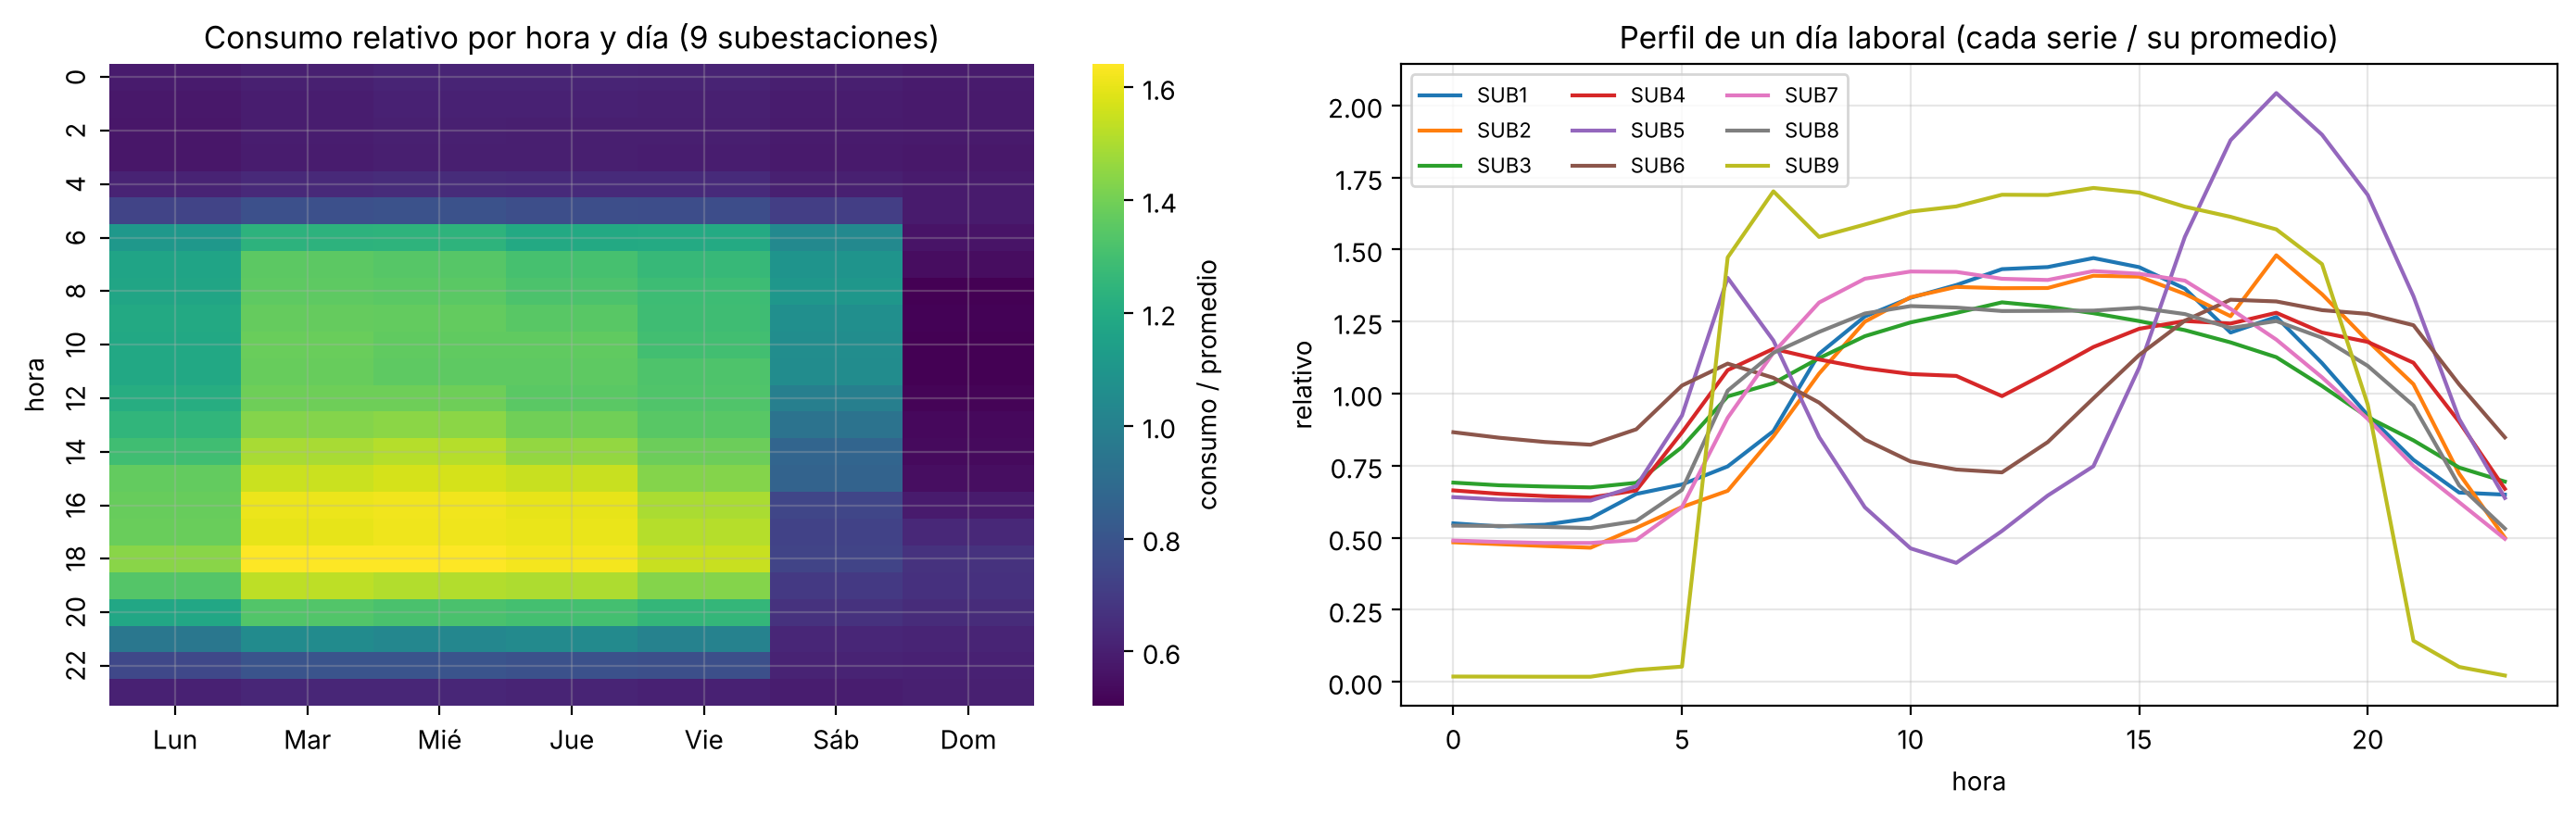

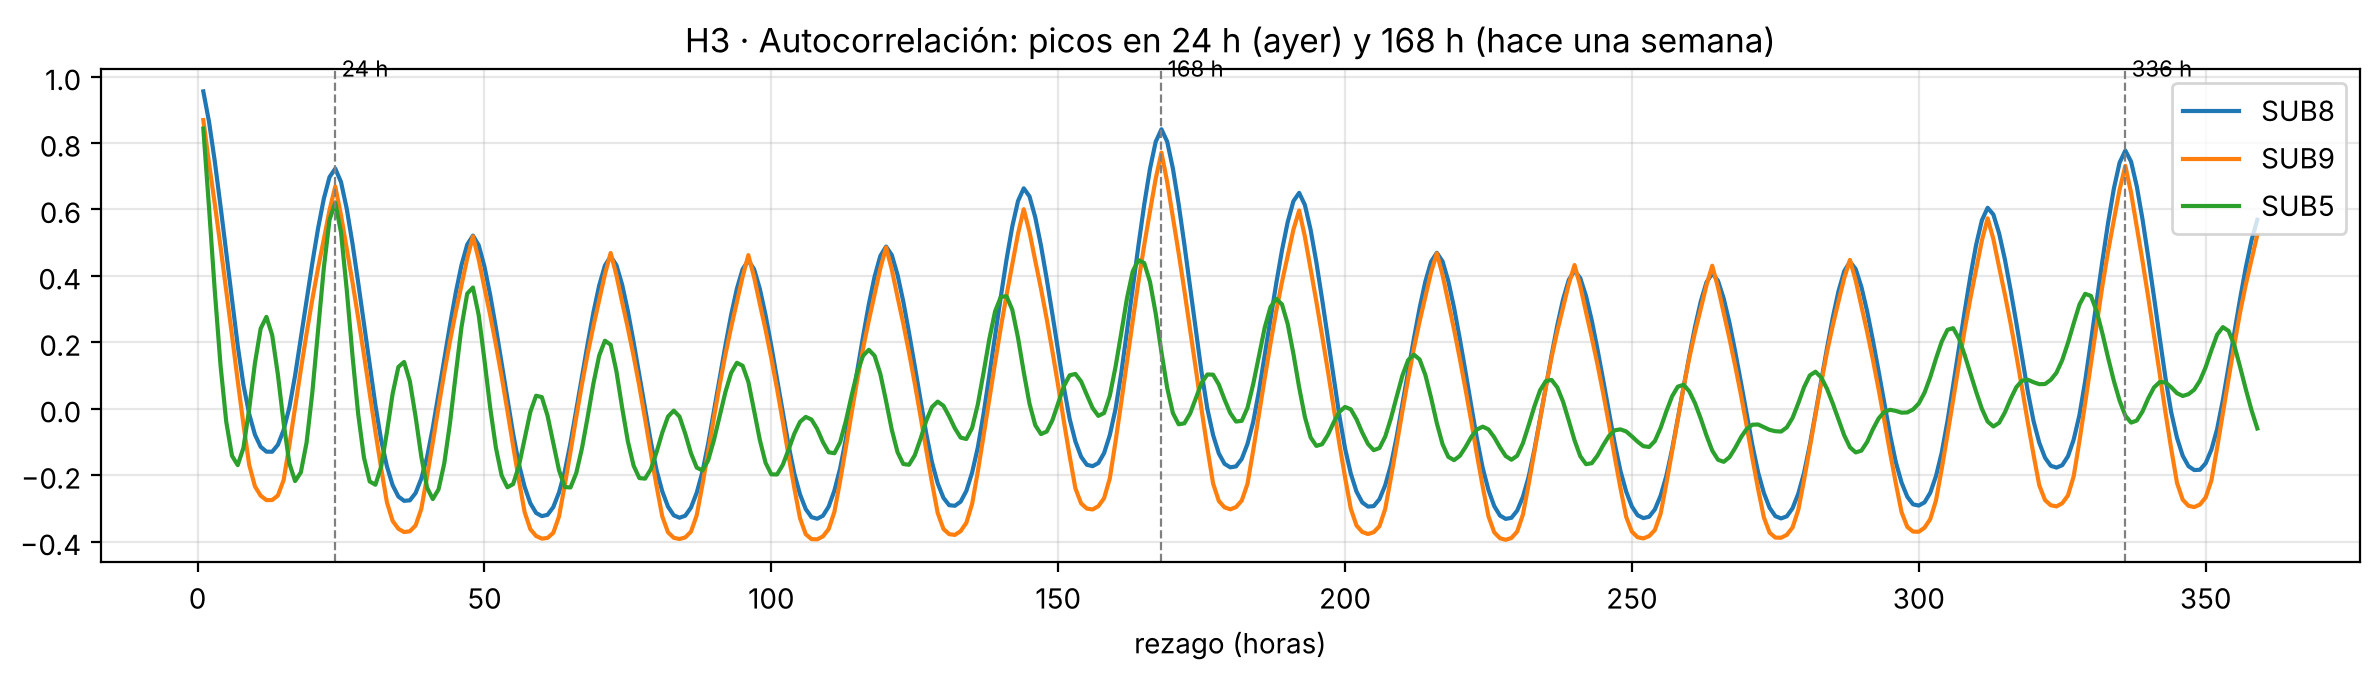

In [7]:
# =============================================================================
# 3.4 H3: Perfiles por hora y día de la semana + autocorrelación (ACF)
# =============================================================================
largo = limpio_rapido.stack().rename("kwh").reset_index()
largo["hora"] = largo.timestamp.dt.hour
largo["dia_semana"] = largo.timestamp.dt.dayofweek
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

# Heatmap hora × día de la semana, con cada subestación escalada a su propio promedio
perfil = (largo.assign(rel=lambda d: d.kwh / d.groupby("subestacion").kwh.transform("mean"))
               .groupby(["hora", "dia_semana"]).rel.mean().unstack())
perfil.columns = DIAS
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(perfil, cmap="viridis", ax=axes[0], cbar_kws={"label": "consumo / promedio"})
axes[0].set_title("Consumo relativo por hora y día (9 subestaciones)")

# Perfil diario de un día laboral por subestación (escala propia)
lab = largo[largo.dia_semana < 5]
prof = lab.groupby(["hora", "subestacion"]).kwh.mean().unstack()
(prof / prof.mean()).plot(ax=axes[1], legend=True)
axes[1].set_title("Perfil de un día laboral (cada serie / su promedio)"); axes[1].set_ylabel("relativo")
axes[1].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

# Autocorrelación: ¿qué tanto se parece el consumo a sí mismo k horas atrás?
def acf(s, lags):
    s = s.dropna(); return [s.corr(s.shift(k)) for k in lags]
lags = list(range(1, 24 * 15))
fig, ax = plt.subplots(figsize=(12, 3.5))
for k in ["SUB8", "SUB9", "SUB5"]:
    ax.plot(lags, acf(limpio_rapido[k].asfreq("h"), lags), label=k)
for v in [24, 168, 336]:
    ax.axvline(v, color="gray", ls="--", lw=0.8); ax.text(v, 1.0, f" {v} h", fontsize=8)
ax.set_title("H3 · Autocorrelación: picos en 24 h (ayer) y 168 h (hace una semana)")
ax.set_xlabel("rezago (horas)"); ax.legend(); plt.tight_layout(); plt.show()

**Hallazgos H3:**
- El consumo tiene un ciclo **diario** muy marcado (bajo de 22:00 a 5:00, alto de 7:00 a 18:00) y otro **semanal** (sábado más bajo, domingo el más bajo).
- La autocorrelación tiene picos en **24 h** y **168 h** (y 336 h): el mejor "parecido" de una hora es la misma hora de ayer y, sobre todo, la misma hora de la semana pasada.
- Cada subestación tiene **su propia forma**: SUB9 (climatización) arranca de golpe a las 6:00 y se apaga en la noche; **SUB5, SUB4 y SUB6 bajan al mediodía** (generación solar propia: la compra a la red cae cuando hay sol).

✅ **Decisión:** variables `lag_24`, `lag_48`, `lag_168`, `lag_336`, `hora` (también como seno/coseno para el modelo lineal), `dia_semana`, y un modelo que pueda aprender formas distintas por subestación (identificador `subestacion`).

### H4 — ¿El calendario académico y los festivos cambian el consumo?

tipo_dia,lun-vie,sábado,domingo,festivo
periodo,,,,
cierre,30880.0,24937.0,21283.0,22016.0
clases,51829.0,36411.0,27935.0,29073.0
intersemestral,44245.0,33564.0,26238.0,27569.0
receso,41740.0,31287.0,23679.0,27846.0


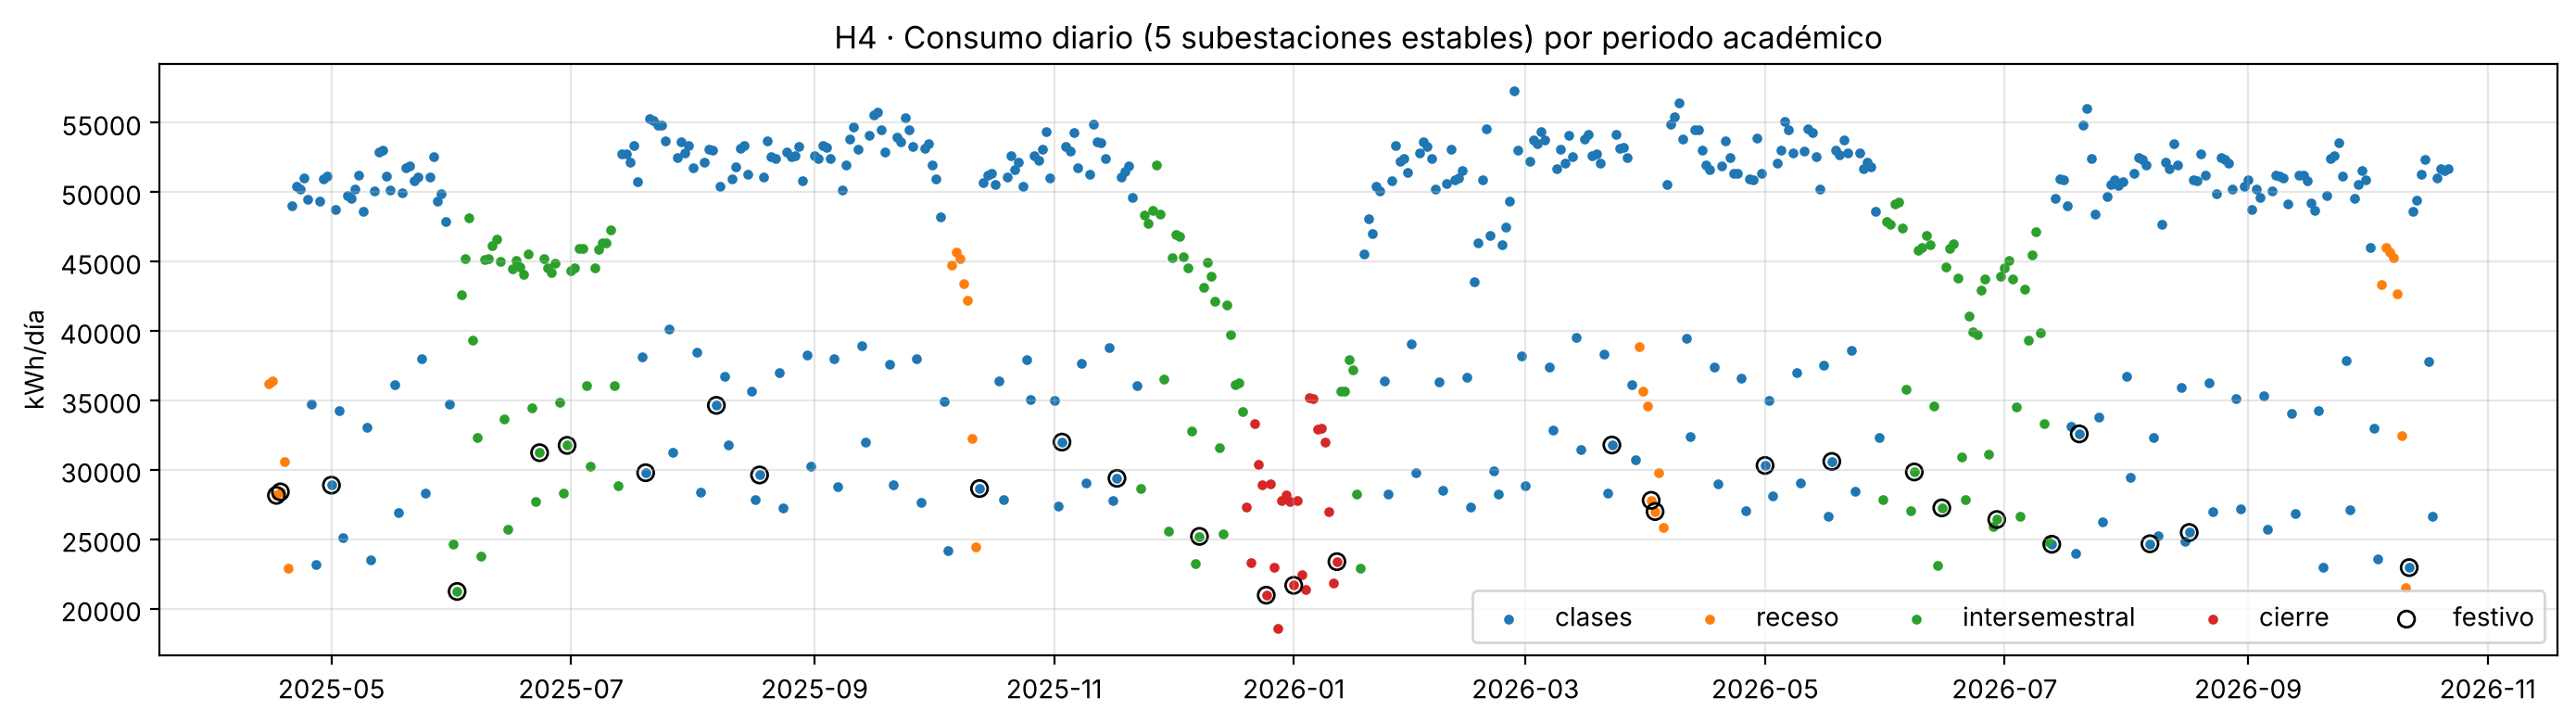

In [8]:
# =============================================================================
# 3.5 H4: Calendario académico y festivos
# =============================================================================
FESTIVOS = holidays.Colombia(years=[2025, 2026, 2027])

# Periodos académicos (Sección 1.4, supuesto S8). Las filas posteriores sobrescriben a las anteriores,
# por eso los recesos van después de su semestre.
# 2026: cronograma OFICIAL de pregrado (aprobado por el Consejo Académico el 22-abr-2026, con el ajuste de 2026-2).
# 2025: ESTIMADO trasladando 2026 exactamente 52 semanas (mismo día de la semana) y comprobado con el consumo;
#       Semana Santa con sus fechas reales y el cierre 2025 según la caída del consumo (desde el 20-dic).
# "clases" incluye las evaluaciones finales. Fuente común del proyecto: ref_calendario_academico.csv
PERIODOS = [
    ("2025-01-20", "2025-05-31", "clases"), ("2025-04-14", "2025-04-20", "receso"),          # 2025-1 (estimado) + Semana Santa real
    ("2025-06-01", "2025-07-13", "intersemestral"),
    ("2025-07-14", "2025-11-22", "clases"), ("2025-10-06", "2025-10-12", "receso"),          # 2025-2 (estimado, confirmado con el consumo)
    ("2025-11-23", "2025-12-19", "intersemestral"), ("2025-12-20", "2026-01-12", "cierre"),
    ("2026-01-13", "2026-01-18", "intersemestral"),
    ("2026-01-19", "2026-05-30", "clases"), ("2026-03-30", "2026-04-05", "receso"),          # 2026-1 oficial + Semana Santa
    ("2026-05-31", "2026-07-12", "intersemestral"),
    ("2026-07-13", "2026-11-21", "clases"), ("2026-10-05", "2026-10-11", "receso"),          # 2026-2 oficial
    ("2026-11-22", "2026-12-13", "intersemestral"), ("2026-12-14", "2027-01-11", "cierre"),
]
INICIO_SEMESTRE = pd.to_datetime(["2025-01-20", "2025-07-14", "2026-01-19", "2026-07-13"])

def calendario_diario(dias):
    # Devuelve, para cada día, todo lo que se sabe de él con anticipación (no hay fuga: es calendario).
    d = pd.DataFrame(index=pd.DatetimeIndex(dias).normalize())
    d["dia_semana"] = d.index.dayofweek
    d["festivo"] = [int(x.date() in FESTIVOS) for x in d.index]
    d["fin_semana"] = (d.dia_semana >= 5).astype(int)
    d["laboral"] = ((d.festivo == 0) & (d.fin_semana == 0)).astype(int)
    d["periodo"] = "intersemestral"
    for ini, fin, etiqueta in PERIODOS:
        d.loc[(d.index >= ini) & (d.index <= fin), "periodo"] = etiqueta
    # semana del semestre: 1 = primera semana de clases del semestre en curso
    d["semana_semestre"] = [((x - INICIO_SEMESTRE[INICIO_SEMESTRE <= x].max()).days // 7 + 1) for x in d.index]
    # puente: día no laboral dentro de un bloque de ≥3 días no laborales seguidos (fin de semana largo).
    # OJO: la racha se calcula con TODOS los días que se le pasen; por eso el calendario se calcula UNA sola vez
    # (CAL, abajo) y se reutiliza igual en entrenamiento, validación y pronóstico. No debe recortarse por fecha.
    nl = (d.laboral == 0).astype(int)
    racha = nl.groupby((nl != nl.shift()).cumsum()).transform("sum")
    d["puente"] = ((nl == 1) & (racha >= 3)).astype(int)
    return d

# CAL cubre hasta fin de 2026: festivos y periodos se conocen con meses de anticipación. Para pronosticar más allá
# habría que ampliar este rango (y PERIODOS / INICIO_SEMESTRE).
dias = pd.date_range("2025-04-01", "2026-12-31", freq="D")
CAL = calendario_diario(dias)

# Consumo diario total (subestaciones estables) según tipo de día y periodo
estables = ["SUB2", "SUB4", "SUB6", "SUB7", "SUB8"]
diario = limpio_rapido[estables].resample("D").mean().mean(axis=1).mul(24 * len(estables)).rename("kwh_dia").to_frame()
diario = diario.join(CAL)
diario["tipo_dia"] = np.where(diario.festivo == 1, "festivo",
                     np.where(diario.dia_semana == 5, "sábado", np.where(diario.dia_semana == 6, "domingo", "lun-vie")))
tabla_cal = diario.pivot_table(index="periodo", columns="tipo_dia", values="kwh_dia", aggfunc="mean").round(0)
display(tabla_cal[["lun-vie", "sábado", "domingo", "festivo"]])

fig, ax = plt.subplots(figsize=(14, 4))
colores = {"clases": "tab:blue", "receso": "tab:orange", "intersemestral": "tab:green", "cierre": "tab:red"}
for p, c in colores.items():
    sel = diario[diario.periodo == p]
    ax.scatter(sel.index, sel.kwh_dia, s=8, color=c, label=p)
fe = diario[diario.festivo == 1]
ax.scatter(fe.index, fe.kwh_dia, s=40, facecolors="none", edgecolors="k", label="festivo")
ax.set_title("H4 · Consumo diario (5 subestaciones estables) por periodo académico"); ax.set_ylabel("kWh/día")
ax.legend(ncol=5); plt.tight_layout(); plt.show()

**Hallazgos H4:**
- En **clases** un día lun-vie consume claramente más que en **intersemestral**, **receso** o **cierre** (fin de diciembre es el punto más bajo del año).
- Un **festivo** consume como un domingo, aunque caiga lunes.
- El cierre de mediados de 2026 que la universidad no tenía claro **no aparece** en los datos como cierre total: junio-julio de 2026 se comporta como intersemestral. Lo dejamos así.

✅ **Decisión:** variables `festivo`, `fin_semana`, `laboral`, `puente`, `periodo` (clases/receso/intersemestral/cierre) y `semana_semestre`. Todas se conocen **con anticipación** → no hay fuga.

### H5 — La "trampa del lunes festivo": ¿el consumo de ayer siempre es buena pista?

In [9]:
# =============================================================================
# 3.6 H5: El rezago de 24 h falla después de un festivo o un fin de semana
# =============================================================================
# Comparamos el error de dos reglas simples SOLO en días laborales:
#   - "lag_24": mañana = ayer a la misma hora
#   - "mismo tipo": mañana = último día del MISMO TIPO (laboral/no laboral) a la misma hora
d = diario[["kwh_dia", "laboral"]].dropna().copy()
ultimo = {0: None, 1: None}; prev_mismo = []
for fecha, fila in d.iterrows():                     # recorremos los días en orden
    prev_mismo.append(ultimo[fila.laboral]); ultimo[fila.laboral] = fecha
d["prev_mismo_tipo"] = prev_mismo
d["ayer"] = d.kwh_dia.shift(1)
d["mismo_tipo"] = d.prev_mismo_tipo.map(d.kwh_dia)
d["ayer_laboral"] = d.laboral.shift(1)
lab = d[(d.laboral == 1)].dropna()
res = pd.DataFrame({
    "error % usando lag_24": lab.groupby("ayer_laboral").apply(lambda g: (abs(g.kwh_dia - g.ayer) / g.kwh_dia).mean() * 100),
    "error % usando mismo tipo de día": lab.groupby("ayer_laboral").apply(lambda g: (abs(g.kwh_dia - g.mismo_tipo) / g.kwh_dia).mean() * 100),
    "n_días": lab.groupby("ayer_laboral").size()}).round(1)
res.index = ["ayer NO fue laboral (lunes, martes post-festivo)", "ayer fue laboral"]
res

,error % usando lag_24,error % usando mismo tipo de día,n_días
"ayer NO fue laboral (lunes, martes post-festivo)",42.3,5.1,83
ayer fue laboral,2.8,2.8,286


**Hallazgo H5:** cuando **ayer no fue laboral** (todos los lunes y los días después de un festivo), copiar "ayer" se equivoca muchísimo, porque ayer fue un domingo o festivo. En cambio, copiar el **último día del mismo tipo** reduce mucho ese error.

✅ **Decisión:** crear la variable `lag_mismo_tipo` (último día laboral si mañana es laboral; último día no laboral si mañana no lo es) y las banderas `ayer_laboral` y `hace7_laboral`, para que el modelo sepa cuándo desconfiar de `lag_24` y `lag_168`. Todo usa solo calendario y datos pasados.

### H6 — ¿Las subestaciones tienen escalas distintas? ¿Hay cambios de régimen?

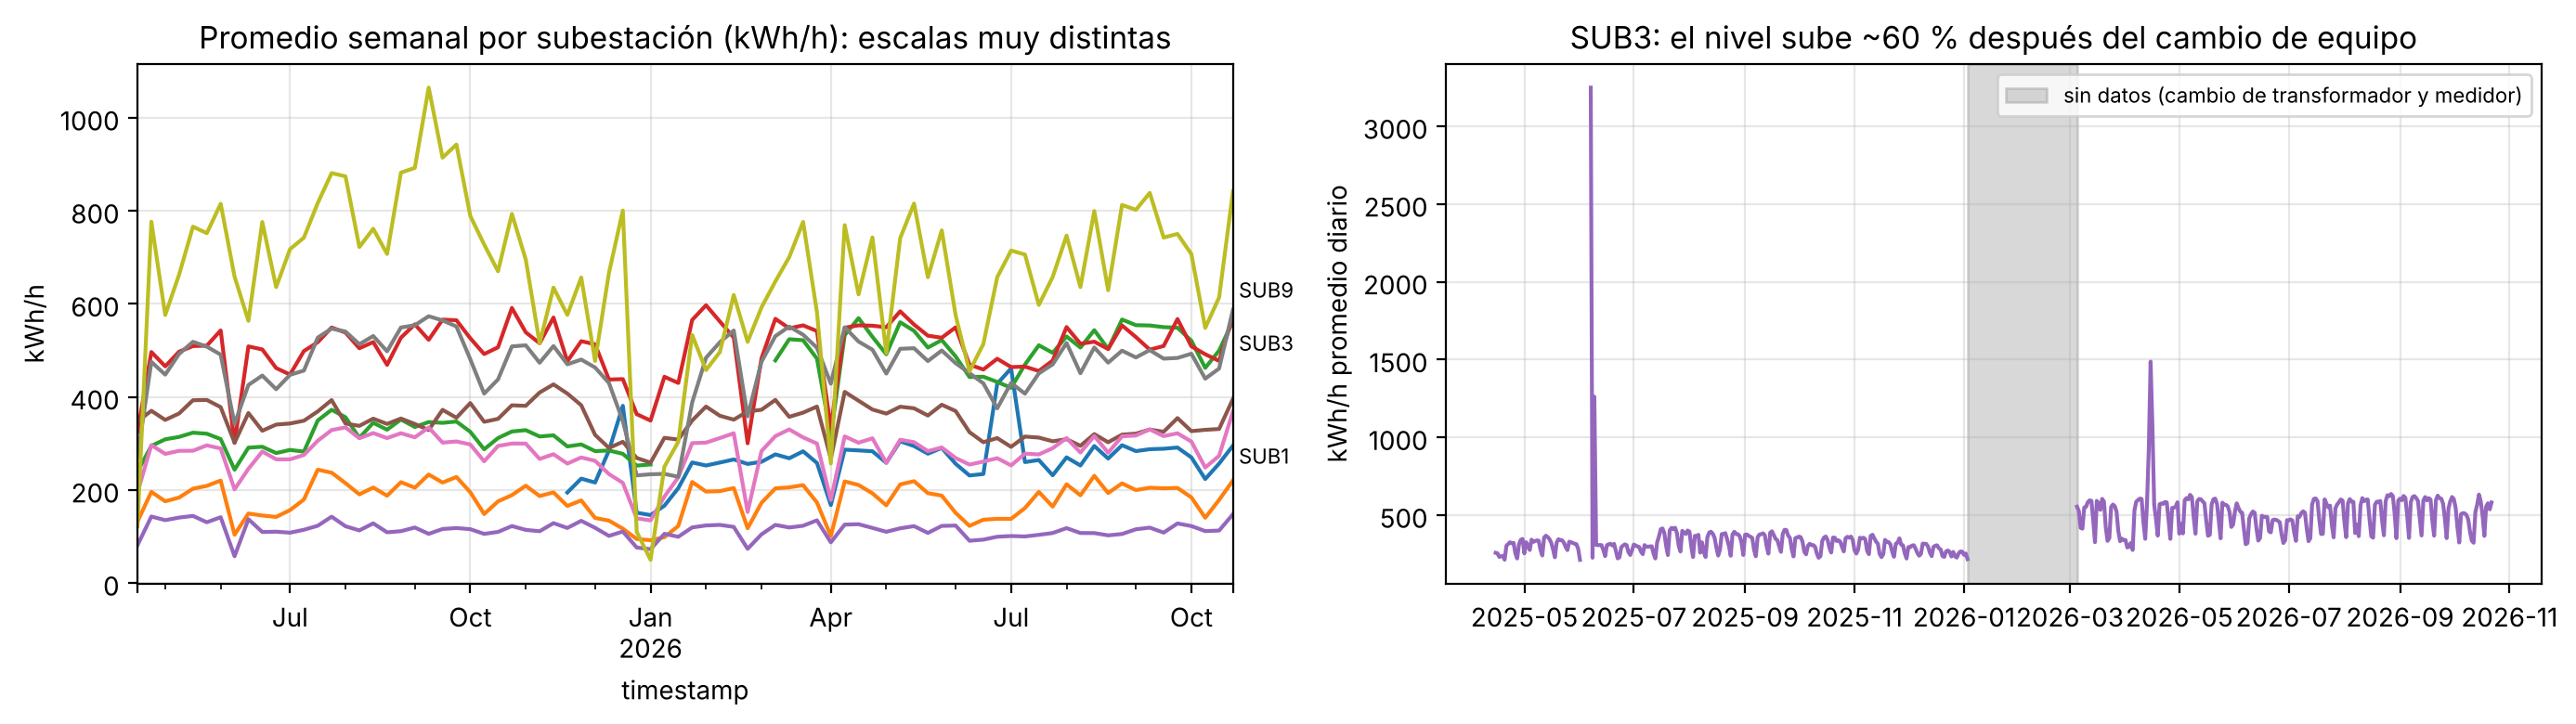

SUB3 promedio antes del cambio: 318.9 | después: 511.3 kWh/h


In [10]:
# =============================================================================
# 3.7 H6: Escalas distintas y cambio de régimen (SUB3)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
semanal = limpio_rapido.resample("W").mean()
semanal.plot(ax=axes[0], legend=False)
axes[0].set_title("Promedio semanal por subestación (kWh/h): escalas muy distintas"); axes[0].set_ylabel("kWh/h")
for k in ["SUB9", "SUB3", "SUB1"]:
    axes[0].text(semanal.index[-1], semanal[k].iloc[-2], f" {k}", fontsize=8)
b18 = ancho_crudo["SUB3"].where(ancho_crudo["SUB3"] > 0).resample("D").mean()
axes[1].plot(b18.index, b18.values, color="tab:purple")
axes[1].axvspan(pd.Timestamp("2026-01-03"), pd.Timestamp("2026-03-05"), color="gray", alpha=0.3, label="sin datos (cambio de transformador y medidor)")
axes[1].set_title("SUB3: el nivel sube ~60 % después del cambio de equipo"); axes[1].set_ylabel("kWh/h promedio diario")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
print("SUB3 promedio antes del cambio:", round(ancho_crudo.loc[:"2026-01-02", "SUB3"].mean(), 1),
      "| después:", round(ancho_crudo.loc["2026-03-05":, "SUB3"].mean(), 1), "kWh/h")

**Hallazgos H6:**
- SUB9 consume ~4 veces lo que consume SUB5. Si entrenamos un solo modelo con kWh "crudos", **las series grandes dominan** el aprendizaje y el error.
- SUB3 **sube cerca de 60 %** su nivel después del cambio de transformador y medidor. Los datos anteriores describen "otra máquina".

✅ **Decisiones:**
1. **SUB3 se usa solo desde el 5-mar-2026** (régimen nuevo).
2. **Normalización por nivel reciente:** dividimos el objetivo y los rezagos por `nivel_7d` (consumo promedio por hora de los últimos 7 días, conocido a medianoche). El modelo aprende *formas relativas* ("a las 15:00 de un martes de clases se consume 1,4 veces el nivel de la semana") que se comparten entre subestaciones. Luego multiplicamos de vuelta. Es la versión dinámica del "escalar por serie" de la Sesión 3, y **no tiene fuga** porque el nivel se calcula solo con el pasado.
3. **Modelo global:** un solo modelo para las 9 series, con `subestacion` como variable. Ayuda a las series con poca historia (SUB3 y SUB1). Se compara contra modelos locales en la Sección 7.

### H7 — ¿El clima explica el consumo?

Origen del clima: archivo ../datos/clima_nasa_power_eafit.csv
Clima disponible: 2025-04-01 00:00:00 → 2026-10-31 23:00:00
Radiación disponible hasta: 2026-08-30 23:00:00
Variabilidad de la temperatura máxima diaria: desviación estándar = 1.6 °C


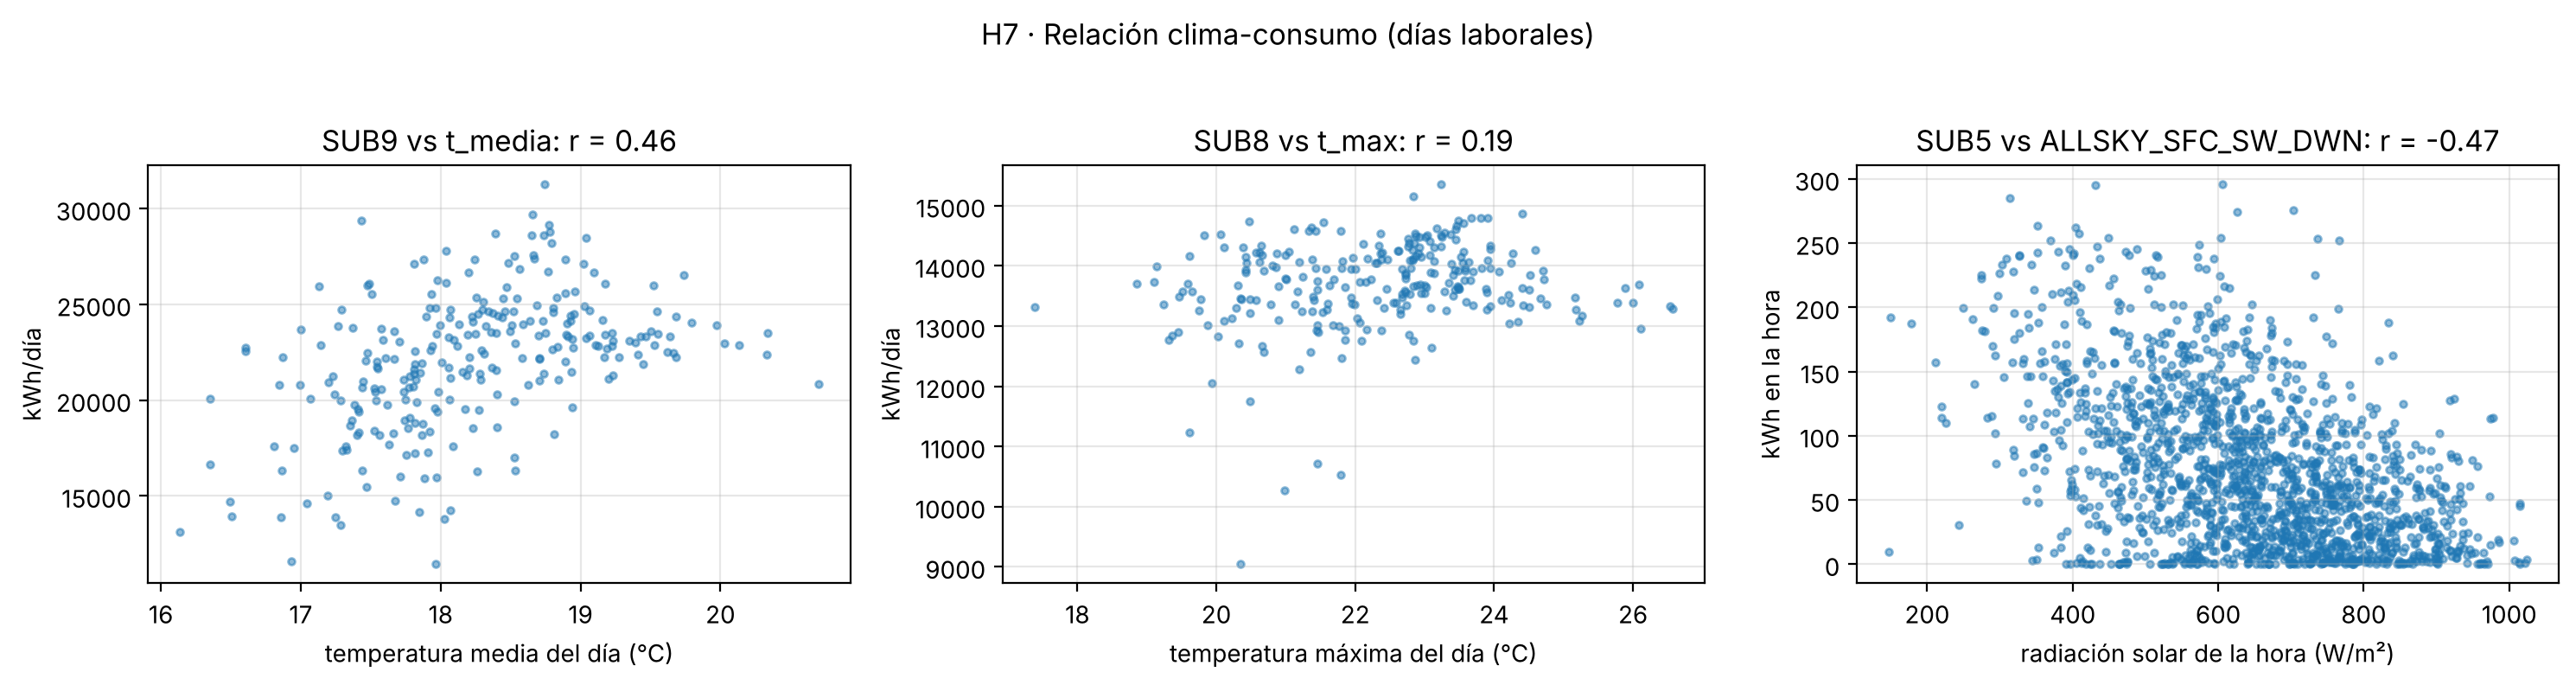

In [11]:
# =============================================================================
# 3.8 H7: Clima (NASA POWER, fuente pública) vs consumo
# =============================================================================
# NASA POWER entrega clima horario (reanálisis satelital MERRA-2/CERES) en las coordenadas del campus.
# El pipeline lo ingiere en Databricks; aquí se lee de esa tabla (el archivo original queda como respaldo).
clima = cargar_clima()
print("Origen del clima:", ORIGEN["clima"])
if MODO_LECTURA != "local" and ARCHIVOS["clima"].exists():      # control de integridad, como en 3.1
    clima_archivo = pd.read_csv(ARCHIVOS["clima"], parse_dates=["timestamp"]).set_index("timestamp")
    display(pd.DataFrame([comparar_con_archivo("clima", clima, clima_archivo.mask(clima_archivo <= -999))]))
clima_d = clima.resample("D").agg({"T2M": ["mean", "max"], "PRECTOTCORR": "sum", "ALLSKY_SFC_SW_DWN": "sum"})
clima_d.columns = ["t_media", "t_max", "precip", "radiacion"]
print("Clima disponible:", clima.index.min(), "→", clima.index.max())
print("Radiación disponible hasta:", clima.ALLSKY_SFC_SW_DWN.last_valid_index())

# (a) Consumo DIARIO en días laborales de clases vs temperatura
dd = limpio_rapido.resample("D").sum(min_count=20).join(clima_d).join(CAL)
dd = dd[(dd.laboral == 1) & (dd.periodo == "clases")]
# (b) Compra HORARIA al mediodía (10-14 h, días laborales) vs radiación solar de esa hora
mediodia = limpio_rapido[["SUB5"]].join(clima.ALLSKY_SFC_SW_DWN).dropna()
mediodia = mediodia[(mediodia.index.hour >= 10) & (mediodia.index.hour <= 14) & (mediodia.index.dayofweek < 5)]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (tabla_xy, serie, var, etiqueta) in zip(axes, [(dd, "SUB9", "t_media", "temperatura media del día (°C)"),
                                                       (dd, "SUB8", "t_max", "temperatura máxima del día (°C)"),
                                                       (mediodia, "SUB5", "ALLSKY_SFC_SW_DWN", "radiación solar de la hora (W/m²)")]):
    sub = tabla_xy[[serie, var]].dropna()
    ax.scatter(sub[var], sub[serie], s=8, alpha=0.5)
    ax.set_title(f"{serie} vs {var}: r = {sub[serie].corr(sub[var]):.2f}")
    ax.set_xlabel(etiqueta); ax.set_ylabel("kWh/día" if tabla_xy is dd else "kWh en la hora")
print(f"Variabilidad de la temperatura máxima diaria: desviación estándar = {clima_d.t_max.std():.1f} °C")
plt.suptitle("H7 · Relación clima-consumo (días laborales)", y=1.03); plt.tight_layout(); plt.show()

**Hallazgos H7:**
- **SUB9 (climatización)** sí sube en los días más calurosos (correlación moderada, r ≈ 0,4). En **SUB8** la relación es débil.
- Pero Medellín tiene un clima muy estable: la temperatura máxima diaria apenas varía (desviación estándar ≈ 1,6 °C), y el clima de un día se parece mucho al de los días anteriores. Por eso es probable que los rezagos de consumo (ayer, semana pasada) **ya contengan** casi toda la información del clima.
- En **SUB5** (con generación solar propia), a la misma hora del mediodía, **más radiación solar → menos compra a la red** (r ≈ −0,5). El sol "esconde" parte del consumo (supuesto S1).

⚠️ **Restricción de fuga:** para pronosticar mañana solo podemos usar el clima **pronosticado** de mañana o el **observado de ayer**. No existe un archivo histórico gratuito y completo de pronósticos, y la radiación de NASA POWER solo llega hasta agosto de 2026.

✅ **Decisión:** probar en validación (Sección 7) tres versiones: sin clima, con clima observado de **ayer** (válido) y con clima observado del **mismo día** (un "oráculo" que **no es desplegable**, solo mide cuánto ganaríamos con un pronóstico meteorológico perfecto). Los datos deciden, pero la conclusión se limita a **las variables probadas** (temperatura media y máxima, precipitación, temperatura horaria; NASA POWER) y a su desempeño en validación: no se afirma que "el clima no importe" en general.

---
# 4. Preparación de los datos: limpieza

🧠 **Idea dummie:** si le enseñamos al modelo con datos falsos (un pico cientos de veces mayor que lo normal), aprende cosas falsas. Pero si "arreglamos" datos inventando valores, también lo engañamos. Por eso: **borramos lo imposible y no inventamos el objetivo**.

## 4.1 Reglas de limpieza (en este orden)

| Regla | Qué marca como faltante | Por qué |
|---|---|---|
| R1 · Cero o negativo | kWh ≤ 0 | La universidad confirmó que son errores; un edificio nunca compra 0 ni energía negativa en una hora. |
| R2 · Supera la capacidad física | kWh > kVA del transformador | Un transformador de X kVA no puede entregar más de X kWh en una hora. Para SUB3 después del cambio de equipo no conocemos la nueva capacidad, así que R2 no se aplica ahí. |
| R4 · Régimen anterior de SUB3 | SUB3 antes del 5-mar-2026 | Otro transformador y otro medidor (H6). Se aplica **antes** de R3 para que el percentil de R3 no mezcle dos regímenes. |
| R3 · Pico aislado (**causal**) | kWh > 2 × mediana de las **6 horas anteriores** (se exigen ≥ 3 con dato) **y** > 1,5 × el percentil 99 del **histórico anterior** de esa serie (se exigen ≥ 30 días de historia válida) | Detecta acumulaciones del medidor (ej.: 20-ago-2026 21:00 en SUB1, SUB2 y SUB5 a la vez). **No se aplica a SUB9**: la climatización arranca de golpe a las 6:00 y la regla confundiría ese arranque normal con un error. |

🧠 **Regla de oro de la limpieza (corrección de la versión anterior):** *el estado de cada hora solo puede depender de esa hora y de horas anteriores.* La primera versión de R3 miraba 3 horas **hacia adelante** y usaba el percentil 99 de **toda** la serie (incluido el futuro). Eso es una fuga: a la medianoche esas horas todavía no existen. Ahora R3 usa únicamente el pasado, así que limpiar con los datos hasta las 23:00 da **exactamente** las mismas marcas que limpiar con la serie completa. Lo demostramos en 4.1b y en la prueba de fuga de la sección 5.4 (que ahora parte de los **datos crudos**, no de los ya limpiados).

🔍 **Lección de diseño (con evidencia):** una primera versión causal exigía solo superar el percentil 99 histórico. Descartaba decenas de horas **legítimas** (el primer valor alto de cada subida normal de la mañana en SUB1, SUB5 y SUB7), porque mirando solo hacia atrás una subida normal se parece a un pico. Exigir **1,5 × el percentil 99** deja pasar las subidas normales y conserva el descarte de los picos imposibles (los tres del 20-ago-2026 21:00 y el de SUB6 del 15-feb-2026).

🔶 **Costo honesto de mirar solo el pasado:** la regla causal descarta además **3 horas de SUB3** (14 y 15-abr-2026) que la regla anterior conservaba, porque son el **arranque** de una subida sostenida (la posible transferencia de carga SUB9 → SUB3, hipótesis sin confirmar). Mirando solo hacia atrás, el primer valor de una subida real es indistinguible de un pico. Son 3 horas de ≈ 104 000 (0,003 %), todas en abril (periodo de desarrollo, no en el test). Y la anterior descartaba 1 hora de SUB6 (1-jun-2025) que la causal conserva.

⚠️ **Límite conocido de una regla causal:** el **primer** valor después de un hueco largo no tiene horas previas con las que compararse (R3 no se evalúa); solo lo protegen R1 y R2 (cero, negativo, supera la capacidad). Es el precio de no mirar el futuro; en 4.1b medimos cuántos casos son.

✅ **No rellenamos (no imputamos) el objetivo.** Las horas faltantes no se usan para entrenar ni para evaluar. **No se pierde información**: cada valor descartado queda en `registro_limpieza` con su valor original y el motivo. Las **variables** sí pueden quedar vacías (NaN): LightGBM las maneja de forma nativa y para Ridge/Random Forest se imputa la mediana **dentro del pipeline**, con datos de entrenamiento únicamente.

| ❓ Pregunta | 🔧 Qué hace el código | 🎯 Por qué | 📖 Cómo interpretarlo |
|---|---|---|---|
| ¿Qué datos son errores y no consumo? | Aplica R1→R2→R4→R3 y guarda motivo y valor original | Entrenar con datos falsos enseña cosas falsas; inventar valores también engaña | La tabla resumen cuenta cuántas horas cayó cada regla; `registro_limpieza` permite auditar una por una |

subestacion,SUB1,SUB2,SUB3,SUB4,SUB5,SUB6,SUB7,SUB8,SUB9
R1_cero_o_negativo,1,1,0,1,336,5,0,0,0
R2_supera_capacidad,2,5,2,5,5,0,4,4,1
R3_pico_aislado,1,1,3,0,1,1,0,0,0
R4_regimen_anterior_SUB3,0,0,6143,0,0,0,0,0,0
nulo_original,5442,535,1645,404,542,42,481,442,96
ok,7898,12802,5551,12934,12460,13296,12859,12898,13247


Horas con dato válido para entrenar/evaluar: 103945 de 120096
Ejemplo del registro de limpieza (se conserva el valor original y el motivo):


,timestamp,subestacion,kwh_original,motivo
6337,2026-02-15 19:00:00,SUB6,1129.000,R3_pico_aislado
6386,2026-04-14 15:00:00,SUB3,1850.875,R3_pico_aislado
6387,2026-04-14 16:00:00,SUB3,1748.250,R3_pico_aislado
6388,2026-04-15 08:00:00,SUB3,2471.250,R3_pico_aislado
6477,2026-08-20 21:00:00,SUB1,1065.488,R3_pico_aislado
6478,2026-08-20 21:00:00,SUB2,898.980,R3_pico_aislado


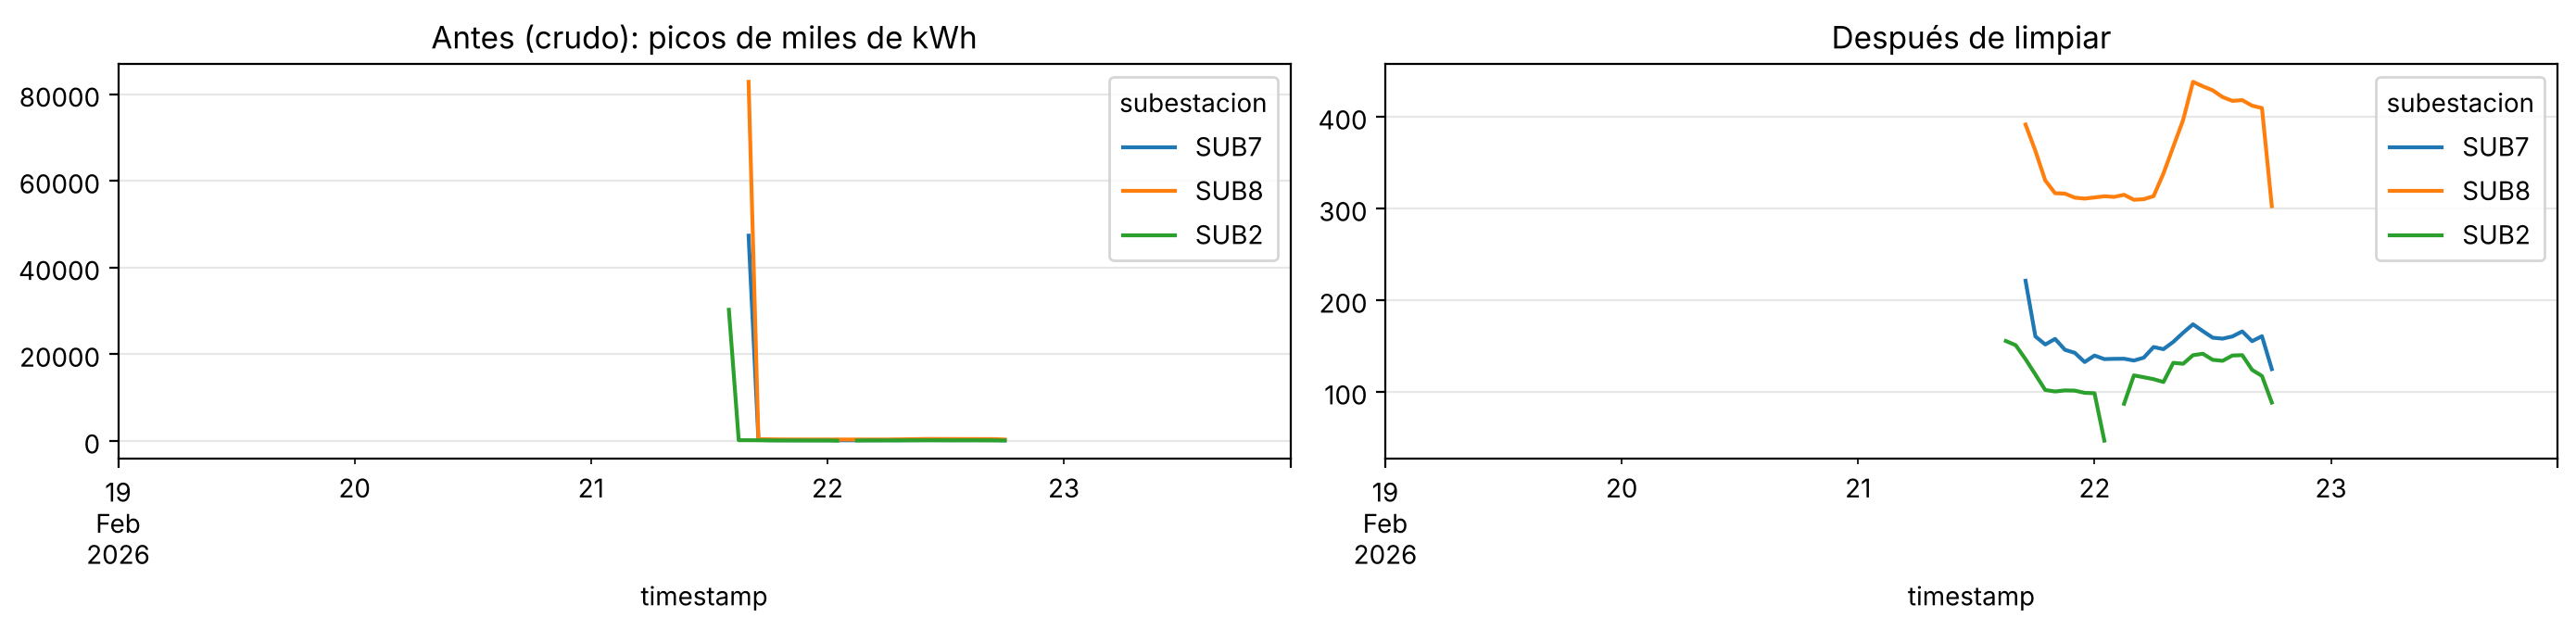

In [12]:
# =============================================================================
# 4.1 Función de limpieza (reproducible: misma entrada → misma salida)
# =============================================================================
FECHA_CAMBIO_SUB3 = pd.Timestamp("2026-03-05")
MIN_HORAS_HISTORIA_R3 = 24 * 30      # R3 no se evalúa hasta tener 30 días de historia válida de esa serie
FACTOR_P99_R3 = 1.5                  # R3 exige superar 1,5 x el percentil 99 del histórico. (Con 1,0 x la regla confundía
                                     # con "pico" el primer valor alto de cada subida normal de la mañana: ver 4.1b)

def limpiar_series(ancho, capacidad=CAPACIDAD_KVA):
    # Devuelve (series_limpias, banderas). 'banderas' dice por qué se borró cada valor.
    # LIMPIEZA CAUSAL: el estado de la hora t depende solo de las horas <= t (ninguna regla mira al futuro).
    limpio = ancho.copy()
    banderas = pd.DataFrame("ok", index=ancho.index, columns=ancho.columns)
    banderas[ancho.isna()] = "nulo_original"

    # R1: ceros y negativos
    m = limpio <= 0
    banderas[m] = "R1_cero_o_negativo"; limpio = limpio.mask(m)

    # R2: supera la capacidad física del transformador
    for k in limpio.columns:
        aplica = (limpio.index < FECHA_CAMBIO_SUB3) if k == "SUB3" else np.ones(len(limpio), bool)
        m = aplica & (limpio[k] > capacidad[k]).values
        banderas.loc[m, k] = "R2_supera_capacidad"; limpio.loc[m, k] = np.nan

    # R4: régimen anterior de SUB3 (va ANTES de R3 para que el percentil histórico no mezcle regímenes)
    antes = limpio.index < FECHA_CAMBIO_SUB3
    m = antes & limpio["SUB3"].notna().values
    banderas.loc[m, "SUB3"] = "R4_regimen_anterior_SUB3"; limpio.loc[antes, "SUB3"] = np.nan

    # R3: pico aislado, versión CAUSAL (solo mira horas anteriores; no se aplica a SUB9)
    for k in limpio.columns:
        if k == "SUB9":
            continue
        s = limpio[k]
        # mediana de las 6 horas ANTERIORES (shift(1) = hasta t-1); se exigen >= 3 con dato
        previas = s.shift(1).rolling(6, min_periods=3).median()
        # percentil 99 del HISTÓRICO anterior (hasta t-1); se exigen >= 30 días (720 h) con dato
        p99_hist = s.expanding(min_periods=MIN_HORAS_HISTORIA_R3).quantile(0.99).shift(1)
        m = ((s > 2 * previas) & (s > FACTOR_P99_R3 * p99_hist)).values   # si falta referencia el resultado es False: no se descarta
        banderas.loc[m, k] = "R3_pico_aislado"; limpio.loc[m, k] = np.nan
    return limpio, banderas

def registrar_limpieza(ancho, banderas):
    # Tabla larga con TODO lo que se descartó: valor original, motivo y marca de tiempo (auditable).
    largo_v = ancho.stack(future_stack=True).rename("kwh_original")
    largo_b = banderas.stack(future_stack=True).rename("motivo")
    reg = pd.concat([largo_v, largo_b], axis=1).reset_index()
    reg.columns = ["timestamp", "subestacion", "kwh_original", "motivo"]
    return reg[~reg.motivo.isin(["ok", "nulo_original"])].reset_index(drop=True)

limpio, banderas = limpiar_series(ancho_crudo)
registro_limpieza = registrar_limpieza(ancho_crudo, banderas)
resumen_limpieza = banderas.apply(lambda s: s.value_counts()).fillna(0).astype(int)
display(resumen_limpieza)
print("Horas con dato válido para entrenar/evaluar:", int(limpio.notna().sum().sum()), "de", limpio.size)
print("Ejemplo del registro de limpieza (se conserva el valor original y el motivo):")
display(registro_limpieza[registro_limpieza.motivo == "R3_pico_aislado"].head(6))

# Antes vs después en el caso del 21-feb-2026
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
v = slice("2026-02-19", "2026-02-23")
ancho_crudo.loc[v, ["SUB7", "SUB8", "SUB2"]].plot(ax=axes[0]); axes[0].set_title("Antes (crudo): picos de miles de kWh")
limpio.loc[v, ["SUB7", "SUB8", "SUB2"]].plot(ax=axes[1]); axes[1].set_title("Después de limpiar")
plt.tight_layout(); plt.show()

## 4.1b ¿La limpieza ahora es de verdad causal? ¿Cambió algo frente a la versión anterior?

Dos comprobaciones antes de atribuirle cualquier cambio de precisión a la corrección:

1. **Causalidad:** limpiamos la serie cruda **cortada** a las 23:00 de cada día del test (83 cortes) y comparamos las marcas de las horas ya conocidas con las de la limpieza sobre la serie completa. Si la regla es causal, **ninguna marca puede cambiar**.
2. **Efecto de la corrección:** reproducimos la regla R3 **anterior** (con 3 horas de futuro y percentil global) solo como referencia y contamos qué horas marcaba una regla y no la otra. Así sabemos cuánto cambió realmente el conjunto de datos antes de mirar las métricas.

In [13]:
# =============================================================================
# 4.1b Prueba de causalidad (83 cortes diarios) y comparación con la regla R3 anterior
# =============================================================================
t0 = time.time()
cortes_distintos = []
for dia in pd.date_range(INICIO_TEST, FIN_DATOS.normalize(), freq="D"):                 # un corte por emisión del test
    ultima_hora = dia - pd.Timedelta(hours=1)                                          # lo último que se conoce a las 00:00
    _, ban_corte = limpiar_series(ancho_crudo.loc[:ultima_hora])                       # limpieza SOLO con datos hasta las 23:00
    n_dif = int((ban_corte.values != banderas.loc[:ultima_hora].values).sum())         # ¿alguna marca distinta a la de la serie completa?
    if n_dif:
        cortes_distintos.append((dia.date(), n_dif))
print(f"Cortes diarios revisados: 83 ({(time.time()-t0):.0f} s). Cortes donde alguna marca cambia: {len(cortes_distintos)}")
print("→ La limpieza es causal ✅" if not cortes_distintos else f"⚠️ Hay fuga en la limpieza: {cortes_distintos[:5]}")

def limpiar_R3_version_anterior(ancho):
    # SOLO COMO REFERENCIA (no se usa en el modelo): R3 anterior = 3 horas futuras + percentil 99 de TODA la serie.
    lim = ancho.where((ancho > 0) & ancho.le(pd.Series(CAPACIDAD_KVA)[ancho.columns], axis=1))
    lim.loc[lim.index < FECHA_CAMBIO_SUB3, "SUB3"] = np.nan
    marcas = {}
    for k in lim.columns:
        if k == "SUB9":
            continue
        s = lim[k]
        vecinos = pd.concat([s.shift(i) for i in (-3, -2, -1, 1, 2, 3)], axis=1).median(axis=1)
        marcas[k] = (s > 2 * vecinos) & (s > s.quantile(0.99))
    return pd.DataFrame(marcas)

r3_anterior = limpiar_R3_version_anterior(ancho_crudo)
r3_nuevo = (banderas.drop(columns="SUB9") == "R3_pico_aislado")
comparacion_r3 = pd.DataFrame({
    "marcadas por R3 anterior": r3_anterior.sum(),
    "marcadas por R3 causal": r3_nuevo.sum(),
    "solo la anterior": (r3_anterior & ~r3_nuevo).sum(),
    "solo la causal": (~r3_anterior & r3_nuevo).sum()})
display(comparacion_r3.T)
solo_ant = r3_anterior & ~r3_nuevo
print(f"Horas que R3 anterior descartaba y la causal conserva: {int(solo_ant.values.sum())} de {int(ancho_crudo.notna().sum().sum()):,} horas con dato "
      f"({100*solo_ant.values.sum()/ancho_crudo.notna().sum().sum():.4f} %)")
# Cuántas de esas horas son 'primer dato después de un hueco' (la limitación de una regla causal)
tras_hueco = ancho_crudo.shift(1).isna() & ancho_crudo.shift(2).isna() & ancho_crudo.shift(3).isna()
print("De ellas, primer dato tras un hueco de ≥ 3 horas:", int((solo_ant & tras_hueco.reindex(columns=solo_ant.columns)).values.sum()))
solo_nuevo = ~r3_anterior & r3_nuevo
print(f"Horas que la regla causal descarta y la anterior conservaba: {int(solo_nuevo.values.sum())}")
def listar(marcas, titulo):
    ii, jj = np.where(marcas.values)                                      # posiciones (hora, columna) marcadas
    print(titulo)
    display(pd.DataFrame({"timestamp": marcas.index[ii], "subestacion": marcas.columns[jj],
                          "kwh_crudo": [ancho_crudo.loc[marcas.index[i], marcas.columns[j]] for i, j in zip(ii, jj)]}))
listar(solo_ant, "Solo la regla ANTERIOR las descartaba:")
listar(solo_nuevo, "Solo la regla CAUSAL las descarta (arranque de una subida sostenida de SUB3: no se puede distinguir de un pico mirando solo el pasado):")

Cortes diarios revisados: 83 (9 s). Cortes donde alguna marca cambia: 0
→ La limpieza es causal ✅


,SUB1,SUB2,SUB3,SUB4,SUB5,SUB6,SUB7,SUB8
marcadas por R3 anterior,1,1,0,0,1,2,0,0
marcadas por R3 causal,1,1,3,0,1,1,0,0
solo la anterior,0,0,0,0,0,1,0,0
solo la causal,0,0,3,0,0,0,0,0


Horas que R3 anterior descartaba y la causal conserva: 1 de 110,467 horas con dato (0.0009 %)
De ellas, primer dato tras un hueco de ≥ 3 horas: 1
Horas que la regla causal descarta y la anterior conservaba: 3
Solo la regla ANTERIOR las descartaba:


,timestamp,subestacion,kwh_crudo
0,2025-06-01 13:00:00,SUB6,623.5


Solo la regla CAUSAL las descarta (arranque de una subida sostenida de SUB3: no se puede distinguir de un pico mirando solo el pasado):


,timestamp,subestacion,kwh_crudo
0,2026-04-14 15:00:00,SUB3,1850.875
1,2026-04-14 16:00:00,SUB3,1748.250
2,2026-04-15 08:00:00,SUB3,2471.250


## 4.1c ¿La limpieza del modelo y la de Databricks cuentan la misma historia?

El pipeline marca la calidad de cada hora en Silver (para el tablero y la conciliación) y el modelo limpia por su cuenta,
de forma causal. Son dos usos distintos, así que no tienen que coincidir hora por hora, pero las diferencias deben ser
**explicables**:

- **R4 (régimen anterior de SUB3):** el modelo descarta SUB3 antes del 5-mar-2026 porque era otro transformador y otro medidor;
  para Silver esas lecturas son válidas (son reales), solo pertenecen a otro tramo del medidor.
- **R3 (pico aislado):** el modelo solo puede comparar con el pasado; Silver puede usar la serie completa. Algunos picos los
  detecta solo uno de los dos (ver 4.1b: el costo de ser causal).
- **Horas que Silver rellena (huecos cortos):** el modelo no rellena el objetivo: esa hora simplemente no se usa.

La tabla cruza la decisión del modelo (filas) con la marca de Silver (columnas) en todas las horas con lectura original.

In [14]:
# =============================================================================
# 4.1c Coherencia con las marcas de calidad de Databricks (Silver)
# =============================================================================
# Silver describe la calidad de TODA la historia (para el tablero y la conciliación); el modelo limpia de forma
# causal (solo con el pasado de cada hora). No tienen que coincidir hora por hora, pero sí deben contar la misma
# historia: lo que el modelo descarta debería estar marcado también en Silver, salvo diferencias explicables.
MARCAS_OK_SILVER = {"OK", "VALIDO", "VÁLIDO", "VALID", "TRUE"}       # valores de la marca que significan "hora válida"
if MARCAS_SILVER is None:
    print("Esta comparación necesita leer de Databricks (la tabla de consumo de Silver con su marca de calidad).\n"
          f"Modo actual: {MODO_LECTURA}. Con FUENTE = 'auto' dentro de Databricks, o con credenciales, se calcula sola.")
else:
    con_dato = ancho_crudo.notna().stack()                        # solo horas con lectura original
    cruce = pd.DataFrame({"limpieza del modelo": banderas.stack(),
                          "marca de Silver": MARCAS_SILVER.reindex_like(banderas).astype("string")
                                                         .fillna("(sin marca)").stack()})[con_dato]
    display(pd.crosstab(cruce["limpieza del modelo"], cruce["marca de Silver"], margins=True, margins_name="total"))
    modelo_descarta = cruce["limpieza del modelo"] != "ok"
    silver_descarta = ~cruce["marca de Silver"].str.upper().isin(MARCAS_OK_SILVER)
    resumen_cruce = pd.Series({
        "ambos la aceptan": int((~modelo_descarta & ~silver_descarta).sum()),
        "ambos la descartan": int((modelo_descarta & silver_descarta).sum()),
        "solo Silver la descarta": int((~modelo_descarta & silver_descarta).sum()),
        "solo el modelo la descarta": int((modelo_descarta & ~silver_descarta).sum()),
    }, name="horas con lectura")
    display(resumen_cruce.to_frame())
    print(f"Coinciden en {100 * (modelo_descarta == silver_descarta).mean():.2f} % de las horas con lectura.")
    print("Horas que solo el modelo descarta, por motivo:")
    display(cruce[modelo_descarta & ~silver_descarta].groupby("limpieza del modelo").size().rename("horas").to_frame())


Esta comparación necesita leer de Databricks (la tabla de consumo de Silver con su marca de calidad).
Modo actual: local. Con FUENTE = 'auto' dentro de Databricks, o con credenciales, se calcula sola.


## 4.2 Días atípicos (posibles eventos): componente no supervisado

No tenemos agenda de eventos (supuesto S7). Siguiendo la recomendación del docente, los buscamos en el histórico con **dos métodos** que se complementan:

- **Método A — regla 1,5×:** una hora es "alta" si consume más de 1,5 veces lo típico **para ese tipo de día y esa hora** y el exceso es relevante (> 50 % del nivel horario de la semana anterior). "Lo típico" es la mediana de los **4 días anteriores del mismo tipo** (los 4 martes anteriores para un martes; los 4 domingos o festivos anteriores para un festivo). Así un lunes después de varios lunes festivos no parece "atípico" por error. Un día es **atípico** si tiene al menos 3 horas altas. Solo usa el pasado.
- **Método B — k-means sobre perfiles diarios:** cada día de cada subestación se convierte en un vector de 24 números (su curva). k-means agrupa curvas parecidas. Un día laboral que cae en el grupo de "curvas de domingo", o un domingo que cae en el grupo de "curvas de día de clases", es sospechoso.

⚠️ Este análisis es **descriptivo**: no se usa como variable de entrada del modelo (no sabríamos a medianoche si mañana será atípico). Sirve para (1) decidir si entrenar con o sin esos días y (2) **reportar el error por separado** en días normales y atípicos.

In [15]:
# =============================================================================
# 4.2a Método A: regla 1,5× (solo usa el pasado para definir "lo típico")
# =============================================================================
def tipo_de_dia(fechas):
    # Tipo de día para comparar "peras con peras": lunes..sábado laborales por separado y
    # un solo grupo para domingos y festivos (ambos sin actividad académica).
    c = CAL.reindex(pd.DatetimeIndex(fechas).normalize())
    return np.where((c.festivo == 1) | (c.dia_semana == 6), "domingo/festivo", c.dia_semana.astype(str).values)

def marcar_dias_atipicos(limpio, factor=1.5, min_horas=3, n_ref=4):
    marcas = []
    dias_all = pd.date_range(limpio.index.min().normalize(), limpio.index.max().normalize(), freq="D")
    tipos = pd.Series(tipo_de_dia(dias_all), index=dias_all)
    for k in limpio.columns:
        M = pd.DataFrame(limpio[k].values.reshape(-1, 24), index=dias_all)    # día × hora
        # "Típico" = mediana, hora por hora, de los últimos n_ref días ANTERIORES del mismo tipo (solo pasado)
        tipico = pd.DataFrame(np.nan, index=M.index, columns=M.columns)
        for t, grupo in M.groupby(tipos):
            ref = pd.concat([grupo.shift(i) for i in range(1, n_ref + 1)])     # n_ref días previos del mismo tipo
            med = ref.groupby(level=0).median()
            cnt = ref.groupby(level=0).count()
            tipico.loc[grupo.index] = med.where(cnt >= 2).reindex(grupo.index)
        nivel = M.mean(axis=1).rolling(7, min_periods=3).mean().shift(1)       # kWh/h de la semana previa
        alta = (M > factor * tipico) & (M.sub(tipico).gt(0.5 * nivel, axis=0))
        marcas.append(pd.DataFrame({
            "subestacion": k, "fecha": M.index,
            "horas_altas": alta.sum(axis=1).values,
            "exceso_kwh_vs_tipico": M.sub(tipico).where(alta).sum(axis=1).values,
            "kwh_dia": M.sum(axis=1, min_count=20).values,
        }))
    m = pd.concat(marcas, ignore_index=True)
    m["dia_atipico"] = m.horas_altas >= min_horas
    return m

atipicos = marcar_dias_atipicos(limpio)
cuenta = atipicos[atipicos.kwh_dia.notna()].groupby("subestacion").agg(
    dias_con_dato=("kwh_dia", "size"), dias_atipicos=("dia_atipico", "sum"))
cuenta["%_atipicos"] = (100 * cuenta.dias_atipicos / cuenta.dias_con_dato).round(1)
display(cuenta)
print("Los 8 días atípicos con mayor exceso de energía:")
display(atipicos[atipicos.dia_atipico].nlargest(8, "exceso_kwh_vs_tipico")
        .assign(dia=lambda d: d.fecha.dt.day_name()).round(0))

,dias_con_dato,dias_atipicos,%_atipicos
subestacion,,,
SUB1,327,39,11.9
SUB2,527,39,7.4
SUB3,231,3,1.3
SUB4,535,2,0.4
SUB5,498,106,21.3
SUB6,553,22,4.0
SUB7,530,9,1.7
SUB8,532,16,3.0
SUB9,550,67,12.2


Los 8 días atípicos con mayor exceso de energía:


,subestacion,fecha,horas_altas,exceso_kwh_vs_tipico,kwh_dia,dia_atipico,dia
1477,SUB3,2026-04-15,23,20675.0,33224.0,True,Wednesday
4600,SUB9,2025-09-14,13,20059.0,21060.0,True,Sunday
1478,SUB3,2026-04-16,15,11883.0,25878.0,True,Thursday
4565,SUB9,2025-08-10,10,11599.0,11864.0,True,Sunday
4728,SUB9,2026-01-20,14,11176.0,18194.0,True,Tuesday
4690,SUB9,2025-12-13,17,10701.0,23594.0,True,Saturday
4517,SUB9,2025-06-23,8,10486.0,10724.0,True,Monday
4530,SUB9,2025-07-06,11,10474.0,14654.0,True,Sunday


**Lectura:** la mayoría de subestaciones tiene pocos días atípicos (1-7 %). **SUB5**, **SUB9** y **SUB1** tienen más:
- en **SUB5** (con generación solar propia) un día nublado hace que la compra a la red del mediodía se multiplique frente a un día soleado: el "evento" es meteorológico, no humano;
- en **SUB9** (climatización) el encendido depende de la operación diaria de los equipos: varios sábados, domingos y festivos se encendió como un día de clases;
- **SUB1** tiene poca historia (desde nov-2025) y una operación más irregular.

Entre los días con mayor exceso aparece **SUB3 del 14 al 16 de abril de 2026**: SUB3 subió muy por encima de su nivel habitual justo cuando **SUB9 dejó de reportar**. Una **hipótesis (sin confirmar)** es una transferencia de carga de SUB9 a SUB3 por una maniobra operativa; no existe registro de ella. Sea cual sea la causa, es el tipo de desviación que un sistema de alertas debería mostrar al jefe de mantenimiento.

subestacion,SUB1,SUB2,SUB3,SUB4,SUB5,SUB6,SUB7,SUB8,SUB9
k,2.00,2.000,2.000,2.000,2.000,2.000,2.000,2.0,2.000
silueta,0.56,0.622,0.618,0.592,0.441,0.424,0.667,0.6,0.547


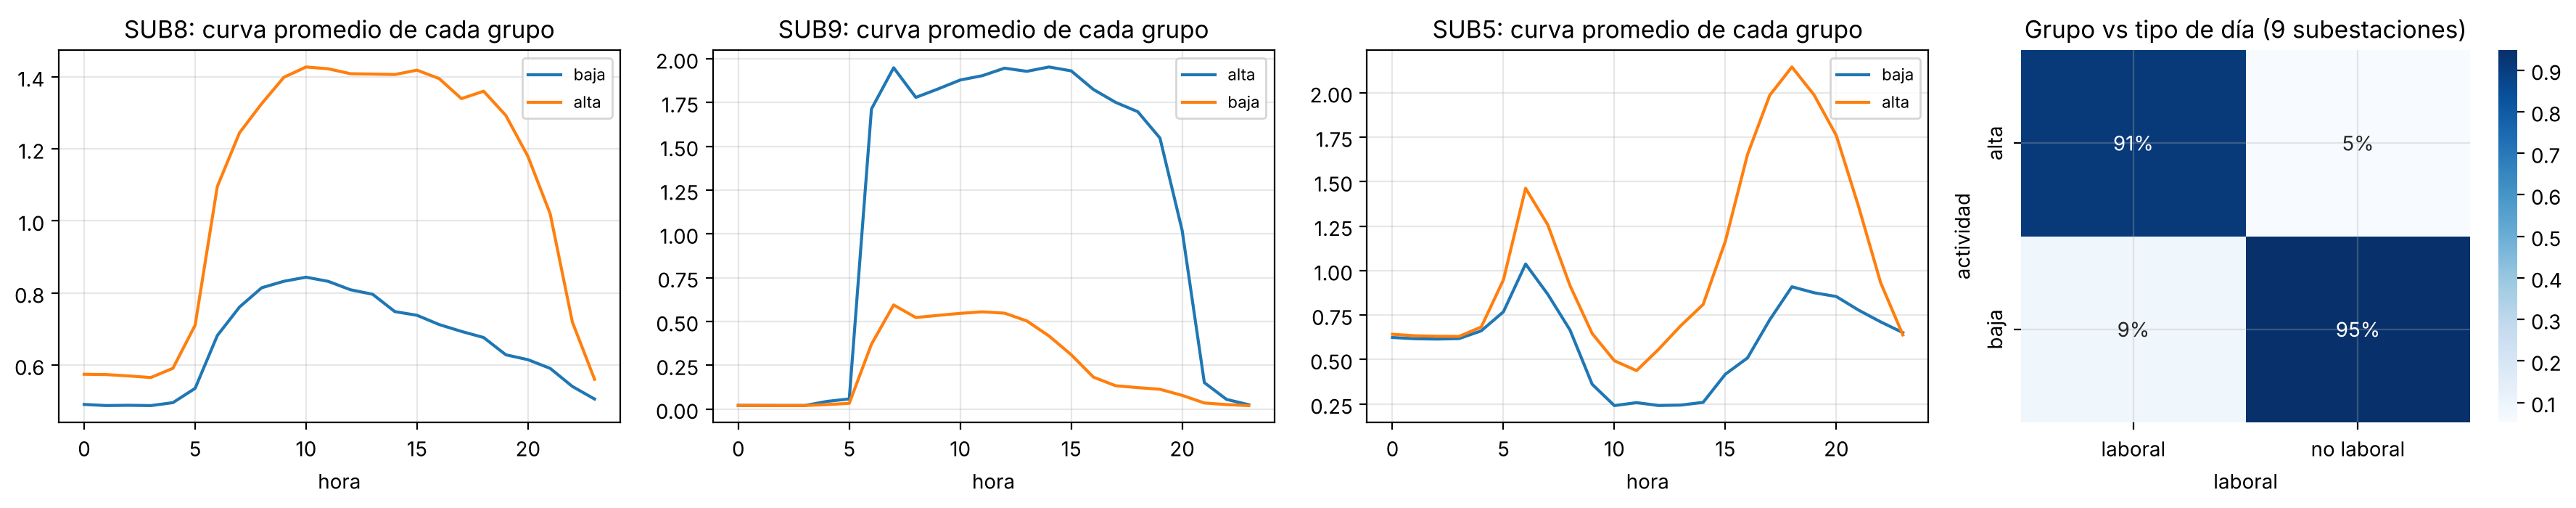

In [16]:
# =============================================================================
# 4.2b Método B: k-means sobre las curvas diarias, una subestación a la vez
# =============================================================================
# Cada día completo -> vector de 24 kWh dividido por el nivel típico de la subestación.
# Agrupamos por subestación porque cada una tiene su propia forma (SUB9 climatización, SUB5 con paneles solares...).
# k se elige entre 2 y 5 con el coeficiente de silueta (más alto = grupos más separados).
curvas_info, centroides = [], {}
for k in limpio.columns:
    s = limpio[k]
    mat = pd.DataFrame(s.values.reshape(-1, 24), index=pd.date_range(s.index.min(), periods=len(s) // 24, freq="D")).dropna()
    X = (mat / mat.mean(axis=1).median()).values
    sil = {n: silhouette_score(X, KMeans(n, n_init=10, random_state=SEMILLA).fit_predict(X)) for n in range(2, 6)}
    n_best = max(sil, key=sil.get)
    km = KMeans(n_best, n_init=20, random_state=SEMILLA).fit(X)
    orden = np.argsort(km.cluster_centers_.mean(axis=1))                 # de menor a mayor actividad
    rango = {g: r for r, g in enumerate(orden)}
    etiqueta = {g: ("alta" if rango[g] == n_best - 1 else "baja" if rango[g] == 0 else "media") for g in range(n_best)}
    centroides[k] = {etiqueta[g] + (f"{rango[g]}" if etiqueta[g] == "media" else ""): km.cluster_centers_[g] for g in range(n_best)}
    curvas_info.append(pd.DataFrame({"subestacion": k, "fecha": mat.index, "k": n_best, "silueta": sil[n_best],
                                     "actividad": [etiqueta[g] for g in km.labels_]}))
curvas_info = pd.concat(curvas_info, ignore_index=True).merge(CAL[["laboral", "festivo", "periodo"]], left_on="fecha", right_index=True)
display(curvas_info.groupby("subestacion")[["k", "silueta"]].first().round(3).T)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, k in zip(axes[:3], ["SUB8", "SUB9", "SUB5"]):
    for nombre, c in centroides[k].items():
        ax.plot(range(24), c, label=nombre)
    ax.set_title(f"{k}: curva promedio de cada grupo"); ax.set_xlabel("hora"); ax.legend(fontsize=8)
ct = pd.crosstab(curvas_info.actividad.str.replace(r"\d", "", regex=True), curvas_info.laboral.map({1: "laboral", 0: "no laboral"}), normalize="columns")
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", ax=axes[3]); axes[3].set_title("Grupo vs tipo de día (9 subestaciones)")
plt.tight_layout(); plt.show()

**Lectura del k-means:** en cada subestación los grupos separan **niveles de actividad** (la silueta elige k = 2 en casi todas: curva "alta" de días laborales y curva "baja" de domingos, festivos y cierre; SUB3 tiene además una intermedia). La tabla cruzada muestra que el calendario explica casi toda la agrupación: los días laborales caen en "alta"/"media" y los no laborales en "baja". Esto **confirma con un método no supervisado** que las variables `laboral`/`festivo`/`periodo` son las correctas.

Los casos que **no** encajan son los interesantes:
- un día **no laboral con curva "alta"** (actividad de día de clases en sábado, domingo o festivo) → posible evento o equipo encendido de más. La mayoría están en **SUB9**: la climatización se encendió como un día de clases en varios sábados y domingos;
- un día **laboral de clases con curva "baja"** → posible corte, falla o cierre no informado (son muy pocos).

✅ **Decisión:** como el k-means usa todo el histórico, lo dejamos como herramienta **exploratoria y de verificación**. Para las métricas usamos la regla A, porque solo usa el pasado y es fácil de explicar.

In [17]:
# =============================================================================
# 4.2c Cruce entre métodos: casos que no encajan con el calendario vs regla A
# =============================================================================
cruce = curvas_info.merge(atipicos[["subestacion", "fecha", "dia_atipico"]], on=["subestacion", "fecha"], how="left")
cruce["no_laboral_con_curva_alta"] = (cruce.laboral == 0) & (cruce.actividad == "alta")
cruce["clases_con_curva_baja"] = (cruce.laboral == 1) & (cruce.periodo == "clases") & (cruce.actividad == "baja")
resumen_cruce = cruce.groupby("subestacion").agg(no_laboral_con_curva_alta=("no_laboral_con_curva_alta", "sum"),
                                                 clases_con_curva_baja=("clases_con_curva_baja", "sum"))
display(resumen_cruce.T)
sel = cruce[cruce.no_laboral_con_curva_alta]
print(f"Días no laborales con curva alta: {len(sel)}; de ellos, la regla 1,5× también marca {int(sel.dia_atipico.sum())} "
      f"({sel.dia_atipico.mean():.0%}). → Ambos métodos coinciden en los casos más claros.")
display(sel.sort_values("fecha")[["subestacion", "fecha", "festivo", "periodo", "dia_atipico"]].head(10))

subestacion,SUB1,SUB2,SUB3,SUB4,SUB5,SUB6,SUB7,SUB8,SUB9
no_laboral_con_curva_alta,10,0,3,4,0,7,0,2,42
clases_con_curva_baja,1,0,0,0,0,6,0,1,2


Días no laborales con curva alta: 68; de ellos, la regla 1,5× también marca 33 (49%). → Ambos métodos coinciden en los casos más claros.


,subestacion,fecha,festivo,periodo,dia_atipico
2021,SUB6,2025-04-17,1,receso,False
3640,SUB9,2025-04-26,0,clases,False
3647,SUB9,2025-05-03,0,clases,True
3654,SUB9,2025-05-10,0,clases,False
3661,SUB9,2025-05-17,0,clases,False
2058,SUB6,2025-05-24,0,clases,False
3675,SUB9,2025-05-31,0,clases,False
3681,SUB9,2025-06-07,0,intersemestral,False
3695,SUB9,2025-06-21,0,intersemestral,False
3709,SUB9,2025-07-05,0,intersemestral,False


---
# 5. Ingeniería de características: de serie de tiempo a tabla

🧠 **Idea dummie:** un modelo tabular (Ridge, Random Forest, LightGBM) no entiende de "series de tiempo". Hay que **convertir el pasado en columnas**. La regla de oro: *cada columna de una fila debe poder calcularse a la medianoche anterior al día de esa fila*.

Ejemplo (mismo formato de la explicación del docente). Fila de **SUB8, martes 15-sep-2026, 15:00**, emitida el martes a las 00:00:

| Pista | Valor que mira | ¿Disponible a medianoche? |
|---|---|---|
| `hora` = 15, `dia_semana` = martes, `festivo` = 0 | calendario | ✅ se sabe de antemano |
| `lag_24` | lunes 14-sep 15:00 | ✅ ya pasó |
| `lag_168` | martes 8-sep 15:00 | ✅ ya pasó |
| `prom_ult3h_ayer` | lunes 21:00-23:00 | ✅ ya pasó |
| consumo del martes 14:00 ("hora anterior") | martes 14:00 | ❌ **no existe todavía** → no se usa |

## 5.1 Diccionario de variables

In [18]:
# =============================================================================
# 5.1 Diccionario de variables (qué es, por qué está y si está disponible a las 00:00)
# =============================================================================
diccionario = pd.DataFrame([
    # nombre, grupo, descripción, justificación (hallazgo EDA), ¿disponible a medianoche?
    ("lag_24", "rezago", "misma hora, día anterior", "H3: ACF alta en 24 h", "sí"),
    ("lag_48", "rezago", "misma hora, hace 2 días", "H3", "sí"),
    ("lag_168", "rezago", "misma hora, semana anterior", "H3: ACF máxima en 168 h", "sí"),
    ("lag_336", "rezago", "misma hora, hace 2 semanas", "H3", "sí"),
    ("lag_mismo_tipo", "rezago", "misma hora del último día del mismo tipo (laboral/no laboral)", "H5: trampa del lunes festivo", "sí"),
    ("total_ayer", "nivel", "consumo total del día anterior", "nivel reciente", "sí"),
    ("max_ayer", "nivel", "máximo horario del día anterior", "picos recientes", "sí"),
    ("prom_ult3h_ayer", "nivel", "promedio 21:00-23:00 del día anterior", "estado al cierre del día", "sí"),
    ("media_7d_misma_hora", "nivel", "promedio de la misma hora en los últimos 7 días", "suaviza el ruido", "sí"),
    ("std_4sem_misma_hora", "nivel", "desviación estándar de la misma hora en 28 días", "volatilidad de esa hora", "sí"),
    ("razon_24_168", "nivel", "lag_24 / lag_168: ¿la semana va por encima de la anterior?", "tendencia corta", "sí"),
    ("nivel_7d", "nivel", "kWh/h promedio de los últimos 7 días (se usa para normalizar)", "H6: escalas distintas, SUB3", "sí"),
    ("hora, hora_sin, hora_cos", "calendario", "hora del día (seno/coseno para el modelo lineal)", "H3", "sí"),
    ("dia_semana, dow_sin, dow_cos", "calendario", "día de la semana", "H3", "sí"),
    ("mes", "calendario", "mes del año", "estacionalidad larga", "sí"),
    ("festivo, fin_semana, laboral, puente", "calendario", "tipo de día", "H4", "sí"),
    ("ayer_laboral, hace7_laboral, dias_desde_mismo_tipo", "calendario", "tipo de los días que usan los rezagos", "H5", "sí"),
    ("periodo, semana_semestre", "calendario", "clases / receso / intersemestral / cierre; semana del semestre", "H4", "sí"),
    ("subestacion", "identificación", "código de la subestación (modelo global)", "H6", "sí"),
    ("t_media_ayer, t_max_ayer, precip_ayer", "clima", "clima observado del día anterior", "H7", "sí"),
    ("temp_hora_obs, t_max_dia_obs", "clima ORÁCULO", "clima observado del MISMO día (solo experimento)", "H7", "NO → solo para medir el valor de un pronóstico"),
], columns=["variable", "grupo", "qué es", "por qué (EDA)", "¿disponible a las 00:00?"])
diccionario

,variable,grupo,qué es,por qué (EDA),¿disponible a las 00:00?
0,lag_24,rezago,"misma hora, día anterior",H3: ACF alta en 24 h,sí
1,lag_48,rezago,"misma hora, hace 2 días",H3,sí
2,lag_168,rezago,"misma hora, semana anterior",H3: ACF máxima en 168 h,sí
3,lag_336,rezago,"misma hora, hace 2 semanas",H3,sí
4,lag_mismo_tipo,rezago,misma hora del último día del mismo tipo (labo...,H5: trampa del lunes festivo,sí
5,total_ayer,nivel,consumo total del día anterior,nivel reciente,sí
6,max_ayer,nivel,máximo horario del día anterior,picos recientes,sí
7,prom_ult3h_ayer,nivel,promedio 21:00-23:00 del día anterior,estado al cierre del día,sí
8,media_7d_misma_hora,nivel,promedio de la misma hora en los últimos 7 días,suaviza el ruido,sí
9,std_4sem_misma_hora,nivel,desviación estándar de la misma hora en 28 días,volatilidad de esa hora,sí


In [19]:
# =============================================================================
# 5.2 Construcción de la tabla supervisada: una fila por (subestación, hora)
# =============================================================================
def construir_tabla(limpio, hasta=None):
    # limpio: tabla ancha (filas = horas, columnas = subestaciones), SIN datos posteriores a la emisión.
    # hasta:  si se da (p. ej. '2026-10-23 23:00'), se agregan horas vacías para pronosticar ese futuro.
    if hasta is not None:
        limpio = limpio.reindex(pd.date_range(limpio.index.min(), pd.Timestamp(hasta), freq="h"))
    dias = pd.date_range(limpio.index.min().normalize(), limpio.index.max().normalize(), freq="D")
    # CALENDARIO FIJO: se lee de la tabla global CAL (festivos y periodos se conocen con meses de anticipación).
    # Antes se recalculaba solo con los días presentes: al cortar el calendario en el día pronosticado, un sábado
    # de puente "no veía" el lunes festivo y `puente` valía 0 en producción pero 1 en el entrenamiento.
    cal = CAL.reindex(dias)
    assert cal.laboral.notna().all(), "CAL no cubre estas fechas: amplíe el rango de CAL (sección 3.5)"

    # Para cada día: último día anterior del MISMO tipo (laboral / no laboral)
    ultimo, prev_mismo = {0: None, 1: None}, {}
    for dia_i, es_lab in cal.laboral.items():
        prev_mismo[dia_i] = ultimo[es_lab]; ultimo[es_lab] = dia_i
    prev_mismo = pd.Series(prev_mismo)

    partes = []
    for k in limpio.columns:
        s = limpio[k]
        # Matriz día × hora (24 columnas) para calcular agregados por día de forma sencilla
        M = pd.DataFrame(s.values.reshape(-1, 24), index=dias)
        df = pd.DataFrame({"timestamp": s.index, "subestacion": k, "kwh": s.values})
        dia = df.timestamp.dt.normalize(); hora = df.timestamp.dt.hour.values

        # --- REZAGOS (lags): la misma hora, hace 24 / 48 / 168 / 336 horas (1 día, 2 días, 1 semana, 2 semanas) ---
        # s.shift(L) con L POSITIVO desplaza la serie hacia adelante: la fila de la hora t recibe el valor de la hora t-L,
        # es decir, del PASADO. Como L >= 24 h, a las 00:00 de D todos los rezagos de las 24 horas de D ya existen.
        # (Un shift negativo, o L < 24, usaría el futuro o horas del mismo día que aún no ocurren: por eso no se usan.)
        for L in (24, 48, 168, 336):
            df[f"lag_{L}"] = s.shift(L).values
        # --- Rezago del último día del mismo tipo ---
        idx_prev = dia.map(prev_mismo)
        Mlarga = M.stack(future_stack=True)
        df["lag_mismo_tipo"] = Mlarga.reindex(pd.MultiIndex.from_arrays([idx_prev, hora])).values
        df["dias_desde_mismo_tipo"] = (dia - idx_prev).dt.days.values

        # --- Nivel del día anterior (todas las horas de la fila comparten estos valores) ---
        horas_validas = M.notna().sum(axis=1)
        total = (M.mean(axis=1) * 24).where(horas_validas >= 20)          # total del día si hay ≥ 20 horas
        ayer = lambda serie: serie.shift(1).reindex(dia).values          # valor del día D-1 para cada fila de D
        df["total_ayer"] = ayer(total)
        df["max_ayer"] = ayer(M.max(axis=1))
        df["prom_ult3h_ayer"] = ayer(M[[21, 22, 23]].mean(axis=1))
        # nivel_7d: kWh/h promedio de los 7 días anteriores (necesita ≥ 72 horas con dato)
        suma7 = M.sum(axis=1).rolling(7, min_periods=1).sum().shift(1)
        n7 = M.notna().sum(axis=1).rolling(7, min_periods=1).sum().shift(1)
        df["nivel_7d"] = (suma7 / n7).where(n7 >= 72).reindex(dia).values

        # --- Estadísticas de la misma hora en días anteriores ---
        mismas7 = np.column_stack([s.shift(24 * i).values for i in range(1, 8)])
        mismas28 = np.column_stack([s.shift(24 * i).values for i in range(1, 29)])
        with np.errstate(all="ignore"):
            df["media_7d_misma_hora"] = np.nanmean(mismas7, axis=1)
            df["std_4sem_misma_hora"] = np.nanstd(mismas28, axis=1)
        df["razon_24_168"] = (df.lag_24 / df.lag_168).replace([np.inf, -np.inf], np.nan).clip(0, 5)
        partes.append(df)

    T = pd.concat(partes, ignore_index=True)
    dia = T.timestamp.dt.normalize()
    # --- Calendario de la fila (se conoce con anticipación) ---
    T["hora"] = T.timestamp.dt.hour
    T["hora_sin"], T["hora_cos"] = np.sin(2 * np.pi * T.hora / 24), np.cos(2 * np.pi * T.hora / 24)
    for col in ["dia_semana", "festivo", "fin_semana", "laboral", "puente", "periodo", "semana_semestre"]:
        T[col] = dia.map(CAL[col]).values                        # mismo calendario en entrenamiento, validación y pronóstico
    T["dow_sin"], T["dow_cos"] = np.sin(2 * np.pi * T.dia_semana / 7), np.cos(2 * np.pi * T.dia_semana / 7)
    T["mes"] = T.timestamp.dt.month
    T["ayer_laboral"] = dia.map(CAL.laboral.shift(1)).values        # tipo del día D-1 (calendario fijo)
    T["hace7_laboral"] = dia.map(CAL.laboral.shift(7)).values       # tipo del día D-7
    # --- Clima observado de AYER (válido) ---
    for c in ["t_media", "t_max", "precip"]:
        T[f"{c}_ayer"] = dia.map(clima_d[c].shift(1)).values
    # --- Clima observado del MISMO día: ORÁCULO, solo para el experimento de la Sección 7 ---
    T["temp_hora_obs"] = T.timestamp.map(clima.T2M).values
    T["t_max_dia_obs"] = dia.map(clima_d.t_max).values
    # --- Tipos categóricos con categorías fijas (iguales en entrenamiento y pronóstico) ---
    T["subestacion"] = pd.Categorical(T.subestacion, categories=SUBESTACIONES)
    T["periodo"] = pd.Categorical(T.periodo, categories=["clases", "receso", "intersemestral", "cierre"])
    return T

t0 = time.time()
tabla = construir_tabla(limpio)
print(f"Tabla construida en {time.time()-t0:.1f} s: {tabla.shape[0]:,} filas × {tabla.shape[1]} columnas")
tabla[(tabla.subestacion == "SUB8") & (tabla.timestamp == "2026-09-15 15:00")].T

Tabla construida en 0.4 s: 120,096 filas × 36 columnas


,105855
timestamp,2026-09-15 15:00:00
subestacion,SUB8
kwh,778.3125
lag_24,781.1875
lag_48,355.875
lag_168,806.25
lag_336,791.875
lag_mismo_tipo,781.1875
dias_desde_mismo_tipo,1.0
total_ayer,13903.875


## 5.3 Normalización por nivel reciente (decisión de H6)

Para cada fila dividimos el objetivo y las variables de consumo por `nivel_7d`. El modelo aprende el **objetivo relativo** `y_rel = kWh / nivel_7d` y luego el pronóstico se lleva de vuelta a kWh multiplicando por `nivel_7d`.

🧠 **Idea dummie:** en vez de aprender "SUB9 consume tantos kWh a las 15:00", el modelo aprende "a las 15:00 de un día de clases se consume 1,6 veces el promedio de la última semana". Esa regla sirve para SUB9, para SUB2 y para la nueva SUB3.

**Filas utilizables y tres cantidades que no hay que confundir** (corrección de la versión anterior, que exigía `lag_168` para todo):

| Cantidad | Definición | Para qué sirve |
|---|---|---|
| **Horas planeadas** | todas las (subestación, hora) que se pronostican | Cobertura operativa: lo que el usuario espera recibir |
| **Horas con medición válida** | tienen kWh real tras la limpieza | Se puede calcular el error del modelo |
| **Horas comparables** | además tienen el dato de "misma hora de la semana pasada" | Única base donde se puede comparar el modelo **contra la regla del docente** (que sin ese dato no existe) |

✅ **Decisión:** el modelo se **entrena y se pronostica** con toda fila que tenga objetivo y `nivel_7d` (LightGBM tolera un rezago vacío). Cuando se **compara** contra la regla "semana pasada" se usan **solo las horas comparables**, y todos los métodos se evalúan sobre exactamente las mismas filas. El desempeño del modelo en horas sin referencia semanal se reporta aparte.

In [20]:
# =============================================================================
# 5.3 Variables finales y normalización
# =============================================================================
VARS_CONSUMO = ["lag_24", "lag_48", "lag_168", "lag_336", "lag_mismo_tipo", "max_ayer", "prom_ult3h_ayer",
                "media_7d_misma_hora", "std_4sem_misma_hora"]
VARS_CAL = ["hora", "hora_sin", "hora_cos", "dia_semana", "dow_sin", "dow_cos", "mes", "festivo", "fin_semana",
            "laboral", "puente", "ayer_laboral", "hace7_laboral", "dias_desde_mismo_tipo", "semana_semestre"]
VARS_CLIMA_AYER = ["t_media_ayer", "t_max_ayer", "precip_ayer"]
VARS_ORACULO = ["temp_hora_obs", "t_max_dia_obs"]
CATEGORICAS = ["subestacion", "periodo"]

def preparar(T):
    # Agrega las versiones relativas (÷ nivel_7d). No usa información futura: nivel_7d es del pasado.
    T = T.copy()
    for c in VARS_CONSUMO:
        T[c + "_rel"] = T[c] / T.nivel_7d
    T["total_ayer_rel"] = T.total_ayer / (24 * T.nivel_7d)
    T["y_rel"] = T.kwh / T.nivel_7d
    return T

VARS_BASE = [c + "_rel" for c in VARS_CONSUMO] + ["total_ayer_rel", "razon_24_168", "nivel_7d"] + VARS_CAL + CATEGORICAS

tabla = preparar(tabla)
# Filas con las que se ENTRENA y se pronostica: objetivo real + nivel_7d (necesario para devolver de relativo a kWh).
datos = tabla[tabla.kwh.notna() & tabla.nivel_7d.notna()].reset_index(drop=True)
# Filas COMPARABLES con la regla "semana pasada": además tienen lag_168 (misma hora de hace 7 días).
datos["comparable"] = datos.lag_168.notna()
print(f"Filas utilizables: {len(datos):,}  ({len(datos)/tabla.kwh.notna().sum():.1%} de las horas con dato real)")
print(f"De ellas, comparables con la regla de la semana pasada: {int(datos.comparable.sum()):,} ({datos.comparable.mean():.1%})")
print("Variables del modelo base:", len(VARS_BASE))
display(datos.groupby("subestacion", observed=True).timestamp.agg(["min", "max", "count"]))

Filas utilizables: 102,227  (98.3% de las horas con dato real)
De ellas, comparables con la regla de la semana pasada: 99,661 (97.5%)
Variables del modelo base: 29


,min,max,count
subestacion,,,
SUB1,2025-11-24,2026-10-22 23:00:00,7746
SUB2,2025-04-18,2026-10-22 23:00:00,12491
SUB3,2026-03-08,2026-10-22 23:00:00,5479
SUB4,2025-04-18,2026-10-22 23:00:00,12694
SUB5,2025-04-19,2026-10-22 23:00:00,12137
SUB6,2025-04-18,2026-10-22 23:00:00,13224
SUB7,2025-04-18,2026-10-22 23:00:00,12621
SUB8,2025-04-18,2026-10-22 23:00:00,12660
SUB9,2025-04-18,2026-10-22 23:00:00,13175


## 5.4 Auditoría de fuga de información (la prueba más importante)

🧠 **Idea dummie:** si una variable "mira el futuro", el modelo parece genial en el laboratorio y falla en la vida real. La prueba correcta parte de los **datos crudos** (la versión anterior partía de datos ya limpiados, y por eso no podía detectar que la limpieza miraba el futuro). Para cada día **D** reconstruimos todo el flujo (limpieza → tabla → predicción) de tres maneras y exigimos que den **exactamente lo mismo** en las 216 filas de D (9 subestaciones × 24 horas):

1. **Historia completa:** la tabla que se usó para entrenar y evaluar.
2. **Recortar:** crudos hasta las 23:00 del día anterior (lo que realmente se sabe a medianoche).
3. **Alterar el futuro:** los consumos **desde las 00:00 de D en adelante** se multiplican por factores al azar, se borran algunos y se inyectan picos de 50 000 kWh. Si las variables o la predicción de D cambian, hay fuga.

Se incluyen fechas difíciles (la columna `motivo` de la tabla dice por qué se eligió cada una): el día después del error del 21-feb, el primer día de SUB3 con equipo nuevo (justo después de un hueco), el día después del pico del 20-ago, el sábado y el domingo antes del lunes festivo del 12-oct (puente) y un día con un dato recién llegado tras un hueco de medición.

| ❓ Pregunta | 🔧 Qué hace el código | 🎯 Por qué | 📖 Cómo interpretarlo |
|---|---|---|---|
| ¿Alguna variable o predicción de D usa información posterior a las 00:00 de D? | Reconstruye la tabla desde el crudo en 3 versiones y compara columna por columna, y compara las predicciones de un mismo modelo | Si el futuro no puede cambiar el resultado, el resultado no depende del futuro | "NINGUNA" en todas las filas = sin fuga; cualquier columna listada es una fuga que hay que corregir |

In [21]:
# =============================================================================
# 5.4 Prueba de no-fuga DESDE LOS DATOS CRUDOS (limpieza + tabla + predicción)
# =============================================================================
def tabla_desde_crudo(crudo, hasta=None):
    # Todo el flujo desde el dato crudo: limpiar -> tabla de variables -> versiones relativas.
    lim, _ = limpiar_series(crudo)
    return preparar(construir_tabla(lim, hasta=hasta))

def crudo_con_futuro_alterado(fecha, semilla=0):
    # Copia del crudo donde TODO lo que ocurre desde las 00:00 de 'fecha' se destruye o distorsiona.
    rng = np.random.default_rng(semilla)
    alt = ancho_crudo.copy()
    fut = alt.index >= fecha
    vals = alt.loc[fut].values * rng.uniform(0.2, 5.0, size=alt.loc[fut].shape)      # factores al azar
    vals[rng.random(vals.shape) < 0.15] = np.nan                                       # 15 % de huecos nuevos
    vals[rng.random(vals.shape) < 0.01] = 50000.0                                      # picos imposibles
    alt.loc[fut] = vals
    return alt

# Un LightGBM mínimo, entrenado SOLO con lo anterior al test, para comprobar que las PREDICCIONES tampoco cambian
_dev = datos[datos.timestamp < INICIO_TEST]
modelo_prueba = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, num_leaves=31, objective="l1",
                                  random_state=SEMILLA, verbose=-1).fit(_dev[VARS_BASE], _dev.y_rel)
def predecir_prueba(T): return modelo_prueba.predict(T[VARS_BASE]) * T.nivel_7d.values

def prueba_no_fuga(fecha):
    fecha = pd.Timestamp(fecha)
    fin = fecha + pd.Timedelta(hours=23)
    ultima_hora = fecha - pd.Timedelta(hours=1)          # <- CORTE DE LA EMISIÓN: último dato conocido a las 00:00
    orden = ["subestacion", "timestamp"]
    ref = tabla[tabla.timestamp.dt.normalize() == fecha].sort_values(orden).reset_index(drop=True)
    cols = [c for c in ref.columns if c not in ("kwh", "y_rel", "comparable")]   # el objetivo del propio día sí cambia: es el futuro
    versiones = {"recortar": tabla_desde_crudo(ancho_crudo.loc[:ultima_hora], hasta=fin),
                 "alterar el futuro": tabla_desde_crudo(crudo_con_futuro_alterado(fecha))}
    salida = {"fecha": fecha.date(), "filas (9×24)": len(ref)}
    for nombre, T in versiones.items():
        T = T[T.timestamp.dt.normalize() == fecha].sort_values(orden).reset_index(drop=True)
        distintas = [c for c in cols if not ref[c].astype(str).equals(T[c].astype(str))]
        salida[f"{nombre}: variables que cambian"] = ", ".join(distintas) if distintas else "NINGUNA ✅"
        salida[f"{nombre}: predicción idéntica"] = "sí ✅" if np.array_equal(predecir_prueba(ref), predecir_prueba(T), equal_nan=True) else "NO ❌"
    return salida

# Fechas difíciles: error del 21-feb, SUB3 con equipo nuevo, día tras el pico del 20-ago, fines de semana antes del
# festivo del 12-oct, un día normal y días con hueco de medición reciente (se buscan automáticamente en el test).
huecos_test = []
for k in ancho_crudo.columns:
    isn = ancho_crudo.loc[INICIO_TEST:, k].isna()
    fin_hueco = isn.shift(1, fill_value=False) & ~isn                       # primera hora con dato tras un hueco
    huecos_test += list(ancho_crudo.loc[INICIO_TEST:].index[fin_hueco.values].normalize())
MOTIVOS = {"2026-02-22": "día después del error de señal del 21-feb (valores imposibles)",
           "2026-03-05": "primer día de SUB3 con el equipo nuevo (justo después de un hueco)",
           "2026-06-01": "día normal de validación", "2026-08-21": "día después del pico del 20-ago (R3)",
           "2026-09-15": "martes normal de clases", "2026-10-10": "sábado antes del lunes festivo (puente)",
           "2026-10-11": "domingo antes del lunes festivo (puente)", "2026-10-13": "martes después del festivo"}
FECHAS_HUECO = [str(d.date()) for d in sorted(set(huecos_test))[:3]]               # primer dato tras un hueco de medición, en el test
for f in FECHAS_HUECO: MOTIVOS.setdefault(f, "primer dato de alguna subestación tras un hueco de medición")
informe_fuga = pd.DataFrame([{**prueba_no_fuga(f), "motivo": MOTIVOS[f]} for f in sorted(MOTIVOS)])
display(informe_fuga.set_index("fecha").T)
assert (informe_fuga.filter(like="variables que cambian") == "NINGUNA ✅").all().all(), "Hay fuga: revise la tabla"
assert (informe_fuga.filter(like="predicción") == "sí ✅").all().all(), "Las predicciones cambian al alterar el futuro"

fecha,2026-02-22,2026-03-05,2026-06-01,2026-08-21,2026-09-15,2026-10-10,2026-10-11,2026-10-13,2026-10-21
filas (9×24),216,216,216,216,216,216,216,216,216
recortar: variables que cambian,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅
recortar: predicción idéntica,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅
alterar el futuro: variables que cambian,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅,NINGUNA ✅
alterar el futuro: predicción idéntica,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅,sí ✅
motivo,día después del error de señal del 21-feb (val...,primer día de SUB3 con el equipo nuevo (justo ...,día normal de validación,día después del pico del 20-ago (R3),martes normal de clases,sábado antes del lunes festivo (puente),domingo antes del lunes festivo (puente),martes después del festivo,primer dato de alguna subestación tras un huec...


In [22]:
# =============================================================================
# 5.4b El calendario es el MISMO en entrenamiento, validación y pronóstico (variable `puente`)
# =============================================================================
# Caso concreto: sáb 10 y dom 11 de octubre de 2026, justo antes del lunes festivo 12-oct (puente).
print("Calendario conocido de antemano (CAL):")
display(CAL.loc["2026-10-09":"2026-10-13", ["dia_semana", "festivo", "laboral", "puente", "periodo"]])
hist_corte = tabla_desde_crudo(ancho_crudo.loc[:"2026-10-09 23:00"], hasta="2026-10-11 23:00")   # emisión del viernes 9 a medianoche
for dia in ["2026-10-10", "2026-10-11"]:
    en_tabla = tabla.loc[tabla.timestamp.dt.normalize() == dia, "puente"].unique()
    en_corte = hist_corte.loc[hist_corte.timestamp.dt.normalize() == dia, "puente"].unique()
    print(f"{dia}: puente en la tabla de entrenamiento = {en_tabla}  |  puente al pronosticar con el corte = {en_corte}")
    assert list(en_tabla) == [1] and list(en_corte) == [1], "puente inconsistente"
print("→ `puente` vale 1 en ambos casos ✅ (antes, al pronosticar, el calendario se cortaba y valía 0).")

Calendario conocido de antemano (CAL):


,dia_semana,festivo,laboral,puente,periodo
2026-10-09,4,0,1,0,receso
2026-10-10,5,0,0,1,receso
2026-10-11,6,0,0,1,receso
2026-10-12,0,1,0,1,clases
2026-10-13,1,0,1,0,clases


2026-10-10: puente en la tabla de entrenamiento = [1]  |  puente al pronosticar con el corte = [1]
2026-10-11: puente en la tabla de entrenamiento = [1]  |  puente al pronosticar con el corte = [1]
→ `puente` vale 1 en ambos casos ✅ (antes, al pronosticar, el calendario se cortaba y valía 0).


**Resultado:** ninguna variable cambia al quitar o destruir el futuro, y un mismo modelo da **las mismas predicciones** para las 216 filas de cada día probado → **el flujo completo (limpieza + variables) no tiene fuga**. (Las variables de clima "oráculo" no cambian porque vienen del archivo de clima, no del consumo; por eso las marcamos a mano como **no desplegables** y solo se usan en un experimento controlado.)

### Resumen del EDA: hallazgo → decisión

| Hipótesis | Hallazgo | Decisión |
|---|---|---|
| H1 Calidad | Picos imposibles, ceros, negativos, huecos largos | Reglas R1-R4; no imputar el objetivo |
| H2 Conciliación | La suma de las 9 series ≈ 91-97 % del medidor total, correlación ≈ 1 (causa del resto sin confirmar) | Series confiables; se habla de "suma de las nueve subestaciones", no de demanda total de la universidad |
| H3 Ciclos | Ciclo diario y semanal; ACF alta en 24 y 168 h | Rezagos 24/48/168/336; hora y día |
| H4 Calendario | Clases > intersemestral > receso > cierre; festivo ≈ domingo | `periodo`, `semana_semestre`, `festivo`, `puente` |
| H5 Trampa del lunes | lag_24 falla cuando ayer no fue laboral | `lag_mismo_tipo`, `ayer_laboral`, `hace7_laboral` |
| H6 Escalas y régimen | Escalas 4× distintas; SUB3 sube ~60 % | Normalizar por `nivel_7d`; modelo global; SUB3 desde 5-mar-2026 |
| H7 Clima | Relación débil con temperatura; radiación afecta bloques con paneles | Probar sin clima / clima de ayer / oráculo |
| H8 Atípicos | Pocos días atípicos; más en SUB5 (nubes) y SUB9 | Reportar error aparte; probar entrenar con y sin ellos |

---
# 6. Esquema de validación (cómo medimos sin hacer trampa)

## 6.1 Tres bloques en el tiempo

🧠 **Idea dummie:** simulamos que estamos en el pasado. Entrenamos solo con lo que había antes y pronosticamos lo que vino después, **como si fuera la vida real**. Nunca mezclamos al azar (eso sería mirar el futuro).

| Bloque | Fechas | Para qué se usa |
|---|---|---|
| **Entrenamiento inicial** | 15-abr-2025 → 31-mar-2026 | Aprender |
| **Validación walk-forward** (4 pliegues) | abr, may, jun y jul de 2026 | Comparar familias, ajustar hiperparámetros, **elegir** el modelo. Cada pliegue entrena con **todo lo anterior** (ventana expansiva) y pronostica el mes siguiente. |
| **Prueba (test) reservado** | 1-ago-2026 → 22-oct-2026 (83 días) | **Una sola vez al final**, con todo ya congelado. Igual que propuso el docente: entrenar hasta el 31-jul, pronosticar el 1-ago, avanzar y repetir. Reentrenamos cada 7 días. |

✅ **¿Por qué esos meses de validación?** Cubren situaciones distintas: fin de Semana Santa (abril), cierre de semestre (mayo), intersemestral (junio-julio) e inicio de clases (13-jul). Un modelo que funciona bien en los cuatro es robusto.

✅ **¿Por qué ese test?** Es lo más reciente (lo más parecido al uso real) e incluye clases, 3 festivos (7-ago, 17-ago y 12-oct) y la semana de receso (5 al 11-oct).

✅ **¿Hace falta "embargo" (brecha) entre entrenamiento y validación?** No: cada fila solo usa datos de hasta la medianoche anterior (probado en 5.4) y el entrenamiento termina exactamente a esa medianoche. Es el mismo corte que habrá en operación.

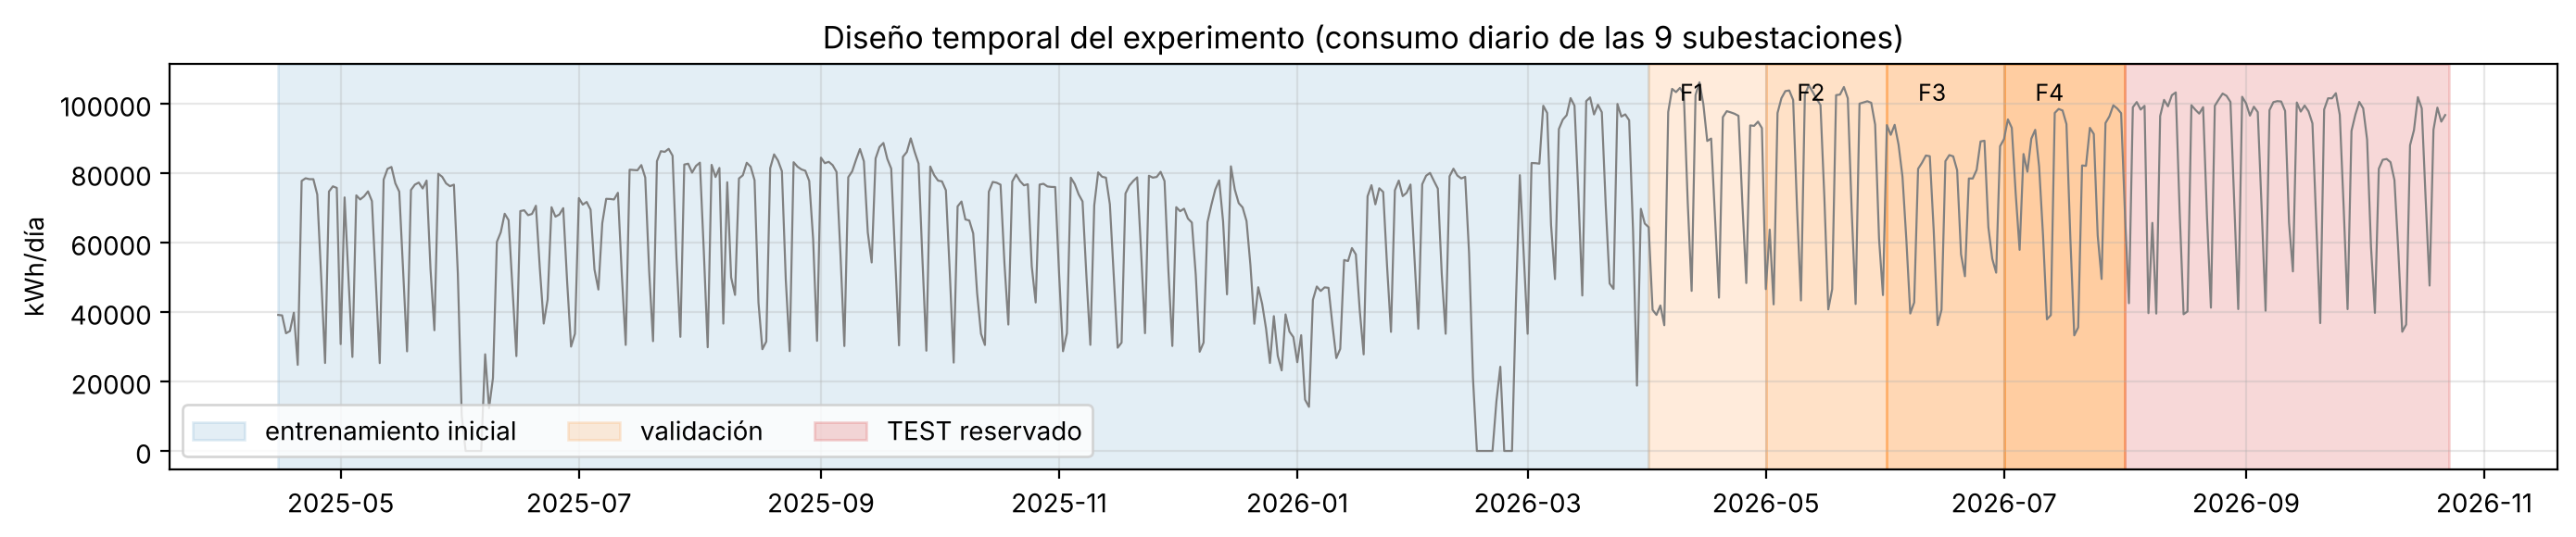

Desarrollo: 84,365 filas | Test reservado: 17,862 filas


In [23]:
# =============================================================================
# 6.1 Visualización de los bloques temporales
# =============================================================================
fig, ax = plt.subplots(figsize=(14, 3))
total_h = limpio.sum(axis=1, min_count=5).resample("D").sum()
ax.plot(total_h.index, total_h.values, color="gray", lw=0.8)
ax.axvspan(total_h.index.min(), pd.Timestamp(FOLDS_VALIDACION[0][0]), color="tab:blue", alpha=0.12, label="entrenamiento inicial")
for i, (a, b) in enumerate(FOLDS_VALIDACION):
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="tab:orange", alpha=0.15 + 0.08 * i, label="validación" if i == 0 else None)
    ax.text(pd.Timestamp(a) + pd.Timedelta(days=8), total_h.max() * 0.95, f"F{i+1}", fontsize=9)
ax.axvspan(INICIO_TEST, FIN_DATOS, color="tab:red", alpha=0.18, label="TEST reservado")
ax.set_title("Diseño temporal del experimento (consumo diario de las 9 subestaciones)"); ax.set_ylabel("kWh/día")
ax.legend(loc="lower left", ncol=3); plt.tight_layout(); plt.show()

desarrollo = datos[datos.timestamp < INICIO_TEST].copy()      # todo lo que podemos mirar para decidir
test = datos[datos.timestamp >= INICIO_TEST].copy()           # NO se usa hasta la Sección 11
print(f"Desarrollo: {len(desarrollo):,} filas | Test reservado: {len(test):,} filas")

## 6.2 Métricas: cuál es la principal y por qué

| Métrica | Fórmula (intuitiva) | Rol |
|---|---|---|
| **WAPE** (principal) | Σ\|real − pronóstico\| / Σ real | **% de la energía total que se pronosticó mal.** Como la energía se paga por kWh, el WAPE es directamente el % de la factura que el pronóstico estima mal. No se dispara con valores pequeños (SUB9 de noche, casi cero), a diferencia del MAPE. Pondera por volumen, que es lo que cuesta dinero. |
| MAE (kWh) | promedio de \|error\| | Error típico de una hora en kWh; se convierte a pesos multiplicando por la tarifa. |
| RMSE (kWh) | raíz del promedio de error² | Castiga los errores grandes (picos). Sirve para ver si fallamos en las horas pico. |
| **MASE** | MAE del modelo / MAE de la regla "semana pasada" en entrenamiento | < 1 significa que **le ganamos** a la regla del docente. No depende de la escala → compara subestaciones. |
| Sesgo (%) | Σ(pronóstico − real) / Σ real | ¿Sobreestimamos (+) o subestimamos (−) sistemáticamente? Importante para el presupuesto. |

✅ **¿Por qué el error absoluto y no el cuadrático como principal?** El costo de equivocarse es **lineal**: cada kWh mal estimado vale lo mismo (la tarifa). No hay penalización especial por picos en el contrato que conocemos. Por eso entrenamos LightGBM con pérdida L1/absoluta como candidata y elegimos con WAPE.

In [24]:
# =============================================================================
# 6.2 Funciones de métricas
# =============================================================================
def wape(y, p):  return np.abs(y - p).sum() / np.abs(y).sum()
def mae(y, p):   return np.mean(np.abs(y - p))
def rmse(y, p):  return np.sqrt(np.mean((y - p) ** 2))
def sesgo(y, p): return (p - y).sum() / y.sum()

def escala_mase(entrenamiento):
    # MAE de la regla "misma hora de la semana pasada" en los datos de ENTRENAMIENTO, por subestación
    return (entrenamiento.kwh - entrenamiento.lag_168).abs().groupby(entrenamiento.subestacion, observed=True).mean()

def metricas(df, col_pred, escala=None):
    y, p = df.kwh.values, df[col_pred].values
    out = {"WAPE_%": 100 * wape(y, p), "MAE_kWh": mae(y, p), "RMSE_kWh": rmse(y, p), "sesgo_%": 100 * sesgo(y, p)}
    if escala is not None:   # MASE agregado = promedio de los MASE por subestación
        por_sub = df.assign(e=np.abs(y - p)).groupby("subestacion", observed=True).e.mean() / escala
        out["MASE"] = por_sub.mean()
    return out

---
# 7. Baselines y familias de modelos

## 7.1 Baselines temporales (la vara que hay que superar)

| Baseline | Regla | Comentario |
|---|---|---|
| Naïve (ayer) | mañana = ayer a la misma hora | Bueno de martes a viernes, malo los lunes y después de festivos (H5) |
| **Seasonal naïve (semana pasada)** | mañana = misma hora de hace 7 días | **La regla que pide superar el docente** |
| Media móvil 7 días | promedio de la misma hora en los últimos 7 días | Suaviza, pero mezcla días laborales y fines de semana |
| Mismo tipo de día | misma hora del último día del mismo tipo | Baseline "inteligente" creado a partir de H5 |

In [25]:
# =============================================================================
# 7.1 Baselines evaluados en los 4 pliegues de validación
# =============================================================================
BASELINES = {
    "Naive (ayer)": lambda d: d.lag_24.fillna(d.lag_168),
    "Seasonal naive (semana pasada)": lambda d: d.lag_168,
    "Media movil 7 dias": lambda d: d.media_7d_misma_hora.fillna(d.lag_168),
    "Mismo tipo de dia": lambda d: d.lag_mismo_tipo.fillna(d.lag_168),
}
OOF = {}                       # predicciones fuera de muestra (out-of-fold) de cada modelo en validación
filas_val = []
for i, (a, b) in enumerate(FOLDS_VALIDACION, 1):
    va = desarrollo[(desarrollo.timestamp >= a) & (desarrollo.timestamp < b)]
    va = va[va.comparable]          # FILAS COMPARABLES: tienen real y "misma hora de la semana pasada" -> todos los métodos, mismas filas
    esc = escala_mase(desarrollo[desarrollo.timestamp < a])
    for nombre, regla in BASELINES.items():
        va_ = va.assign(pred=regla(va))
        OOF.setdefault(nombre, []).append(va_[["timestamp", "subestacion", "pred"]])
        filas_val.append({"modelo": nombre, "pliegue": f"F{i}", **metricas(va_, "pred", esc)})
OOF = {k: pd.concat(v) for k, v in OOF.items()}
res_val = pd.DataFrame(filas_val)
res_val.groupby("modelo")[["WAPE_%", "MAE_kWh", "RMSE_kWh", "MASE", "sesgo_%"]].mean().round(3).sort_values("WAPE_%")

,WAPE_%,MAE_kWh,RMSE_kWh,MASE,sesgo_%
modelo,,,,,
Mismo tipo de dia,17.598,66.114,161.257,0.849,0.077
Seasonal naive (semana pasada),22.550,84.641,190.972,1.130,-0.610
Naive (ayer),24.611,92.392,211.341,1.210,-0.327
Media movil 7 dias,28.142,105.940,193.414,1.400,-0.928


## 7.2 Tres familias de modelos supervisados

| Familia | Modelo | Por qué lo incluimos |
|---|---|---|
| Lineal | **Ridge** (regresión lineal con regularización L2) | Referencia interpretable. Para que sea justo, le damos las interacciones *subestación × hora × laboral* (one-hot), porque un modelo lineal no puede inventar esas formas por sí solo. |
| Ensamble por *bagging* | **Random Forest** | Promedia cientos de árboles entrenados con muestras distintas → reduce varianza. Captura no linealidades sin mucha configuración. |
| Ensamble por *boosting* | **LightGBM** | Árboles que se corrigen unos a otros. Es el estándar en forecasting tabular (y el que propone la Sesión 3 para modelos globales). Maneja faltantes y categorías de forma nativa. |

Más adelante (Sección 9) probamos un **ensamble de ensambles**: el promedio de Random Forest y LightGBM.

🧠 **Cómo funciona `ModeloEnergia`:** recibe la tabla, aprende `y_rel = kWh / nivel_7d` y devuelve kWh (multiplica de vuelta). Todo el preprocesamiento (imputar, escalar, one-hot) vive **dentro** del pipeline, así que se ajusta solo con datos de entrenamiento de cada pliegue.

In [26]:
# =============================================================================
# 7.2 Clase envoltorio: mismo uso para Ridge, Random Forest y LightGBM
# =============================================================================
class ModeloEnergia:
    def __init__(self, tipo, variables=None, params=None, relativo=True):
        self.tipo = tipo                               # 'ridge' | 'rf' | 'lgbm'
        self.variables = list(variables or VARS_BASE)
        self.params = dict(params or {})
        self.relativo = relativo                       # True: aprende kWh/nivel_7d ; False: kWh crudos

    def _X(self, df):
        X = df[self.variables].copy()
        if self.tipo == "ridge":                       # interacción subestación×hora×laboral (one-hot)
            X["sub_hora_lab"] = df.subestacion.astype(str) + "_" + df.hora.astype(str) + "_" + df.laboral.astype(str)
        if self.tipo == "rf":                          # Random Forest de sklearn necesita números
            for c in CATEGORICAS:
                if c in X: X[c] = X[c].cat.codes
        return X

    def fit(self, df):
        X = self._X(df)
        y = df.y_rel if self.relativo else df.kwh
        if self.tipo == "ridge":
            cat = [c for c in ["subestacion", "periodo", "sub_hora_lab"] if c in X]
            num = [c for c in X.columns if c not in cat + ["hora", "dia_semana", "mes"]]
            pre = ColumnTransformer([
                ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
                ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), cat)])
            self.modelo = make_pipeline(pre, Ridge(alpha=self.params.get("alpha", 1.0)))
        elif self.tipo == "rf":
            p = dict(n_estimators=150, min_samples_leaf=10, max_features=0.5, max_samples=0.5, n_jobs=-1, random_state=SEMILLA)
            p.update(self.params)
            self.modelo = make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(**p))
        elif self.tipo == "lgbm":
            p = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=50, subsample=0.8,
                     subsample_freq=1, colsample_bytree=0.8, objective="l1", random_state=SEMILLA, verbose=-1)
            p.update(self.params)
            self.modelo = lgb.LGBMRegressor(**p)
        self.modelo.fit(X, y)
        return self

    def predict(self, df):
        p = self.modelo.predict(self._X(df))
        if self.relativo:
            p = p * df.nivel_7d.values                 # de relativo a kWh
        return np.clip(p, 0, None)                     # no existen consumos negativos

def evaluar_walk_forward(nombre, fabrica, filtro_entrenamiento=None, guardar=True):
    # Entrena en todo lo anterior a cada pliegue y predice el pliegue. Devuelve métricas por pliegue.
    filas, preds = [], []
    t0 = time.time()
    for i, (a, b) in enumerate(FOLDS_VALIDACION, 1):
        tr = desarrollo[desarrollo.timestamp < a]
        if filtro_entrenamiento is not None:
            tr = tr[filtro_entrenamiento(tr)]
        va = desarrollo[(desarrollo.timestamp >= a) & (desarrollo.timestamp < b)].copy()
        va["pred"] = fabrica().fit(tr).predict(va)                      # el modelo pronostica TODAS las filas con medición...
        preds.append(va[["timestamp", "subestacion", "pred"]])
        cmp_ = va[va.comparable]                                         # ...y se compara en las COMPARABLES (las mismas de los baselines)
        filas.append({"modelo": nombre, "pliegue": f"F{i}", **metricas(cmp_, "pred", escala_mase(desarrollo[desarrollo.timestamp < a])),
                      "WAPE_todas_%": 100 * wape(va.kwh.values, va.pred.values)})
    if guardar:
        OOF[nombre] = pd.concat(preds)
    print(f"{nombre:<45s} WAPE medio = {np.mean([f['WAPE_%'] for f in filas]):.2f} %   ({time.time()-t0:.0f} s)")
    return pd.DataFrame(filas)

Ridge (lineal)                                WAPE medio = 15.48 %   (3 s)


Random Forest (bagging)                       WAPE medio = 11.55 %   (79 s)


LightGBM (boosting)                           WAPE medio = 11.46 %   (15 s)


,WAPE_%,MAE_kWh,RMSE_kWh,MASE,sesgo_%
modelo,,,,,
LightGBM (boosting),11.462,42.985,98.073,0.572,-1.020
Random Forest (bagging),11.548,43.316,94.551,0.577,-0.586
Ridge (lineal),15.483,58.050,111.129,0.754,0.529
Mismo tipo de dia,17.598,66.114,161.257,0.849,0.077
Seasonal naive (semana pasada),22.550,84.641,190.972,1.130,-0.610
Naive (ayer),24.611,92.392,211.341,1.210,-0.327
Media movil 7 dias,28.142,105.940,193.414,1.400,-0.928


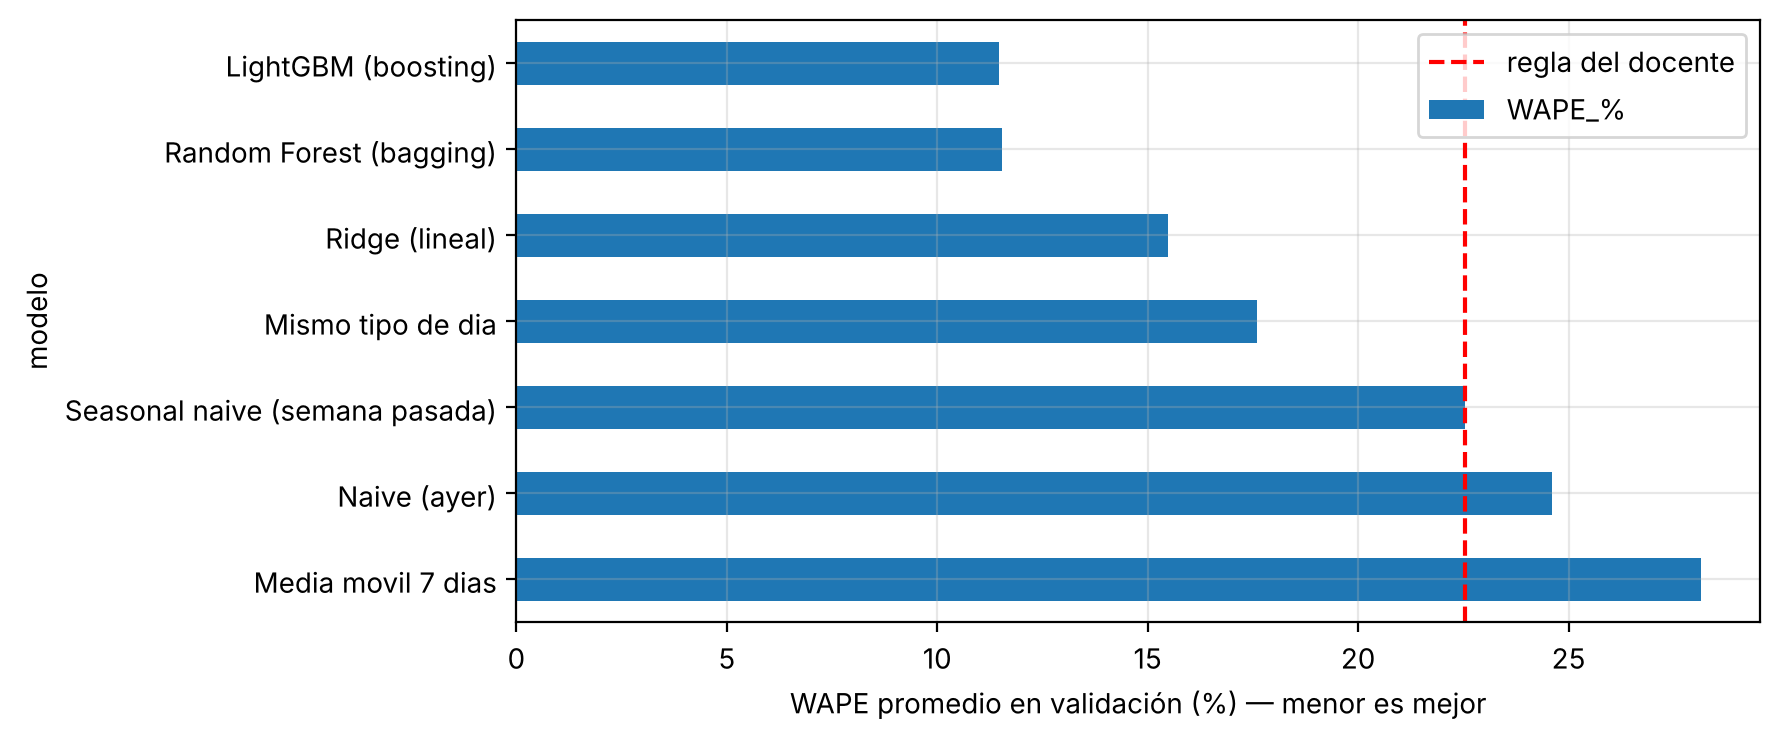

In [27]:
# =============================================================================
# 7.3 Comparación de familias (configuración razonable por defecto, antes de ajustar)
# =============================================================================
res_val = pd.concat([res_val,
    evaluar_walk_forward("Ridge (lineal)", lambda: ModeloEnergia("ridge")),
    evaluar_walk_forward("Random Forest (bagging)", lambda: ModeloEnergia("rf")),
    evaluar_walk_forward("LightGBM (boosting)", lambda: ModeloEnergia("lgbm")),
], ignore_index=True)

tabla_familias = res_val.groupby("modelo")[["WAPE_%", "MAE_kWh", "RMSE_kWh", "MASE", "sesgo_%"]].mean().sort_values("WAPE_%")
display(tabla_familias.round(3))
ax = tabla_familias["WAPE_%"].sort_values(ascending=False).plot.barh(figsize=(9, 3.8), color="tab:blue")
ax.axvline(tabla_familias.loc["Seasonal naive (semana pasada)", "WAPE_%"], color="red", ls="--", label="regla del docente")
ax.set_xlabel("WAPE promedio en validación (%) — menor es mejor"); ax.legend(); plt.tight_layout(); plt.show()

## 7.4 Experimentos de diseño (cada uno responde una decisión del EDA)

Todos usan LightGBM con la misma configuración base y los mismos 4 pliegues (y las mismas filas comparables), cambiando **una sola cosa** a la vez:

| Experimento | Pregunta |
|---|---|
| E1 · kWh crudos | ¿Sirve normalizar por `nivel_7d` (H6)? |
| E2 · Modelos locales | ¿Es mejor un modelo por subestación que un modelo global (H6)? |
| E3 · + clima de ayer | ¿Aporta el clima observado del día anterior (H7)? |
| E4 · + clima oráculo | ¿Cuánto ganaríamos con un pronóstico del clima perfecto (H7)? **No desplegable.** |
| E5 · Sin días atípicos | ¿Conviene sacar los días atípicos del entrenamiento (H8)? |

In [28]:
# =============================================================================
# 7.4 Experimentos de diseño
# =============================================================================
VARS_CRUDAS = VARS_CONSUMO + ["total_ayer", "razon_24_168", "nivel_7d"] + VARS_CAL + CATEGORICAS

class ModeloLocal:
    # Un LightGBM independiente por subestación (para comparar contra el modelo global)
    def fit(self, df):
        self.m = {k: ModeloEnergia("lgbm", [v for v in VARS_BASE if v != "subestacion"]).fit(g)
                  for k, g in df.groupby("subestacion", observed=True)}
        return self
    def predict(self, df):
        p = np.zeros(len(df))
        for k, g in df.groupby("subestacion", observed=True):
            p[(df.subestacion == k).values] = self.m[k].predict(g)
        return p

# Días atípicos (regla A) como conjunto de pares (subestación, fecha)
atip_set = set(map(tuple, atipicos.loc[atipicos.dia_atipico, ["subestacion", "fecha"]].values))
def es_atipico(df):
    return pd.Series([(s, f) in atip_set for s, f in zip(df.subestacion.astype(str), df.timestamp.dt.normalize())], index=df.index)

experimentos = pd.concat([
    evaluar_walk_forward("E1 · LightGBM kWh crudos", lambda: ModeloEnergia("lgbm", VARS_CRUDAS, relativo=False), guardar=False),
    evaluar_walk_forward("E2 · LightGBM local (9 modelos)", lambda: ModeloLocal(), guardar=False),
    evaluar_walk_forward("E3 · LightGBM + clima de ayer", lambda: ModeloEnergia("lgbm", VARS_BASE + VARS_CLIMA_AYER), guardar=False),
    evaluar_walk_forward("E4 · LightGBM + clima ORÁCULO", lambda: ModeloEnergia("lgbm", VARS_BASE + VARS_CLIMA_AYER + VARS_ORACULO), guardar=False),
    evaluar_walk_forward("E5 · LightGBM sin días atípicos", lambda: ModeloEnergia("lgbm"), filtro_entrenamiento=lambda d: ~es_atipico(d), guardar=False),
], ignore_index=True)

ref = res_val[res_val.modelo == "LightGBM (boosting)"]
comp_exp = pd.concat([ref, experimentos]).pivot(index="modelo", columns="pliegue", values="WAPE_%")
comp_exp["promedio"] = comp_exp.mean(axis=1)
comp_exp["diferencia_vs_base"] = comp_exp.promedio - comp_exp.loc["LightGBM (boosting)", "promedio"]
comp_exp.round(2)

E1 · LightGBM kWh crudos                      WAPE medio = 11.86 %   (14 s)


E2 · LightGBM local (9 modelos)               WAPE medio = 11.47 %   (36 s)


E3 · LightGBM + clima de ayer                 WAPE medio = 11.44 %   (16 s)


E4 · LightGBM + clima ORÁCULO                 WAPE medio = 11.43 %   (15 s)


E5 · LightGBM sin días atípicos               WAPE medio = 11.65 %   (14 s)


pliegue,F1,F2,F3,F4,promedio,diferencia_vs_base
modelo,,,,,,
E1 · LightGBM kWh crudos,13.87,10.12,12.34,11.11,11.86,0.40
E2 · LightGBM local (9 modelos),14.28,10.19,11.57,9.85,11.47,0.01
E3 · LightGBM + clima de ayer,13.42,10.15,11.65,10.54,11.44,-0.02
E4 · LightGBM + clima ORÁCULO,13.51,10.10,11.62,10.51,11.43,-0.03
E5 · LightGBM sin días atípicos,13.87,9.97,11.97,10.77,11.65,0.18
LightGBM (boosting),13.49,10.07,11.67,10.62,11.46,0.00


**Lectura de los experimentos** (diferencia en puntos de WAPE frente al LightGBM base; positivo = empeora):

- **E1 (+0,40):** usar kWh crudos empeora en los 4 pliegues → ✅ **mantenemos la normalización por `nivel_7d`**.
- **E2 (+0,01):** 9 modelos locales dan un resultado **casi igual** (empate técnico): peores en abril y mayo (SUB3 con muy poca historia), mejores en junio y julio. ✅ **Modelo global** por estabilidad y simplicidad (un solo modelo que mantener y que ayuda a las series cortas), no porque la evidencia de error sea contundente.
- **E3 (−0,02):** el clima de ayer (temperatura media y máxima, precipitación; NASA POWER) **no mejora de forma apreciable** en validación (0,02 puntos, dentro del ruido entre pliegues) → ✅ **no se incluye** (menos variables, menos dependencia de una fuente externa).
- **E4 (−0,03):** ni siquiera la temperatura **real** del mismo día (imposible en la práctica) mejora el pronóstico de forma apreciable en validación. Es coherente con H7: el efecto de la temperatura parece estar ya dentro de los rezagos de consumo. **Alcance de la conclusión:** vale para **las variables probadas** y para su desempeño en validación; no se concluye que el clima en general no importe (la radiación, que podría afectar a SUB5/SUB4/SUB6, no se pudo probar fuera de muestra).
- **E5 (+0,18):** quitar los días atípicos del entrenamiento **empeora ligeramente** (en 3 de los 4 pliegues) → ✅ **se conservan**: los días "raros" también enseñan (por ejemplo, días nublados en SUB5). La diferencia es pequeña. Su error se reporta aparte.

⚠️ La **radiación solar** (no la temperatura) sí podría ayudar en SUB5/SUB6 a la hora del mediodía (H7). La radiación de NASA POWER no está disponible para el periodo de test y no hay pronósticos históricos de radiación, así que queda como **recomendación** (Sección 14).

---
# 8. Ajuste sistemático de hiperparámetros (test intacto)

🧠 **Idea dummie:** los hiperparámetros son "perillas" del modelo (cuántos árboles, qué tan profundos, qué tan rápido aprende). En lugar de moverlas a ojo, usamos **Optuna**: prueba combinaciones de forma inteligente (algoritmo TPE: aprende de los intentos anteriores qué zonas del espacio son prometedoras) y se queda con la que da **menor WAPE promedio en los 4 pliegues de validación**. El test **no participa**.

**Espacio de búsqueda de LightGBM (y por qué):**

| Hiperparámetro | Rango | Justificación |
|---|---|---|
| `n_estimators` | 200 – 1000 | número de árboles; más árboles + tasa baja = aprendizaje más fino |
| `learning_rate` | 0,01 – 0,1 (log) | rango estándar; se explora en escala logarítmica |
| `num_leaves` | 15 – 127 | complejidad de cada árbol (controla sesgo vs varianza) |
| `min_child_samples` | 10 – 200 | mínimo de filas por hoja: evita aprender ruido |
| `subsample`, `colsample_bytree` | 0,5 – 1 | aleatoriedad por filas y columnas (reduce varianza) |
| `reg_lambda` | 0,001 – 10 (log) | regularización L2 de las hojas |
| `objective` | l1, l2, huber | L1 se alinea con el WAPE; L2 con el RMSE; Huber es intermedio |

Para **Random Forest** probamos una rejilla pequeña de `min_samples_leaf` y `max_features`, y para **Ridge** la **curva de validación** de `alpha` (Sección 10).

Optuna: 25 pruebas en 6.2 min
Mejor WAPE en validación: 11.17 %  (config base: 11.40 %)
Mejores hiperparámetros: {'n_estimators': 400, 'learning_rate': 0.06587345536472146, 'num_leaves': 126, 'min_child_samples': 18, 'subsample': 0.54248555911114, 'colsample_bytree': 0.6812261325085811, 'reg_lambda': 0.010707791750527235, 'objective': 'l1'}


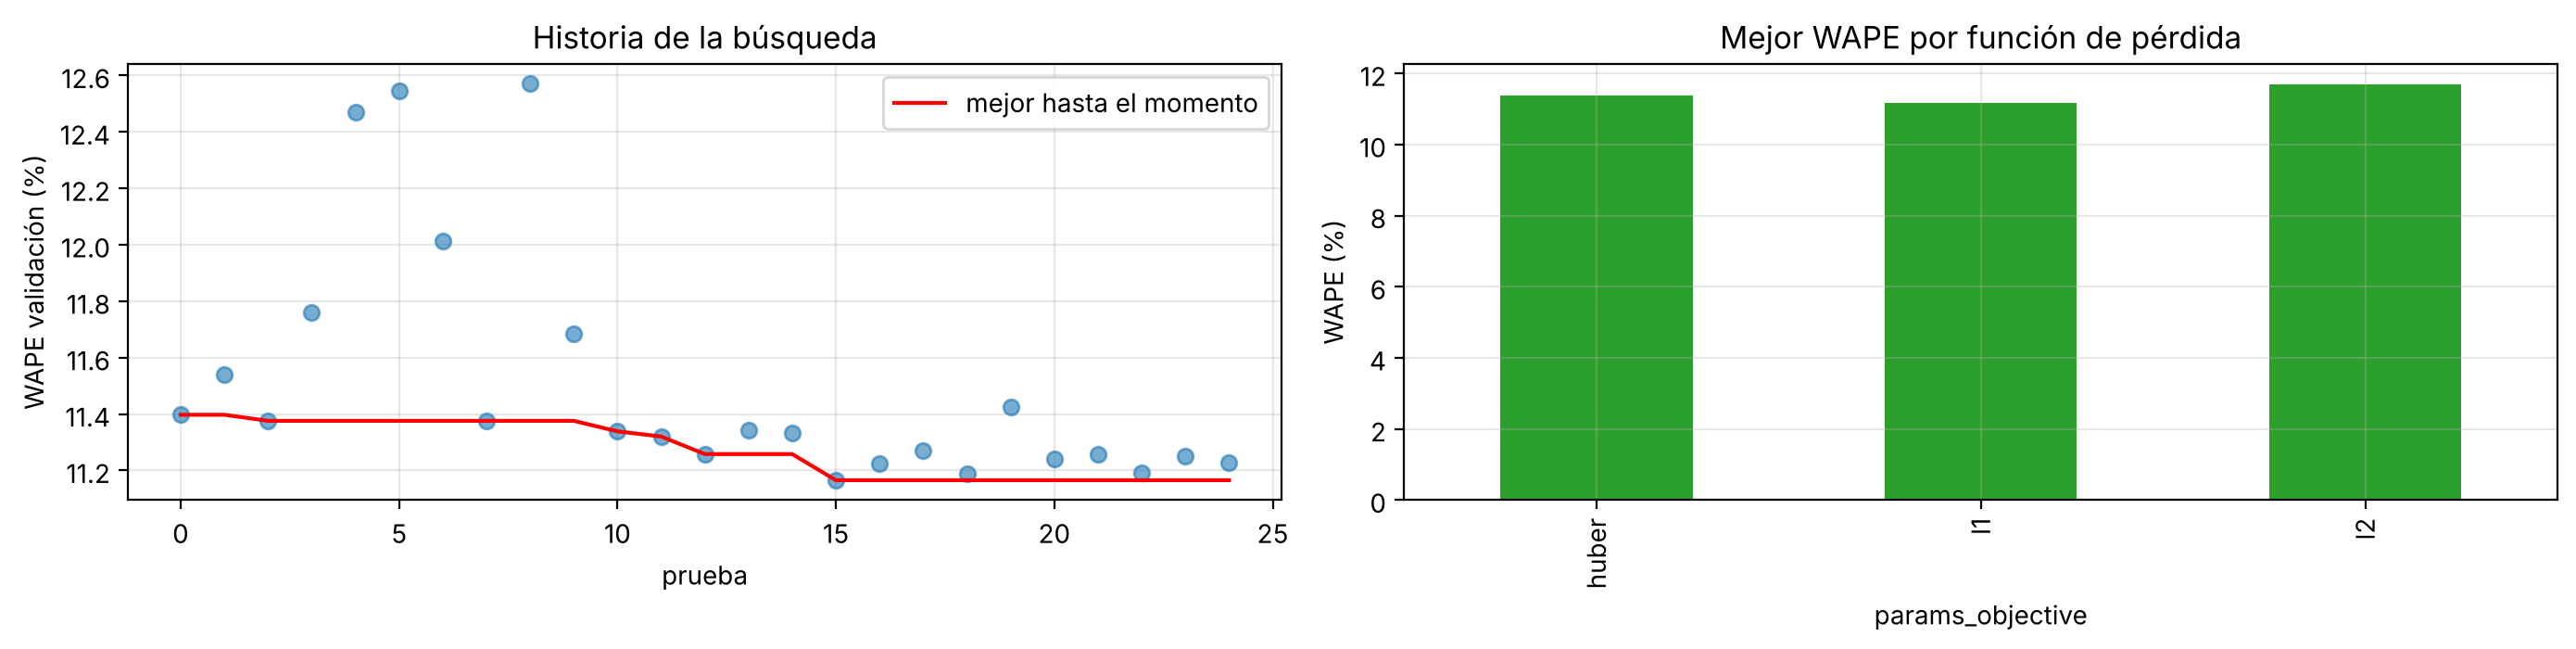

In [29]:
# =============================================================================
# 8.1 Optuna para LightGBM (objetivo: WAPE promedio en walk-forward)
# =============================================================================
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def wape_folds(params):
    errores = []
    for a, b in FOLDS_VALIDACION:
        tr = desarrollo[desarrollo.timestamp < a]
        va = desarrollo[(desarrollo.timestamp >= a) & (desarrollo.timestamp < b)]
        va = va[va.comparable]                                           # mismas filas que usa el ranking de validación
        p = ModeloEnergia("lgbm", params=params).fit(tr).predict(va)
        errores.append(100 * wape(va.kwh.values, p))
    return np.mean(errores)

def objetivo(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "objective": trial.suggest_categorical("objective", ["l1", "l2", "huber"]),
    }
    return wape_folds(params)

t0 = time.time()
estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.enqueue_trial({"n_estimators": 600, "learning_rate": 0.03, "num_leaves": 31, "min_child_samples": 50,
                       "subsample": 0.8, "colsample_bytree": 0.8, "reg_lambda": 0.001, "objective": "l1"})  # punto de partida = config base
estudio.optimize(objetivo, n_trials=N_TRIALS_OPTUNA)
MEJORES_LGBM = estudio.best_params
json.dump(MEJORES_LGBM, open(RES / "mejores_parametros_lgbm.json", "w"), indent=2)
print(f"Optuna: {len(estudio.trials)} pruebas en {(time.time()-t0)/60:.1f} min")
print(f"Mejor WAPE en validación: {estudio.best_value:.2f} %  (config base: {estudio.trials[0].value:.2f} %)")
print("Mejores hiperparámetros:", MEJORES_LGBM)

hist = estudio.trials_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
axes[0].plot(hist.number, hist.value, "o", alpha=0.6); axes[0].plot(hist.number, hist.value.cummin(), "r-", label="mejor hasta el momento")
axes[0].set_xlabel("prueba"); axes[0].set_ylabel("WAPE validación (%)"); axes[0].set_title("Historia de la búsqueda"); axes[0].legend()
hist.groupby("params_objective").value.min().plot.bar(ax=axes[1], color="tab:green")
axes[1].set_title("Mejor WAPE por función de pérdida"); axes[1].set_ylabel("WAPE (%)")
plt.tight_layout(); plt.show()

In [30]:
# =============================================================================
# 8.2 Rejilla pequeña para Random Forest
# =============================================================================
rejilla_rf = [{"min_samples_leaf": l, "max_features": f} for l in (5, 20) for f in (0.33, 0.6)]
res_rf = []
for p in rejilla_rf:
    r = evaluar_walk_forward(f"RF {p}", lambda p=p: ModeloEnergia("rf", params=p), guardar=False)
    res_rf.append({**p, "WAPE_%": r["WAPE_%"].mean()})
res_rf = pd.DataFrame(res_rf).sort_values("WAPE_%")
display(res_rf.round(3))
MEJORES_RF = res_rf.iloc[0][["min_samples_leaf", "max_features"]].to_dict()
MEJORES_RF["min_samples_leaf"] = int(MEJORES_RF["min_samples_leaf"])
print("Mejor Random Forest:", MEJORES_RF)

RF {'min_samples_leaf': 5, 'max_features': 0.33} WAPE medio = 11.46 %   (55 s)


RF {'min_samples_leaf': 5, 'max_features': 0.6} WAPE medio = 11.46 %   (102 s)


RF {'min_samples_leaf': 20, 'max_features': 0.33} WAPE medio = 11.79 %   (44 s)


RF {'min_samples_leaf': 20, 'max_features': 0.6} WAPE medio = 11.81 %   (82 s)


,min_samples_leaf,max_features,WAPE_%
1,5,0.60,11.455
0,5,0.33,11.458
2,20,0.33,11.791
3,20,0.60,11.807


Mejor Random Forest: {'min_samples_leaf': 5, 'max_features': 0.6}


---
# 9. Selección del modelo (y ensamble de ensambles)

Evaluamos las versiones **ajustadas** con los mismos pliegues y agregamos un **ensamble**: el promedio simple de las predicciones de LightGBM y Random Forest. 🧠 Si dos modelos se equivocan en cosas distintas, su promedio se equivoca menos que cada uno.

**Regla de selección (fijada antes de mirar el test):** menor WAPE promedio en validación; si dos candidatos están a menos de 0,1 puntos, se prefiere el más simple.

LightGBM ajustado                             WAPE medio = 11.17 %   (16 s)


Random Forest ajustado                        WAPE medio = 11.46 %   (110 s)


Ensamble LightGBM + RF                        WAPE medio = 11.09 %   (128 s)


,WAPE_medio,WAPE_desv,MAE,RMSE,MASE,sesgo
modelo,,,,,,
Ensamble LightGBM + RF,11.090,1.253,41.587,93.134,0.554,-0.651
LightGBM ajustado,11.166,1.204,41.865,94.489,0.557,-0.641
Random Forest ajustado,11.455,1.434,42.965,94.334,0.574,-0.662
LightGBM (boosting),11.462,1.508,42.985,98.073,0.572,-1.020
Random Forest (bagging),11.548,1.392,43.316,94.551,0.577,-0.586
Ridge (lineal),15.483,1.143,58.050,111.129,0.754,0.529
Mismo tipo de dia,17.598,1.792,66.114,161.257,0.849,0.077
Seasonal naive (semana pasada),22.550,4.652,84.641,190.972,1.130,-0.610
Naive (ayer),24.611,2.415,92.392,211.341,1.210,-0.327



✅ MODELO ELEGIDO: LightGBM ajustado  (WAPE validación = 11.17 %)
   Regla del docente (semana pasada): 22.55 %


modelo,Ensamble LightGBM + RF,LightGBM ajustado,Mismo tipo de dia,Random Forest ajustado,Ridge (lineal),Seasonal naive (semana pasada)
pliegue,,,,,,
F1,12.77,12.74,19.73,13.44,16.73,29.37
F2,10.09,10.16,18.23,10.35,15.13,19.85
F3,11.33,11.48,16.88,11.58,15.99,21.63
F4,10.18,10.28,15.56,10.45,14.08,19.34


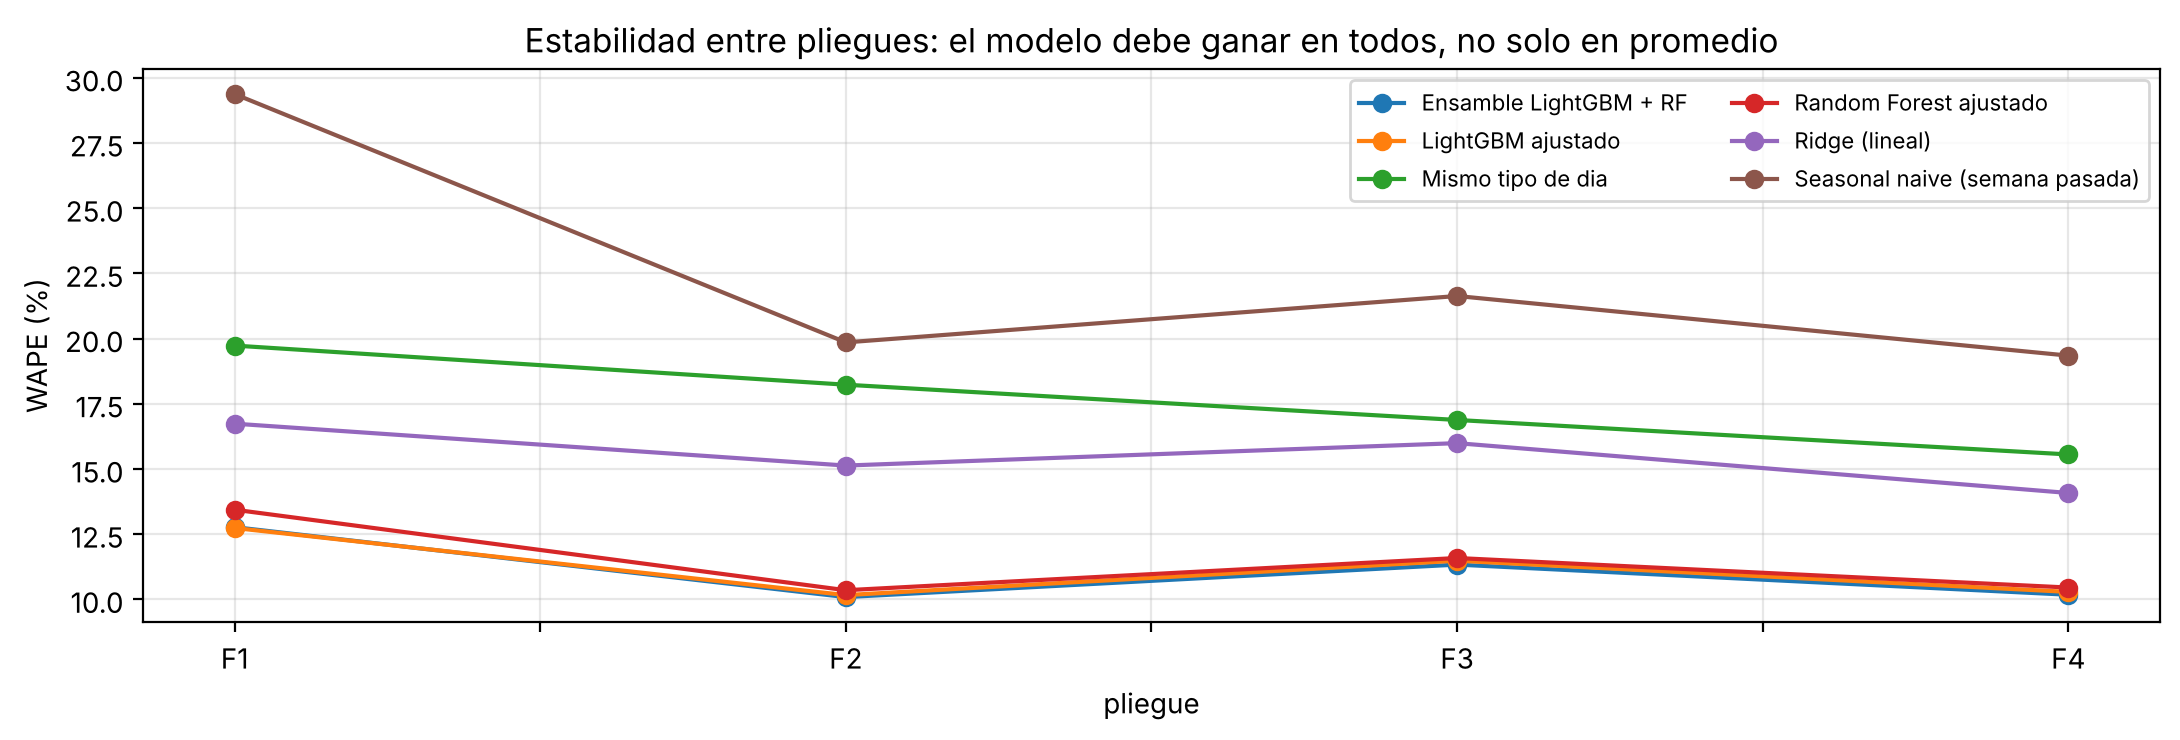

In [31]:
# =============================================================================
# 9.1 Modelos ajustados + ensamble, y selección final
# =============================================================================
class Ensamble:
    # Promedio simple de varios modelos (cada uno entrenado por separado)
    def __init__(self, fabricas): self.fabricas = fabricas
    def fit(self, df): self.modelos = [f().fit(df) for f in self.fabricas]; return self
    def predict(self, df): return np.mean([m.predict(df) for m in self.modelos], axis=0)

FABRICAS = {
    "LightGBM ajustado": lambda: ModeloEnergia("lgbm", params=MEJORES_LGBM),
    "Random Forest ajustado": lambda: ModeloEnergia("rf", params=MEJORES_RF),
}
FABRICAS["Ensamble LightGBM + RF"] = lambda: Ensamble([FABRICAS["LightGBM ajustado"], FABRICAS["Random Forest ajustado"]])

res_val = pd.concat([res_val] + [evaluar_walk_forward(n, f) for n, f in FABRICAS.items()], ignore_index=True)

ranking = res_val.groupby("modelo").agg(WAPE_medio=("WAPE_%", "mean"), WAPE_desv=("WAPE_%", "std"),
                                        MAE=("MAE_kWh", "mean"), RMSE=("RMSE_kWh", "mean"),
                                        MASE=("MASE", "mean"), sesgo=("sesgo_%", "mean")).sort_values("WAPE_medio")
display(ranking.round(3))

# Selección automática con la regla anunciada
simplicidad = {"Ensamble LightGBM + RF": 3, "LightGBM ajustado": 2, "Random Forest ajustado": 2, "LightGBM (boosting)": 2,
               "Random Forest (bagging)": 2, "Ridge (lineal)": 1}
candidatos = ranking[ranking.index.isin(FABRICAS.keys())]
mejor = candidatos.WAPE_medio.min()
empatados = candidatos[candidatos.WAPE_medio <= mejor + 0.1]
MODELO_ELEGIDO = min(empatados.index, key=lambda n: (simplicidad.get(n, 9), empatados.loc[n, "WAPE_medio"]))
print(f"\n✅ MODELO ELEGIDO: {MODELO_ELEGIDO}  (WAPE validación = {ranking.loc[MODELO_ELEGIDO, 'WAPE_medio']:.2f} %)")
print(f"   Regla del docente (semana pasada): {ranking.loc['Seasonal naive (semana pasada)', 'WAPE_medio']:.2f} %")

piv = res_val[res_val.modelo.isin(["Seasonal naive (semana pasada)", "Mismo tipo de dia", "Ridge (lineal)",
                                    "Random Forest ajustado", "LightGBM ajustado", "Ensamble LightGBM + RF"])]
piv = piv.pivot(index="pliegue", columns="modelo", values="WAPE_%")
display(piv.round(2))                                  # WAPE de cada modelo en cada pliegue (para verificar que gana en todos)
piv.plot(marker="o", figsize=(11, 3.8)); plt.ylabel("WAPE (%)")
plt.title("Estabilidad entre pliegues: el modelo debe ganar en todos, no solo en promedio"); plt.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Lectura de la selección:**
- Todos los modelos de árboles (Random Forest, LightGBM y su ensamble) **reducen el error a la mitad** frente a la regla "semana pasada" (≈ 11 % vs ≈ 22,6 % de WAPE en validación); la tabla por pliegue permite comprobar que le ganan en **cada** pliegue, no solo en el promedio.
- Ridge queda en un punto intermedio (≈ 15,5 %): mejor que los baselines, peor que los árboles.
- **Optuna** mejoró a LightGBM ≈ 0,3 puntos frente a la configuración base (11,46 → 11,17), con árboles más complejos (`num_leaves` ≈ 126, hojas de al menos 18 filas) y menos filas y columnas por árbol.
- **El ensamble LightGBM + RF queda apenas 0,08 puntos por delante del LightGBM ajustado** (11,09 vs 11,17). La regla de selección, anunciada **antes** de ver el test, dice: "si dos candidatos están a menos de 0,1 puntos, gana el más simple". La diferencia **no llega** a 0,1, así que la regla elige **LightGBM ajustado**: un solo modelo que mantener y explicar. (En la versión anterior, con el calendario tentativo, el ensamble ganaba por 0,17 puntos y fue el elegido; con el calendario oficial LightGBM mejoró y la regla cambió la elección automáticamente.)

---
# 10. Diagnóstico: ¿sesgo o varianza? ¿dónde se equivoca?

🧠 **Idea dummie:**
- **Sesgo alto** (*underfitting*): el modelo es demasiado simple; se equivoca igual en entrenamiento y en validación.
- **Varianza alta** (*overfitting*): el modelo memoriza; le va muy bien en entrenamiento y mal en validación.

Dos herramientas:
1. **Curva de aprendizaje:** ¿mejora la validación si le damos más meses de historia?
2. **Curva de validación:** ¿qué pasa al aumentar la complejidad (hojas por árbol en LightGBM, `alpha` en Ridge)?

Usamos el pliegue de **julio-2026** (el más reciente de validación).

,meses,filas,WAPE_entrenamiento,WAPE_validacion
0,1,6466,4.05,13.70
1,2,13135,4.19,12.33
2,3,19535,4.84,11.78
3,4,25929,5.30,11.47
4,6,35403,5.96,10.72
5,9,51694,6.87,10.34
6,12,67107,7.10,10.16
7,15,78194,7.39,10.33


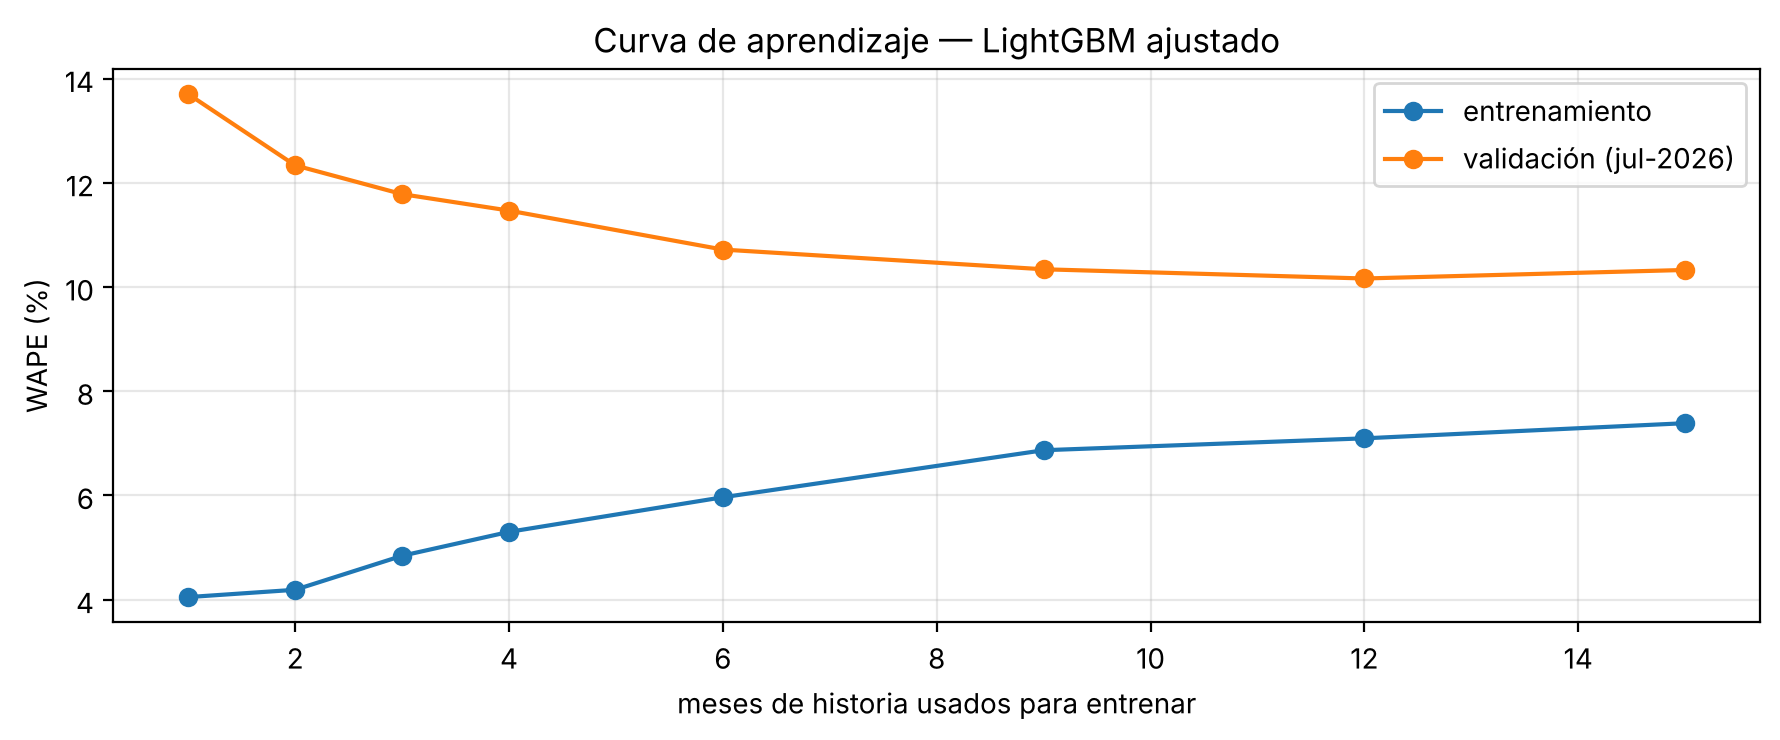

In [32]:
# =============================================================================
# 10.1 Curva de aprendizaje (más historia → ¿mejor?)
# =============================================================================
a, b = FOLDS_VALIDACION[-1]
va = desarrollo[(desarrollo.timestamp >= a) & (desarrollo.timestamp < b)]
curva = []
for meses in [1, 2, 3, 4, 6, 9, 12, 15]:
    inicio = pd.Timestamp(a) - pd.DateOffset(months=meses)
    tr = desarrollo[(desarrollo.timestamp >= inicio) & (desarrollo.timestamp < a)]
    m = ModeloEnergia("lgbm", params=MEJORES_LGBM).fit(tr)
    curva.append({"meses": meses, "filas": len(tr),
                  "WAPE_entrenamiento": 100 * wape(tr.kwh.values, m.predict(tr)),
                  "WAPE_validacion": 100 * wape(va.kwh.values, m.predict(va))})
curva = pd.DataFrame(curva); display(curva.round(2))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(curva.meses, curva.WAPE_entrenamiento, "o-", label="entrenamiento")
ax.plot(curva.meses, curva.WAPE_validacion, "o-", label="validación (jul-2026)")
ax.set_xlabel("meses de historia usados para entrenar"); ax.set_ylabel("WAPE (%)"); ax.legend()
ax.set_title("Curva de aprendizaje — LightGBM ajustado"); plt.tight_layout(); plt.show()

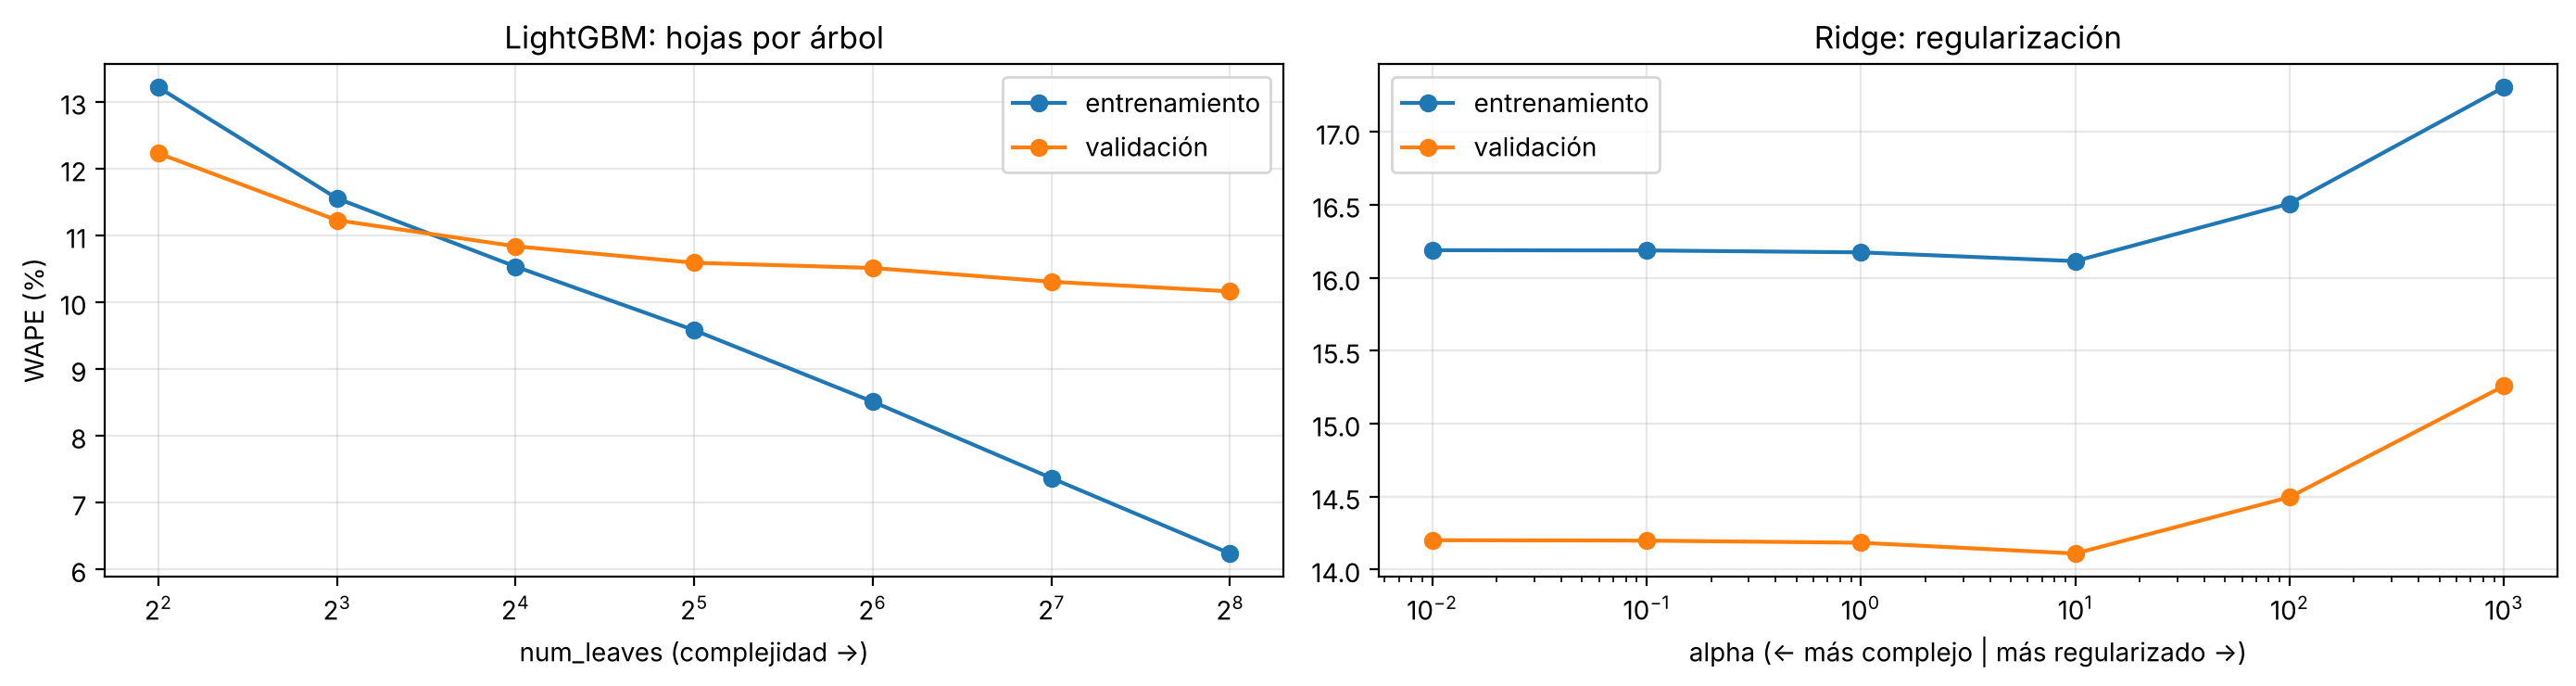

,0,1,2,3,4,5,6
num_leaves,4.00,8.00,16.00,32.00,64.00,128.00,256.00
entrenamiento,13.22,11.56,10.53,9.58,8.51,7.37,6.24
validacion,12.23,11.23,10.84,10.59,10.51,10.31,10.16


,0,1,2,3,4,5
alpha,0.01,0.10,1.00,10.00,100.00,1000.00
entrenamiento,16.19,16.19,16.17,16.11,16.51,17.31
validacion,14.20,14.20,14.18,14.11,14.50,15.26


In [33]:
# =============================================================================
# 10.2 Curvas de validación (complejidad del modelo)
# =============================================================================
tr = desarrollo[desarrollo.timestamp < a]
cv_lgb = []
for hojas in [4, 8, 16, 32, 64, 128, 256]:
    p = {**MEJORES_LGBM, "num_leaves": hojas}
    m = ModeloEnergia("lgbm", params=p).fit(tr)
    cv_lgb.append({"num_leaves": hojas, "entrenamiento": 100 * wape(tr.kwh.values, m.predict(tr)),
                   "validacion": 100 * wape(va.kwh.values, m.predict(va))})
cv_lgb = pd.DataFrame(cv_lgb)
cv_ridge = []
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    m = ModeloEnergia("ridge", params={"alpha": alpha}).fit(tr)
    cv_ridge.append({"alpha": alpha, "entrenamiento": 100 * wape(tr.kwh.values, m.predict(tr)),
                     "validacion": 100 * wape(va.kwh.values, m.predict(va))})
cv_ridge = pd.DataFrame(cv_ridge)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(cv_lgb.num_leaves, cv_lgb.entrenamiento, "o-", label="entrenamiento")
axes[0].plot(cv_lgb.num_leaves, cv_lgb.validacion, "o-", label="validación")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("num_leaves (complejidad →)"); axes[0].set_ylabel("WAPE (%)")
axes[0].set_title("LightGBM: hojas por árbol"); axes[0].legend()
axes[1].plot(cv_ridge.alpha, cv_ridge.entrenamiento, "o-", label="entrenamiento")
axes[1].plot(cv_ridge.alpha, cv_ridge.validacion, "o-", label="validación")
axes[1].set_xscale("log"); axes[1].set_xlabel("alpha (← más complejo | más regularizado →)")
axes[1].set_title("Ridge: regularización"); axes[1].legend()
plt.tight_layout(); plt.show()
display(cv_lgb.round(2).T); display(cv_ridge.round(2).T)

**Lectura del diagnóstico:**
- **Ridge** tiene un error alto y casi igual en entrenamiento (≈ 16 %) y validación (≈ 14 %), sin importar `alpha` (el de validación es algo menor porque julio fue un mes "fácil") → **sesgo alto**: la relación es no lineal (interacciones entre hora, tipo de día, periodo y subestación) y un modelo lineal no la alcanza. Regularizar más (alpha grande) solo empeora.
- **LightGBM** (curva de validación con los demás hiperparámetros fijos): con 4-8 hojas ambos errores son altos (**sesgo**). Al aumentar las hojas el error de entrenamiento baja siempre (13,2 % → 6,2 %) y el de validación también, pero cada vez más despacio (10,59 % con 32 hojas, 10,31 % con 128, 10,16 % con 256), mientras la brecha entre los dos crece de ≈ 1 a ≈ 4 puntos: más complejidad todavía paga un poco, pero el modelo empieza a memorizar (**varianza**). Optuna eligió ≈ 126 hojas, donde la mejora ya es marginal.
- **Curva de aprendizaje** (LightGBM ajustado): con 1 mes de historia la brecha entre entrenamiento (≈ 4,1 %) y validación (≈ 13,7 %) es enorme: **varianza**, el modelo memoriza pocos días. Al agregar meses, el error de validación baja hasta ≈ 10,2 % con 12 meses y luego se estabiliza (10,33 % con 15), y la brecha se reduce a ≈ 3 puntos (7,4 % vs 10,3 %). Conclusión: queda algo de **varianza** (los hiperparámetros elegidos permiten hojas pequeñas, de 18 filas), pero la curva de validación ya está plana, así que **más meses de consumo ayudarán poco**; el error que queda viene sobre todo de lo que **ninguna variable explica** (eventos, nubes, maniobras). **Más contexto (agenda de eventos, radiación) ayudaría más que más historia.**


--- Error por subestacion ---


,WAPE_modelo_%,WAPE_semana_pasada_%,horas
subestacion,,,
SUB1,16.01,27.89,2646
SUB2,9.62,22.76,2664
SUB3,8.46,17.98,2908
SUB4,7.60,17.26,2928
SUB5,17.84,29.20,2549
SUB6,10.98,18.23,2913
SUB7,7.04,17.02,2914
SUB8,6.23,14.28,2913
SUB9,19.15,38.19,2813



--- Error por tipo_dia ---


,WAPE_modelo_%,WAPE_semana_pasada_%,horas
tipo_dia,,,
festivo,18.58,96.12,1847
fin de semana,16.80,23.06,6955
laboral después de no laboral,10.79,23.34,3522
laboral normal,8.95,17.20,12924



--- Error por periodo ---


,WAPE_modelo_%,WAPE_semana_pasada_%,horas
periodo,,,
clases,10.48,20.73,15045
receso,17.68,86.68,958
intersemestral,11.99,21.78,9245



--- Error por atipico ---


,WAPE_modelo_%,WAPE_semana_pasada_%,horas
atipico,,,
día atípico,29.49,36.88,1380
día normal,10.14,21.73,23868


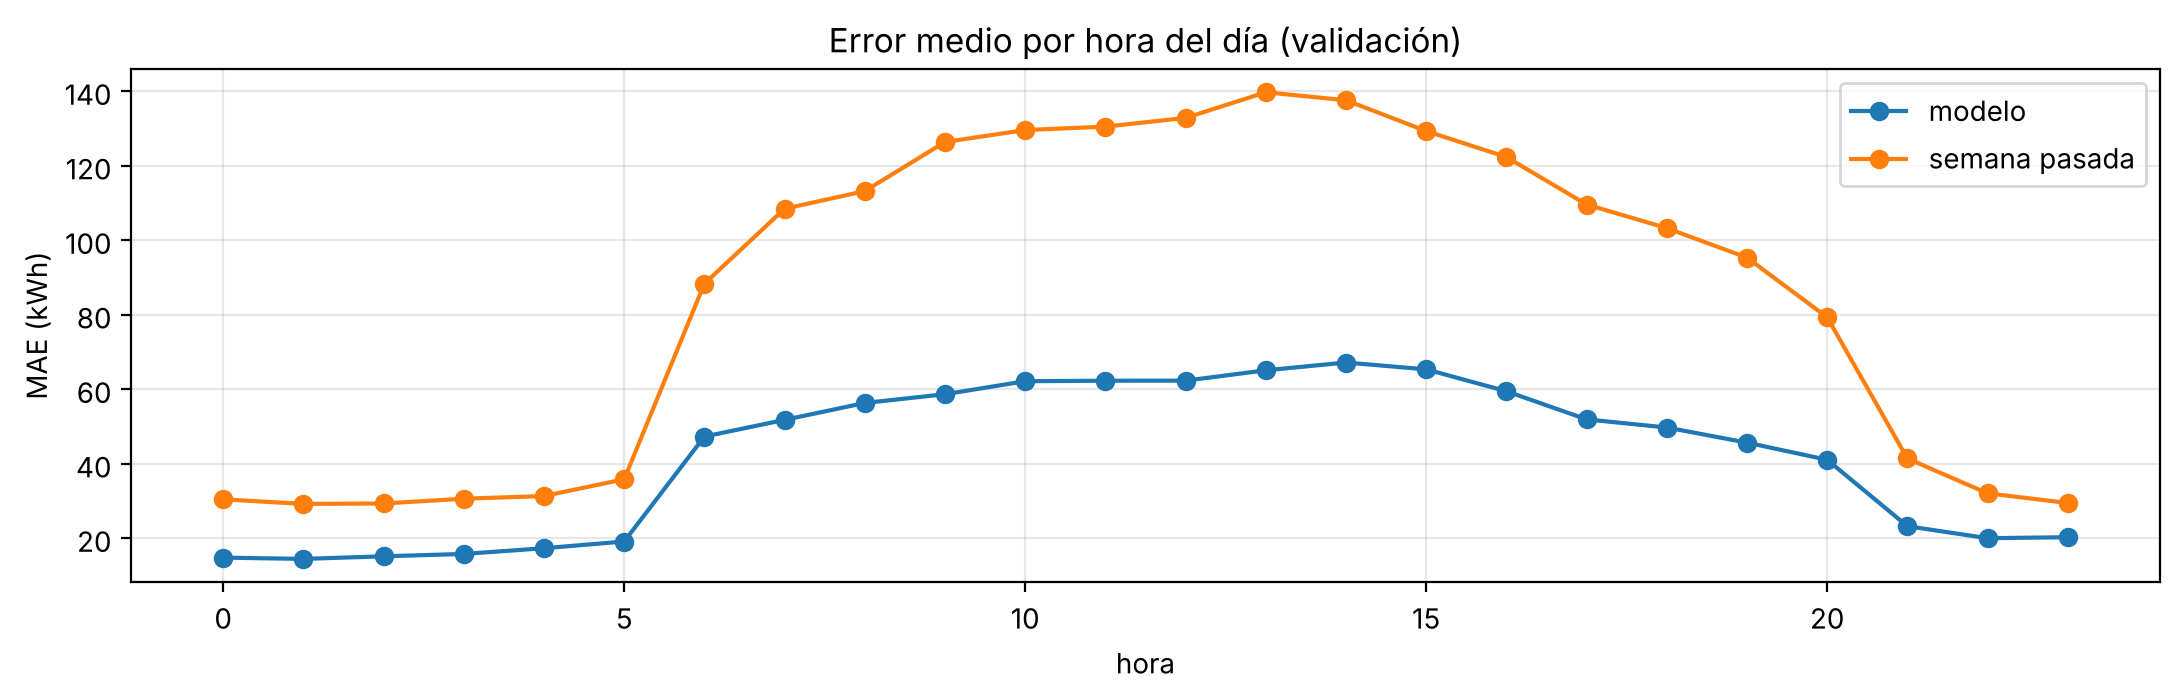

In [34]:
# =============================================================================
# 10.3 Análisis de errores por segmento (predicciones de validación del modelo elegido)
# =============================================================================
seg = desarrollo.merge(OOF[MODELO_ELEGIDO], on=["timestamp", "subestacion"])
seg = seg.merge(OOF["Seasonal naive (semana pasada)"].rename(columns={"pred": "pred_naive"}), on=["timestamp", "subestacion"])
seg["atipico"] = es_atipico(seg).map({True: "día atípico", False: "día normal"})
seg["tipo_dia"] = np.where(seg.festivo == 1, "festivo", np.where(seg.fin_semana == 1, "fin de semana",
                  np.where(seg.ayer_laboral == 0, "laboral después de no laboral", "laboral normal")))

def tabla_segmento(col):
    g = seg.groupby(col, observed=True)
    return pd.DataFrame({
        "WAPE_modelo_%": g.apply(lambda d: 100 * wape(d.kwh, d.pred)),
        "WAPE_semana_pasada_%": g.apply(lambda d: 100 * wape(d.kwh, d.pred_naive)),
        "horas": g.size()}).round(2)

for col in ["subestacion", "tipo_dia", "periodo", "atipico"]:
    print(f"\n--- Error por {col} ---"); display(tabla_segmento(col))

fig, ax = plt.subplots(figsize=(11, 3.6))
pp = seg.groupby("hora").apply(lambda d: pd.Series({"modelo": mae(d.kwh, d.pred), "semana pasada": mae(d.kwh, d.pred_naive)}))
pp.plot(ax=ax, marker="o"); ax.set_ylabel("MAE (kWh)"); ax.set_title("Error medio por hora del día (validación)")
plt.tight_layout(); plt.show()

**Lectura por segmentos:**
- El modelo le gana a la regla "semana pasada" en **todas** las subestaciones, tipos de día y periodos.
- La mayor ganancia está en los **festivos** y la **semana de receso** (la regla "semana pasada" copia días de clases y se equivoca entre 87 % y 96 %; el modelo ≈ 18 %), y en los **laborales después de un día no laboral** el error se reduce a la mitad (≈ 23 % → ≈ 11 %). Es exactamente lo que buscaban las variables de calendario y `lag_mismo_tipo` (H4 y H5).
- Las subestaciones más difíciles son **SUB5** (la compra al mediodía depende de las nubes), **SUB9** (climatización con arranques bruscos) y **SUB1**. El error se concentra en las **horas de actividad** (6:00-20:00), que son también las de mayor consumo.
- En los **días atípicos** el error es mucho mayor que en los normales. Es lo esperado: el modelo no conocía el evento. Lo importante es que **queda medido aparte** y no se esconde en el promedio.

---
# 11. Evaluación final en el TEST reservado (una sola vez)

Todo está congelado: variables, modelo elegido, hiperparámetros y regla de selección. Ahora simulamos la operación real del **1-ago al 22-oct-2026, emisión por emisión**:

- **Cada día a las 00:00** se genera el pronóstico de las 24 horas de ese día para las 9 subestaciones (216 filas) usando **solo los datos crudos hasta las 23:00 del día anterior**: se vuelve a limpiar y a construir las variables con ese corte, exactamente como se haría en producción.
- **Cada 7 días** (12 reentrenamientos, fechas impresas abajo) el modelo se reentrena con **todo lo anterior** a esa medianoche. Entre reentrenamientos el modelo no cambia.
- La selección de variables, hiperparámetros y modelo se hizo con el periodo de **desarrollo** (hasta el 31-jul); en el test no se vuelve a elegir nada.

Para transparencia, también evaluamos los demás modelos en el test, pero **la elección ya está hecha** y no cambia con lo que veamos aquí.

| ❓ Pregunta | 🔧 Qué hace el código | 🎯 Por qué | 📖 Cómo interpretarlo |
|---|---|---|---|
| ¿Funcionaría el modelo en operación real, día tras día? | Para cada día del test corta los crudos a las 23:00 previas, limpia, construye variables y predice las 24 h con el modelo vigente | Es la única forma de que "lo que se sabía a medianoche" sea literal y no una suposición | La tabla de cobertura dice cuántas horas se pronosticaron, cuántas se pudieron calificar y cuántas se pudieron comparar con la regla |

In [35]:
# =============================================================================
# 11.1 Test emisión por emisión: 83 emisiones a las 00:00, reentrenando cada 7 días
# =============================================================================
bloques = pd.date_range(INICIO_TEST, FIN_DATOS.normalize(), freq="7D")        # fechas de REENTRENAMIENTO
dias_test = pd.date_range(INICIO_TEST, FIN_DATOS.normalize(), freq="D")       # una EMISIÓN por día, a las 00:00
print(f"Reentrenamientos ({len(bloques)}), siempre con observaciones ANTERIORES a esa medianoche:")
print("  ", ", ".join(str(b.date()) for b in bloques))
print(f"Emisiones simuladas: {len(dias_test)} (del {dias_test[0].date()} al {dias_test[-1].date()})")

# --- (1) Reentrenar cada 7 días con todo lo conocido hasta la medianoche del reentrenamiento -----------------
t0 = time.time()
ENTRENADOS, MODELOS_POR_BLOQUE = {}, {}          # MODELOS_POR_BLOQUE: LightGBM de cada semana (para SHAP, sección 13)
for ini in bloques:
    tr = datos[datos.timestamp < ini]            # <- FECHA DE CORTE del entrenamiento: solo filas anteriores a las 00:00 de 'ini'
    ENTRENADOS[ini] = {"LightGBM ajustado": FABRICAS["LightGBM ajustado"]().fit(tr),
                       "Random Forest ajustado": FABRICAS["Random Forest ajustado"]().fit(tr),
                       "Ridge (lineal)": ModeloEnergia("ridge").fit(tr)}
    MODELOS_POR_BLOQUE[ini] = ENTRENADOS[ini]["LightGBM ajustado"]
print(f"{len(bloques)} reentrenamientos en {(time.time()-t0)/60:.1f} min")

# --- (2) Simular CADA emisión: a las 00:00 del día D solo se conocen los crudos hasta las 23:00 de D-1 ------
salidas = []
t0 = time.time()
for dia in dias_test:
    ini = max(b for b in bloques if b <= dia)                       # modelo vigente = último reentrenamiento anterior a D
    ultima_hora = dia - pd.Timedelta(hours=1)                       # <- CORTE DE LA EMISIÓN: último dato conocido (23:00 de D-1)
    T = tabla_desde_crudo(ancho_crudo.loc[:ultima_hora], hasta=dia + pd.Timedelta(hours=23))   # limpiar + construir variables SOLO con ese pasado
    f = T[T.timestamp.dt.normalize() == dia].copy()                 # las 24 horas × 9 subestaciones del día D (216 filas)
    f["emision"] = dia
    f["horizonte_h"] = f.timestamp.dt.hour + 1                      # 1..24 horas adelante
    f["modelo_reentrenado_el"] = ini
    puede = f.nivel_7d.notna()                                      # sin nivel_7d no se puede devolver de relativo a kWh
    for nombre, m in ENTRENADOS[ini].items():
        f[nombre] = np.nan
        f.loc[puede, nombre] = m.predict(f[puede])
    salidas.append(f[["emision", "horizonte_h", "timestamp", "subestacion", "lag_24", "lag_168", "lag_mismo_tipo",
                      "nivel_7d", "modelo_reentrenado_el", "LightGBM ajustado", "Random Forest ajustado", "Ridge (lineal)"]])
print(f"{len(dias_test)} emisiones simuladas en {(time.time()-t0)/60:.1f} min")
pred_test = pd.concat(salidas, ignore_index=True)

# --- (3) Agregar el valor real (ya limpiado con la misma regla causal) y las referencias ------------------
pred_test = pred_test.merge(tabla[["timestamp", "subestacion", "kwh"]], on=["timestamp", "subestacion"], how="left")
pred_test["Ensamble LightGBM + RF"] = pred_test[["LightGBM ajustado", "Random Forest ajustado"]].mean(axis=1)
pred_test["Seasonal naive (semana pasada)"] = pred_test.lag_168
pred_test["Mismo tipo de dia"] = pred_test.lag_mismo_tipo.fillna(pred_test.lag_168)
pred_test["pred"] = pred_test[MODELO_ELEGIDO]                       # pronóstico oficial
pred_test["atipico"] = es_atipico(pred_test)
pred_test["dia"] = pred_test.timestamp.dt.normalize()
# Tres cantidades que NO son lo mismo:
pred_test["tiene_medicion"] = pred_test.kwh.notna()                                   # hay valor real válido
pred_test["tiene_ref"] = pred_test.lag_168.notna()                                    # existe la regla "semana pasada"
pred_test["comparable"] = pred_test.tiene_medicion & pred_test.tiene_ref              # <- FILAS COMPARABLES (mismas para todos los métodos)

# Verificación: 216 combinaciones (subestación, hora) únicas por emisión
combos = pred_test.groupby("emision").apply(lambda d: d[["subestacion", "timestamp"]].drop_duplicates().shape[0])
assert (combos == 216).all(), "Alguna emisión no tiene 9 × 24 = 216 combinaciones únicas"
print(f"Cada una de las {len(combos)} emisiones tiene exactamente 216 combinaciones únicas (9 subestaciones × 24 horas) ✅")

Reentrenamientos (12), siempre con observaciones ANTERIORES a esa medianoche:
   2026-08-01, 2026-08-08, 2026-08-15, 2026-08-22, 2026-08-29, 2026-09-05, 2026-09-12, 2026-09-19, 2026-09-26, 2026-10-03, 2026-10-10, 2026-10-17
Emisiones simuladas: 83 (del 2026-08-01 al 2026-10-22)


12 reentrenamientos en 8.8 min


83 emisiones simuladas en 0.7 min
Cada una de las 83 emisiones tiene exactamente 216 combinaciones únicas (9 subestaciones × 24 horas) ✅


### Cobertura del test: horas planeadas, con medición válida y comparables

🧠 **Idea dummie:** no todas las horas planeadas se pueden calificar. Si el medidor falló, **no hay real** contra qué comparar; y si hace una semana el medidor falló, **no existe la regla "semana pasada"**. Contamos las tres cosas por separado para no mezclar "cuántas horas pronosticamos" con "cuántas horas podemos comparar".

In [36]:
# =============================================================================
# 11.1b Cobertura: planeadas -> con medición válida -> comparables con la regla
# =============================================================================
cob = pred_test.groupby("subestacion", observed=True).agg(
    horas_planeadas=("kwh", "size"), con_medicion_valida=("tiene_medicion", "sum"),
    con_referencia_semanal=("tiene_ref", "sum"), comparables=("comparable", "sum"),
    modelo_puede_pronosticar=("pred", lambda s: s.notna().sum()))
cob.loc["TOTAL"] = cob.sum()
cob["% comparables"] = (100 * cob.comparables / cob.horas_planeadas).round(1)
display(cob)
print(f"Planeadas: {len(pred_test):,} | con medición válida: {int(pred_test.tiene_medicion.sum()):,} | "
      f"comparables con la regla: {int(pred_test.comparable.sum()):,}")

,horas_planeadas,con_medicion_valida,con_referencia_semanal,comparables,modelo_puede_pronosticar,% comparables
subestacion,,,,,,
SUB1,1992,1989,1990,1987,1992,99.7
SUB2,1992,1990,1990,1988,1992,99.8
SUB3,1992,1992,1992,1992,1992,100.0
SUB4,1992,1992,1992,1992,1992,100.0
SUB5,1992,1934,1933,1908,1992,95.8
SUB6,1992,1989,1989,1986,1992,99.7
SUB7,1992,1992,1992,1992,1992,100.0
SUB8,1992,1992,1992,1992,1992,100.0
SUB9,1992,1992,1992,1992,1992,100.0


Planeadas: 17,928 | con medición válida: 17,862 | comparables con la regla: 17,829


In [37]:
# =============================================================================
# 11.1c Métricas del test: TODOS los métodos sobre LAS MISMAS filas comparables
# =============================================================================
cmp = pred_test[pred_test.comparable & pred_test.pred.notna()].copy()                 # filas comparables (reales + regla + modelo)
esc_test = escala_mase(datos[datos.timestamp < INICIO_TEST])                           # escala del MASE: solo con el entrenamiento previo
cols_modelos = ["Seasonal naive (semana pasada)", "Mismo tipo de dia", "Ridge (lineal)", "Random Forest ajustado",
                "LightGBM ajustado", "Ensamble LightGBM + RF"]
res_test = pd.DataFrame({c: metricas(cmp, c, esc_test) for c in cols_modelos}).T.round(3)
res_test["elegido"] = np.where(res_test.index == MODELO_ELEGIDO, "✅", "")
res_test["filas"] = len(cmp)
display(res_test.sort_values("WAPE_%"))
mejora = 1 - res_test.loc[MODELO_ELEGIDO, "WAPE_%"] / res_test.loc["Seasonal naive (semana pasada)", "WAPE_%"]
print(f"El modelo elegido reduce el error de la regla 'semana pasada' en {mejora:.0%} (sobre {len(cmp):,} horas comparables).")

# Desempeño operativo del modelo (todas las horas con medición, tengan o no referencia semanal)
op = pred_test[pred_test.tiene_medicion & pred_test.pred.notna()]
sin_ref = op[~op.tiene_ref]
print(f"\nModelo elegido en TODAS las horas con medición ({len(op):,}): WAPE = {100*wape(op.kwh, op.pred):.2f} %, MAE = {mae(op.kwh, op.pred):.2f} kWh")
if len(sin_ref):
    print(f"  Solo en las {len(sin_ref):,} horas SIN referencia semanal (la regla no existe ahí): WAPE = {100*wape(sin_ref.kwh, sin_ref.pred):.2f} %"
          "  (n muy pequeño y son horas justo después de huecos de medición: no es una cifra concluyente)")

,WAPE_%,MAE_kWh,RMSE_kWh,sesgo_%,MASE,elegido,filas
LightGBM ajustado,9.315,35.773,86.408,-0.585,0.479,✅,17829
Ensamble LightGBM + RF,9.376,36.004,85.320,-0.374,0.481,,17829
Random Forest ajustado,9.753,37.455,86.647,-0.163,0.500,,17829
Ridge (lineal),14.064,54.009,113.682,0.157,0.693,,17829
Seasonal naive (semana pasada),17.162,65.906,165.523,-0.057,0.882,,17829
Mismo tipo de dia,17.449,67.008,171.224,0.033,0.860,,17829


El modelo elegido reduce el error de la regla 'semana pasada' en 46% (sobre 17,829 horas comparables).

Modelo elegido en TODAS las horas con medición (17,862): WAPE = 9.33 %, MAE = 35.76 kWh
  Solo en las 33 horas SIN referencia semanal (la regla no existe ahí): WAPE = 64.69 %  (n muy pequeño y son horas justo después de huecos de medición: no es una cifra concluyente)


In [38]:
# =============================================================================
# 11.2 Test por subestación y por tipo de día (normal vs atípico) — filas comparables
# =============================================================================
g = cmp.groupby("subestacion", observed=True)
por_sub = pd.DataFrame({
    "WAPE_modelo_%": g.apply(lambda d: 100 * wape(d.kwh, d.pred)),
    "WAPE_semana_pasada_%": g.apply(lambda d: 100 * wape(d.kwh, d.lag_168)),
    "MAE_kWh": g.apply(lambda d: mae(d.kwh, d.pred)),
    "MASE": g.apply(lambda d: mae(d.kwh, d.pred)) / esc_test,
    "kWh_promedio": g.kwh.mean()}).round(3)
por_sub["¿gana a la regla?"] = np.where(por_sub["WAPE_modelo_%"] < por_sub["WAPE_semana_pasada_%"], "sí", "no")
display(por_sub)

g = cmp.groupby(cmp.atipico.map({True: "día atípico", False: "día normal"}))
tab_atip = pd.DataFrame({
    "WAPE_modelo_%": g.apply(lambda d: 100 * wape(d.kwh, d.pred)),
    "WAPE_semana_pasada_%": g.apply(lambda d: 100 * wape(d.kwh, d.lag_168)),
    "sesgo_modelo_%": g.apply(lambda d: 100 * sesgo(d.kwh, d.pred)),
    "subestación-días": g.apply(lambda d: d[["subestacion", "dia"]].drop_duplicates().shape[0])}).round(2)
display(tab_atip)

,WAPE_modelo_%,WAPE_semana_pasada_%,MAE_kWh,MASE,kWh_promedio,¿gana a la regla?
subestacion,,,,,,
SUB1,9.451,15.368,25.715,0.358,272.101,sí
SUB2,9.795,19.277,19.007,0.540,194.060,sí
SUB3,4.315,9.210,22.730,0.262,526.733,sí
SUB4,6.858,13.342,35.504,0.470,517.722,sí
SUB5,18.029,27.051,20.571,0.666,114.099,sí
SUB6,11.486,17.201,37.282,0.602,324.598,sí
SUB7,6.727,14.649,20.235,0.484,300.824,sí
SUB8,5.652,12.475,27.222,0.457,481.660,sí
SUB9,15.866,28.625,112.991,0.475,712.182,sí


,WAPE_modelo_%,WAPE_semana_pasada_%,sesgo_modelo_%,subestación-días
atipico,,,,
día atípico,33.50,37.67,-17.75,32
día normal,8.61,16.56,-0.08,715


**Lectura del test** (en las 17 829 horas comparables de los 83 días que el modelo nunca vio, emitiendo cada día a las 00:00 y reentrenando cada 7 días):
- El modelo elegido (**LightGBM ajustado**) tiene un **WAPE de ≈ 9,3 %** frente a **≈ 17,2 %** de la regla "semana pasada": **reduce el error ≈ 46 %**. El MASE ≈ 0,48 dice lo mismo en escala libre (menos de la mitad del error de la regla). El MAE por hora baja en la misma proporción (≈ −45 %).
- El resultado del test es incluso un poco mejor que el de validación (≈ 11,2 %), porque agosto-octubre es casi todo periodo de clases, más regular que el intersemestral. Lo importante es que **no hay caída** al pasar a datos nuevos.
- Le gana a la regla en **las 9 subestaciones**. Las más difíciles siguen siendo **SUB5** (≈ 18 %, sol y nubes) y **SUB9** (≈ 16 %, climatización).
- **Días normales:** ≈ 8,6 % vs 16,6 %. **Días atípicos:** ≈ 33,5 % vs 37,7 %, con sesgo de ≈ −18 % (el modelo **subestima**, como se espera de un día extraordinario que no conocía). Son solo **32 subestación-días**: una muestra pequeña.
- El ensamble (9,38 %) y LightGBM ajustado (9,32 %) quedan prácticamente empatados en el test: elegir el modelo más simple no costó precisión.
- En las **33 horas sin referencia semanal** (justo después de huecos de medición) el WAPE del modelo es alto (≈ 65 %), pero son muy pocas horas y no se puede concluir nada.


## 11.3 Totales diarios y semanales (sumando el pronóstico horario) — con cobertura explícita

La universidad no necesita un modelo distinto para el día: **suma** las 24 horas del pronóstico emitido a medianoche. Los errores horarios se compensan parcialmente, así que el error del total es menor.

⚠️ **Tres reglas de honestidad (corrección de la versión anterior):**
1. Un **total diario de la suma de las nueve subestaciones** solo se calcula si el día tiene las **9 × 24 = 216 horas comparables**. Si falta una subestación, el total no es comparable (la versión anterior sumaba lo que hubiera y mezclaba días de 6, 7, 8 y 9 subestaciones).
2. Un **total semanal** requiere **7 días completos** (lunes a domingo). Los resultados parciales se rotulan con su cobertura.
3. **Sumar 7 pronósticos diarios no es pronosticar la semana desde el lunes**: cada día se emitió con la información de su propia medianoche. Es una suma de pronósticos a 24 h, no un pronóstico semanal.

Además, "demanda total de la universidad" se reserva para el **medidor general**; aquí hablamos de la **suma de las nueve subestaciones**.

,cobertura
días del test,83
días con 9 subestaciones × 24 h comparables,60
días con 8,19
días con 7,2
días con ≤ 6,2
semanas con 7 días completos (suma de las 9),0
semanas-subestación completas (168 h),83


,n,WAPE modelo %,WAPE semana pasada %
escala,,,
horaria (subestación-hora),17829,9.32,17.16
diaria (subestación-día completo),718,5.49,12.97
"diaria (suma de las 9 subestaciones, días completos)",60,3.09,6.80
semanal (subestación-semana completa),83,2.02,7.79


⚠️ No hay ninguna semana con 7 días completos de las 9 subestaciones: NO se reporta error semanal de la suma de las 9.
Resultado PARCIAL (suma de los días completos disponibles por semana; no es una semana):


,cobertura,WAPE modelo %,WAPE semana pasada %
semana,,,
2026-07-27/2026-08-02,1/7 días,8.84,8.68
2026-08-03/2026-08-09,6/7 días,1.25,10.28
2026-08-10/2026-08-16,6/7 días,1.27,12.03
2026-08-17/2026-08-23,4/7 días,0.36,2.25
2026-08-24/2026-08-30,4/7 días,1.66,3.04
2026-08-31/2026-09-06,6/7 días,0.15,2.16
2026-09-07/2026-09-13,6/7 días,0.58,0.23
2026-09-14/2026-09-20,6/7 días,0.26,1.61
2026-09-21/2026-09-27,6/7 días,2.61,2.91


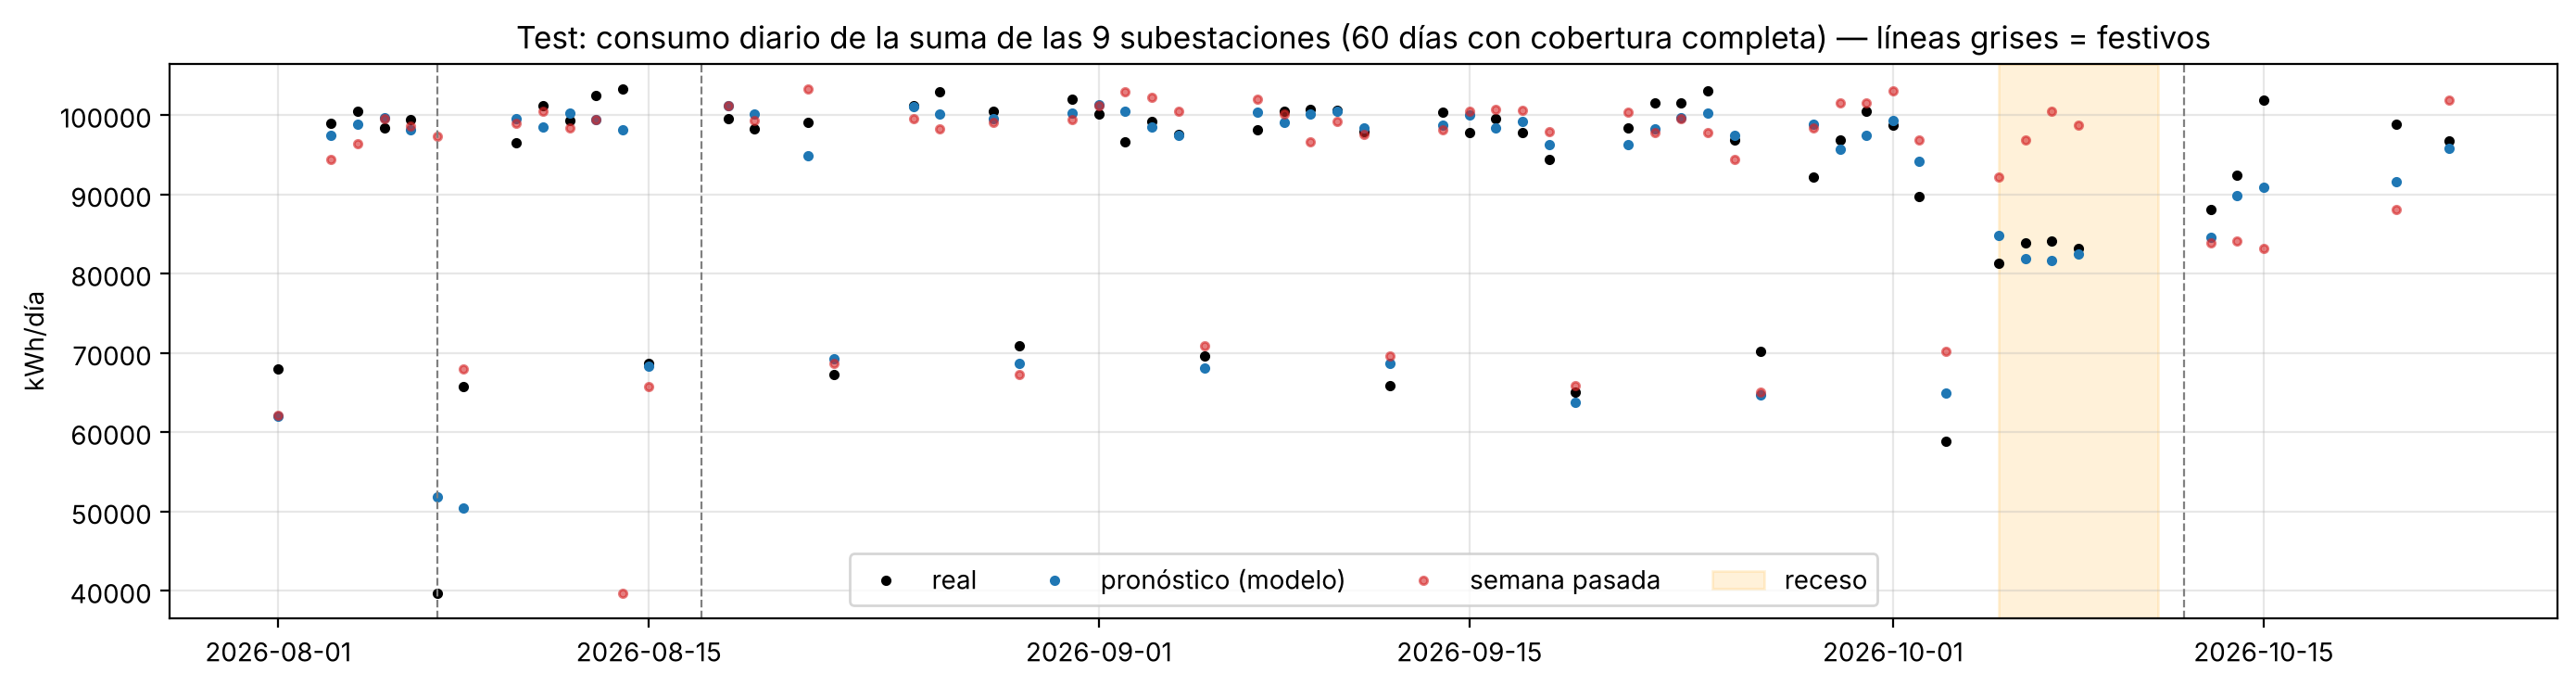

In [39]:
# =============================================================================
# 11.3 Error en escalas diaria y semanal, solo con cobertura completa
# =============================================================================
# (a) Por subestación-día: solo días de esa subestación con las 24 horas comparables
n_horas = cmp.groupby(["subestacion", "dia"], observed=True).kwh.transform("size")     # horas comparables de cada subestación-día
sd = cmp[n_horas == 24]                                                                # <- SELECCIÓN: solo subestación-días con las 24 horas
dia_sub = sd.groupby(["subestacion", "dia"], observed=True)[["kwh", "pred", "lag_168"]].sum()    # <- SUMA de las 24 horas pronosticadas

# (b) Suma de las nueve subestaciones por día: SOLO días con 9 x 24 = 216 horas comparables
n_dia = cmp.groupby("dia").size()                                             # cuántas filas comparables tiene cada día
dias_completos = n_dia[n_dia == 216].index                                    # <- SELECCIÓN DE DÍAS COMPARABLES: exactamente 9 subestaciones x 24 h
# <- SUMA DE PRONÓSTICOS: dentro de cada día completo se suman las 216 horas de real, de pronóstico y de la regla.
#    Es una suma de pronósticos a 24 h emitidos cada medianoche; NO es un pronóstico del día hecho como un solo número.
tot_dia = cmp[cmp.dia.isin(dias_completos)].groupby("dia")[["kwh", "pred", "lag_168"]].sum()
subs_por_dia = cmp[n_horas == 24].groupby("dia", observed=True).subestacion.nunique().reindex(dias_test, fill_value=0)

# (c) Semanas COMPLETAS (lunes-domingo con 7 días completos de las 9 subestaciones)
tot_dia["semana"] = tot_dia.index.to_period("W-SUN")
sem = tot_dia.groupby("semana").agg(dias_completos=("kwh", "size"), kwh=("kwh", "sum"), pred=("pred", "sum"), lag_168=("lag_168", "sum"))
sem_completas = sem[sem.dias_completos == 7]

# (d) Semanal POR SUBESTACIÓN: semanas lunes-domingo con 168 horas comparables de esa subestación
cmp["semana"] = cmp.dia.dt.to_period("W-SUN")
n_sem = cmp.groupby(["subestacion", "semana"], observed=True).kwh.transform("size")
sem_sub = cmp[n_sem == 168].groupby(["subestacion", "semana"], observed=True)[["kwh", "pred", "lag_168"]].sum()

cobertura_tot = pd.DataFrame({
    "días del test": [len(dias_test)],
    "días con 9 subestaciones × 24 h comparables": [len(dias_completos)],
    "días con 8": [int((subs_por_dia == 8).sum())], "días con 7": [int((subs_por_dia == 7).sum())],
    "días con ≤ 6": [int((subs_por_dia <= 6).sum())],
    "semanas con 7 días completos (suma de las 9)": [len(sem_completas)],
    "semanas-subestación completas (168 h)": [len(sem_sub)]}, index=["cobertura"]).T
display(cobertura_tot)

def fila_escala(df, etiqueta):
    return {"escala": etiqueta, "n": len(df), "WAPE modelo %": round(100 * wape(df.kwh, df.pred), 2),
            "WAPE semana pasada %": round(100 * wape(df.kwh, df.lag_168), 2)}
escalas = pd.DataFrame([
    fila_escala(cmp, "horaria (subestación-hora)"),
    fila_escala(dia_sub, "diaria (subestación-día completo)"),
    fila_escala(tot_dia, "diaria (suma de las 9 subestaciones, días completos)"),
    fila_escala(sem_sub, "semanal (subestación-semana completa)"),
] + ([fila_escala(sem_completas, "semanal (suma de las 9, semanas completas)")] if len(sem_completas) else []))
display(escalas.set_index("escala"))
if len(sem_completas) == 0:
    print("⚠️ No hay ninguna semana con 7 días completos de las 9 subestaciones: NO se reporta error semanal de la suma de las 9.")
    parcial = sem.assign(cobertura=lambda d: d.dias_completos.astype(str) + "/7 días")
    parcial["WAPE modelo %"] = [100 * wape(r.kwh, r.pred) for r in parcial.itertuples()]
    parcial["WAPE semana pasada %"] = [100 * wape(r.kwh, r.lag_168) for r in parcial.itertuples()]
    print("Resultado PARCIAL (suma de los días completos disponibles por semana; no es una semana):")
    display(parcial[["cobertura", "WAPE modelo %", "WAPE semana pasada %"]].round(2))

fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(tot_dia.index, tot_dia.kwh, "ko", ms=3, label="real")
ax.plot(tot_dia.index, tot_dia.pred, ".", color="tab:blue", label="pronóstico (modelo)")
ax.plot(tot_dia.index, tot_dia.lag_168, ".", color="tab:red", alpha=0.6, label="semana pasada")
for f in ["2026-08-07", "2026-08-17", "2026-10-12"]:
    ax.axvline(pd.Timestamp(f), color="gray", ls="--", lw=0.8)
ax.axvspan(pd.Timestamp("2026-10-05"), pd.Timestamp("2026-10-11"), color="orange", alpha=0.15, label="receso")
ax.set_title(f"Test: consumo diario de la suma de las 9 subestaciones ({len(dias_completos)} días con cobertura completa) — líneas grises = festivos")
ax.set_ylabel("kWh/día"); ax.legend(ncol=4); plt.tight_layout(); plt.show()

**Cómo leer esto:**
- De los 83 días del test, **60** tienen las 9 subestaciones × 24 horas comparables (19 días tienen 8 subestaciones, 2 tienen 7 y 2 tienen 6 o menos). La suma de las nueve subestaciones por día se evalúa **solo en esos 60 días**: el WAPE es **≈ 3,1 % del modelo frente a ≈ 6,8 % de la regla**. No es comparable con la cifra de la versión anterior (3,4 % vs 10,3 %), que incluía días con 6 a 8 subestaciones.
- Por **subestación-día completo** (718 casos) el error es ≈ 5,5 % vs ≈ 13,0 %.
- **No hay ninguna semana (lunes a domingo) con 7 días completos de las 9 subestaciones**, así que **no se reporta un error semanal de la suma de las nueve**; la cifra de 1,7 % de la versión anterior no se sostiene. Lo que sí se puede decir: por **subestación-semana completa** (83 casos con 168 horas) el error es ≈ 2,0 % vs ≈ 7,8 %. La tabla parcial muestra, para cada semana, cuántos días completos tuvo; no es un error semanal, y las semanas con pocos días (primera y última del test) pesan poco.

## 11.4 Anti-ejemplo: ¿qué pasa si validamos mal (partición aleatoria)?

La Sesión 3 insiste en esto: si mezclamos las horas al azar, el modelo entrena con horas **del mismo día y de días posteriores** a las que evalúa (por ejemplo, ve las 14:00 y las 16:00 para "predecir" las 15:00) y el error **parece** más bajo de lo que será en la realidad.

Para que la comparación sea justa evaluamos **exactamente las mismas horas** (un 20 % al azar de julio-2026) de dos formas: (a) honesta, entrenando solo con lo anterior al 1-jul; (b) tramposa, entrenando con todo el resto de horas, incluidas otras horas de julio.

In [40]:
# =============================================================================
# 11.4 Partición aleatoria (MAL HECHO, solo para mostrar el riesgo)
# =============================================================================
julio = desarrollo[(desarrollo.timestamp >= "2026-07-01")]
evaluar = julio.sample(frac=0.2, random_state=SEMILLA)                       # mismas horas para ambos casos
honesto = ModeloEnergia("lgbm", params=MEJORES_LGBM).fit(desarrollo[desarrollo.timestamp < "2026-07-01"])
tramposo = ModeloEnergia("lgbm", params=MEJORES_LGBM).fit(desarrollo.drop(evaluar.index))
w_h = 100 * wape(evaluar.kwh.values, honesto.predict(evaluar))
w_t = 100 * wape(evaluar.kwh.values, tramposo.predict(evaluar))
print(f"WAPE honesto (entrena solo con el pasado):              {w_h:.2f} %")
print(f"WAPE con partición ALEATORIA (ve horas vecinas del mes): {w_t:.2f} %  ← optimista, no se repetiría en operación")
print(f"La partición aleatoria 'mejora' el error en {w_h - w_t:.2f} puntos sin que el modelo sea mejor.")

WAPE honesto (entrena solo con el pasado):              10.45 %
WAPE con partición ALEATORIA (ve horas vecinas del mes): 7.86 %  ← optimista, no se repetiría en operación
La partición aleatoria 'mejora' el error en 2.59 puntos sin que el modelo sea mejor.


---
# 12. Métrica de negocio: ¿cuánto vale el modelo?

## 12.1 Tarifas (⚠️ estimadas para el periodo de test)

Tarifas del mercado no regulado informadas por la universidad (COP/kWh), **disponibles hasta junio de 2026**. Supuestos: para abr-2025 se usa la de mayo-2025 y, desde **julio de 2026** (todo el test, ago-oct), se usa el **promedio de ene-jun 2026 = COP 524,02/kWh**. Por eso **todo valor en pesos del test es una estimación**: si la tarifa real de agosto-octubre fue distinta, los pesos cambian en proporción (los kWh no).

In [41]:
# =============================================================================
# 12.1 Tarifa por mes (ESTIMADA desde jul-2026)
# =============================================================================
TARIFA = {"2025-05": 531.00, "2025-06": 531.00, "2025-07": 531.00, "2025-08": 531.00, "2025-09": 531.00,
          "2025-10": 531.00, "2025-11": 519.00, "2025-12": 519.00, "2026-01": 519.00, "2026-02": 519.00,
          "2026-03": 519.00, "2026-04": 545.50, "2026-05": 498.13, "2026-06": 543.50}
PROMEDIO_2026 = np.mean([v for k, v in TARIFA.items() if k.startswith("2026")])
TARIFA["2025-04"] = TARIFA["2025-05"]
for m in ["2026-07", "2026-08", "2026-09", "2026-10", "2026-11", "2026-12"]:
    TARIFA[m] = round(PROMEDIO_2026, 2)                  # ESTIMACIÓN: promedio ene-jun 2026
tarifa = lambda ts: ts.dt.strftime("%Y-%m").map(TARIFA)
print(f"Tarifa ESTIMADA para el test (jul-dic 2026): COP {PROMEDIO_2026:,.2f}/kWh (promedio de ene-jun 2026; tarifas conocidas hasta jun-2026)")
pred_test["tarifa"] = tarifa(pred_test.timestamp)

Tarifa ESTIMADA para el test (jul-dic 2026): COP 524.02/kWh (promedio de ene-jun 2026; tarifas conocidas hasta jun-2026)


## 12.2 Valor para la planeación: reducción estimada del error de planeación

**Situación sin modelo:** hoy no existe un pronóstico. Lo mínimo que se podría hacer sin Machine Learning es la regla "mañana será igual que el mismo día de la semana pasada". Comparamos el error **en pesos estimados** de ambas opciones en el test, sobre **las mismas filas comparables** (así la comparación es justa):

- **Error horario en COP:** Σ \|real − pronóstico\| × tarifa. Mide qué tan bien se anticipa *cuándo* se consume.
- **Error del presupuesto diario de la suma de las 9 subestaciones:** \|Σ real − Σ pronóstico\| por día × tarifa, **solo en los días con cobertura completa** (9 × 24 horas comparables).

⚠️ **Cómo leer estos pesos:** no son un ahorro en la factura (la energía consumida es la misma con o sin modelo). Son la **reducción estimada del error de planeación**: cuánto dinero dejaría de estar mal estimado al reservar presupuesto o programar cargas.

In [42]:
# =============================================================================
# 12.2 Traducción del error a pesos (ESTIMADOS) — mismas filas comparables para ambos métodos
# =============================================================================
cmp["tarifa"] = tarifa(cmp.timestamp)
metodos = {"Sin modelo (semana pasada)": "Seasonal naive (semana pasada)", f"Con modelo ({MODELO_ELEGIDO})": MODELO_ELEGIDO}
err_hora = {k: (np.abs(cmp.kwh - cmp[c]) * cmp.tarifa).sum() for k, c in metodos.items()}
# Presupuesto diario: solo días con 216 horas comparables (los mismos de 11.3)
cd = cmp[cmp.dia.isin(dias_completos)].groupby("dia").apply(
    lambda d: pd.Series({"real": (d.kwh * d.tarifa).sum(), "modelo": (d.pred * d.tarifa).sum(), "sin_modelo": (d.lag_168 * d.tarifa).sum()}))
negocio = pd.DataFrame({
    "Sin modelo (semana pasada)": [err_hora["Sin modelo (semana pasada)"], (cd.real - cd.sin_modelo).abs().mean(),
                                   100 * (cd.real - cd.sin_modelo).abs().sum() / cd.real.sum()],
    f"Con modelo ({MODELO_ELEGIDO})": [err_hora[f"Con modelo ({MODELO_ELEGIDO})"], (cd.real - cd.modelo).abs().mean(),
                                       100 * (cd.real - cd.modelo).abs().sum() / cd.real.sum()],
}, index=["Error horario acumulado en las horas comparables (COP estimados)",
          f"Error medio del presupuesto diario de la suma de las 9 ({len(cd)} días completos, COP/día)",
          "Error del presupuesto diario (% del costo real de esos días)"])
negocio["Reducción"] = negocio.iloc[:, 0] - negocio.iloc[:, 1]
pd.options.display.float_format = "{:,.1f}".format
display(negocio)
costo_real = (cmp.kwh * cmp.tarifa).sum()
n_dias_cmp = cmp.dia.nunique()
print(f"Costo estimado de la energía real en las horas comparables ({len(cmp):,} h, {n_dias_cmp} días): COP {costo_real:,.0f}")
print(f"Reducción estimada del error horario de planeación: COP {negocio.iloc[0, 2]:,.0f} en {n_dias_cmp} días "
      f"(≈ COP {negocio.iloc[0, 2] / n_dias_cmp * 30:,.0f} por mes)")
pd.options.display.float_format = None

,Sin modelo (semana pasada),Con modelo (LightGBM ajustado),Reducción
Error horario acumulado en las horas comparables (COP estimados),"615,744,363.0","334,215,256.8","281,529,106.2"
"Error medio del presupuesto diario de la suma de las 9 (60 días completos, COP/día)","3,258,089.0","1,478,532.3","1,779,556.7"
Error del presupuesto diario (% del costo real de esos días),6.8,3.1,3.7


Costo estimado de la energía real en las horas comparables (17,829 h, 83 días): COP 3,587,827,790
Reducción estimada del error horario de planeación: COP 281,529,106 en 83 días (≈ COP 101,757,508 por mes)


**Resultado (todo en COP estimados, tarifa de 12.1):**
- El error horario acumulado en pesos baja ≈ 45 % frente a no tener modelo (ver la tabla de arriba): una **reducción estimada del error de planeación** equivalente a ≈ 7,7 % del costo estimado de la energía en los 83 días. (En esta versión pública las cifras en COP están escaladas; los porcentajes son los reales.)
- El error del **presupuesto diario de la suma de las nueve subestaciones** (60 días completos) baja de ≈ 6,8 % del costo diario a ≈ 3,1 %.

La diferencia entre columnas es la **reducción estimada del error de planeación**, no un ahorro en la factura.

## 12.3 Umbral de decisión: sistema de alertas (elegido en VALIDACIÓN y congelado antes del test)

🧠 **Idea dummie:** cada mañana el jefe de mantenimiento recibe el pronóstico con una **banda de tolerancia**. Si el consumo real de una subestación supera la banda en varias horas del día, se genera una **alerta** para revisar.

**Regla de alerta:** una subestación-día genera alerta si **al menos *h* horas** superan `pronóstico + q × nivel_7d`, donde `q` es un cuantil (q90, q95, q99) de los **residuos de validación** de esa subestación (como en *conformal prediction*).

**Cómo se elige la combinación (corrección de la versión anterior, que la elegía mirando el test):**

1. Se calculan los umbrales **solo con los residuos de validación** (abril-julio).
2. Se prueban las 9 combinaciones (*q* × *h*) **en validación**.
3. **Criterio explícito:** de las combinaciones que generan **como máximo 7 alertas por semana** para las 9 subestaciones (≈ 1 revisión por día, volumen que se asume que un equipo puede atender; ⚠️ *supuesto a confirmar con mantenimiento*), se elige la que **detecta más días atípicos**; a igualdad, la de menos alertas.
4. La combinación elegida se **congela** y solo entonces se mira el test.
5. Como las alertas no operaron en vivo, el resultado en el test es una **reevaluación retrospectiva**, no una medición de uso real.

🧠 **"Detectar" tiene dos caras** que se reportan por separado: (a) **sensibilidad** = de los días atípicos, ¿cuántos tuvieron alerta?; (b) **precisión** = de las alertas emitidas, ¿cuántas cayeron en un día atípico? Una regla puede detectar muchos atípicos y aun así emitir muchas alertas que no coinciden con ninguno.

In [43]:
# =============================================================================
# 12.3a Elegir umbral y duración EN VALIDACIÓN (el test no participa)
# =============================================================================
CAPACIDAD_REVISION = 7          # alertas por semana que el equipo puede revisar (SUPUESTO a confirmar con mantenimiento)

res_oof = desarrollo.merge(OOF[MODELO_ELEGIDO], on=["timestamp", "subestacion"])              # solo filas de los 4 pliegues de validación
res_oof["res_rel"] = (res_oof.kwh - res_oof.pred) / res_oof.nivel_7d                          # residuo relativo al nivel
res_oof["atipico"] = es_atipico(res_oof)
res_oof["dia"] = res_oof.timestamp.dt.normalize()
UMBRALES = {q: res_oof.groupby("subestacion", observed=True).res_rel.quantile(q) for q in [0.90, 0.95, 0.99]}   # SOLO validación

def evaluar_alertas(df, q, h_min):
    # df: filas con kwh, pred, nivel_7d, subestacion, dia, atipico. Devuelve resumen y tabla subestación-día.
    techo = df.pred + df.subestacion.map(UMBRALES[q]).astype(float) * df.nivel_7d
    d = df.assign(sobre=df.kwh > techo)
    sd = d.groupby(["subestacion", "dia"], observed=True).agg(horas_sobre=("sobre", "sum"), atipico=("atipico", "first"))
    sd["alerta"] = sd.horas_sobre >= h_min
    semanas = d.dia.nunique() / 7
    n_alertas, n_atip = int(sd.alerta.sum()), int(sd.atipico.sum())
    resumen = {"alertas": n_alertas, "alertas por semana": n_alertas / semanas,
               "días atípicos": n_atip, "atípicos con alerta": int((sd.alerta & sd.atipico).sum()),
               "% atípicos detectados (sensibilidad)": 100 * (sd.alerta & sd.atipico).sum() / max(n_atip, 1),
               "% alertas que caen en día atípico (precisión)": 100 * (sd.alerta & sd.atipico).sum() / max(n_alertas, 1),
               "% días normales con alerta": 100 * (sd.alerta & ~sd.atipico).sum() / max((~sd.atipico).sum(), 1)}
    return resumen, sd

filas = []
for q in UMBRALES:
    for h_min in (2, 3, 4):
        r, _ = evaluar_alertas(res_oof, q, h_min)
        filas.append({"banda q": f"q{int(q*100)}", "horas mínimas": h_min, **r})
tabla_val_alertas = pd.DataFrame(filas).set_index(["banda q", "horas mínimas"]).round(1)
display(tabla_val_alertas)

# Criterio: ≤ CAPACIDAD_REVISION alertas/semana; entre ellas, máxima sensibilidad; desempate: menos alertas
factibles = tabla_val_alertas[tabla_val_alertas["alertas por semana"] <= CAPACIDAD_REVISION]
if len(factibles):
    elegida = factibles.sort_values(["% atípicos detectados (sensibilidad)", "alertas por semana"], ascending=[False, True]).index[0]
else:
    elegida = tabla_val_alertas["alertas por semana"].idxmin()
# Sensibilidad del criterio: ¿qué combinación se elegiría con otra capacidad de revisión? (el criterio es de "umbral duro")
sens = []
for cap in (3, 5, 7, 8, 10, 14, 20):
    fz = tabla_val_alertas[tabla_val_alertas["alertas por semana"] <= cap]
    ch = fz.sort_values(["% atípicos detectados (sensibilidad)", "alertas por semana"], ascending=[False, True]).index[0] if len(fz) else None
    sens.append({"capacidad (alertas/semana)": cap, "combinación elegida": f"{ch[0]} con ≥ {ch[1]} h" if ch else "ninguna"})
display(pd.DataFrame(sens).set_index("capacidad (alertas/semana)").T)
ALERTA_Q = {"q90": 0.90, "q95": 0.95, "q99": 0.99}[elegida[0]]       # <- CONGELADO: no se vuelve a tocar con el test
ALERTA_H = int(elegida[1])
print(f"\n✅ Combinación elegida EN VALIDACIÓN y congelada: banda {elegida[0]} con al menos {ALERTA_H} horas "
      f"({tabla_val_alertas.loc[elegida, 'alertas por semana']:.1f} alertas/semana en validación)")

alertas  alertas por semana  días atípicos  atípicos con alerta  % atípicos detectados (sensibilidad)  % alertas que caen en día atípico (precisión)  \
banda q horas mínimas                                                                                                                                                         
q90     2                  429                24.6             61                   57                                  93.4                                           13.3   
        3                  347                19.9             61                   55                                  90.2                                           15.9   
        4                  270                15.5             61                   54                                  88.5                                           20.0   
q95     2                  220                12.6             61                   51                                  83.6                                           23.2   
        3                  169                 9.7             61                   45                                  73.8                                           26.6   
        4                  126                 7.2             61                   33                                  54.1                                           26.2   
q99     2                   48                 2.8             61                   20                                  32.8                                           41.7   
        3                   30                 1.7             61                    9                                  14.8                                           30.0   
        4                   25                 1.4             61                    9                                  14.8                                           36.0   

                       % días normales con alerta  
banda q horas mínimas                              
q90     2                                    36.5  
        3                                    28.7  
        4                                    21.2  
q95     2                                    16.6  
        3                                    12.2  
        4                                     9.1  
q99     2                                     2.8  
        3                                     2.1  
        4                                     1.6

capacidad (alertas/semana),3,5,7,8,10,14,20
combinación elegida,q99 con ≥ 2 h,q99 con ≥ 2 h,q99 con ≥ 2 h,q95 con ≥ 4 h,q95 con ≥ 3 h,q95 con ≥ 2 h,q90 con ≥ 3 h



✅ Combinación elegida EN VALIDACIÓN y congelada: banda q99 con al menos 2 horas (2.8 alertas/semana en validación)


In [44]:
# =============================================================================
# 12.3b REEVALUACIÓN RETROSPECTIVA en el test con la combinación congelada (no se elige nada aquí)
# =============================================================================
pt_al = pred_test[pred_test.tiene_medicion & pred_test.pred.notna()].copy()           # horas con real y pronóstico
r_test, sd_test = evaluar_alertas(pt_al, ALERTA_Q, ALERTA_H)
n_sd = len(sd_test)
completo = pt_al.groupby(["subestacion", "dia"], observed=True).size().reindex(sd_test.index) == 24
resumen_alertas_test = pd.Series({
    "Subestación-días evaluados": n_sd,
    "  de ellos con las 24 h medidas": int(completo.sum()),
    "Alertas emitidas": r_test["alertas"],
    "Alertas por semana (9 subestaciones)": round(r_test["alertas por semana"], 1),
    "Subestación-días atípicos (regla 1,5×)": r_test["días atípicos"],
    "  atípicos con alerta (detectados)": r_test["atípicos con alerta"],
    "  % atípicos detectados (sensibilidad)": round(r_test["% atípicos detectados (sensibilidad)"], 1),
    "  % de las alertas que caen en día atípico (precisión)": round(r_test["% alertas que caen en día atípico (precisión)"], 1),
    "  % de días normales con alerta": round(r_test["% días normales con alerta"], 1)}, name="test (retrospectivo)")
display(resumen_alertas_test.to_frame())
print(f"Lectura: de {r_test['días atípicos']} subestación-días atípicos, {r_test['atípicos con alerta']} tuvieron alerta; pero de las "
      f"{r_test['alertas']} alertas emitidas, solo {r_test['atípicos con alerta']} cayeron en un día atípico. "
      "Las demás pueden ser cargas reales no esperadas que la regla 1,5× no marcó, o falsas alarmas: sin registro no se puede saber.")

,test (retrospectivo)
Subestación-días evaluados,747.0
de ellos con las 24 h medidas,726.0
Alertas emitidas,15.0
Alertas por semana (9 subestaciones),1.3
"Subestación-días atípicos (regla 1,5×)",32.0
atípicos con alerta (detectados),6.0
% atípicos detectados (sensibilidad),18.8
% de las alertas que caen en día atípico (precisión),40.0
% de días normales con alerta,1.3


Lectura: de 32 subestación-días atípicos, 6 tuvieron alerta; pero de las 15 alertas emitidas, solo 6 cayeron en un día atípico. Las demás pueden ser cargas reales no esperadas que la regla 1,5× no marcó, o falsas alarmas: sin registro no se puede saber.


**Qué pasó con la elección:** el criterio (≤ 7 alertas por semana) dejó fuera a q95 con ≥ 4 h (7,2 alertas/semana en validación, apenas por encima del límite) y a las bandas q90, y eligió **q99 con al menos 2 horas** (2,8 alertas/semana en validación). Es un criterio de **umbral duro**: la tabla de sensibilidad muestra que con una capacidad de 8 o 9 alertas/semana se habría elegido q95 con ≥ 4 h, y con 10 a 12, q95 con ≥ 3 h (con 13 o más, q95 con ≥ 2 h). Es decir, la capacidad de revisión del equipo es una **decisión de negocio** que mueve la elección; el modelo solo informa el costo de cada opción.

**Resultado en el test (reevaluación retrospectiva, nada se eligió aquí):** 15 alertas (≈ 1,3 por semana). **6 de las 15** cayeron en un subestación-día atípico (**precisión 40 %**) y se detectaron **6 de los 32** atípicos (**sensibilidad ≈ 19 %**); solo ≈ 1,3 % de los días normales tuvo alerta. Es una regla **conservadora**: pocas alertas, razonablemente confiables, pero deja pasar la mayoría de los días atípicos. Si mantenimiento puede revisar más casos, hay que subir la capacidad y se elegiría una banda más baja. Los "días atípicos" son los de la regla 1,5× (sin agenda de eventos **no hay "evento confirmado"**), y 32 casos son una muestra pequeña. El umbral se recalibra cada mes con los residuos nuevos.

⚠️ Una alerta en un día "no atípico" no es necesariamente falsa: puede ser una carga real no esperada que la regla 1,5× no alcanzó a marcar. Por eso la alerta es una **invitación a revisar**, no un diagnóstico.

## 12.4 ¿Cuánto vale la diferencia entre lo observado y lo pronosticado en un día atípico?

Con las predicciones honestas (validación + test, abril a octubre de 2026), en cada subestación-día atípico medimos la **diferencia entre consumo observado y pronosticado** = Σ(real − pronóstico) del día, valorada en COP estimados.

🔶 **Qué NO es:** no es el "costo de un evento". Sin agenda de eventos no sabemos qué causó el día atípico (un evento, una maniobra de carga, un día nublado en SUB5…), y el pronóstico mismo tiene error. Y se reportan **todos** los casos: los que quedaron **por encima y por debajo** del pronóstico (la versión anterior solo conservaba los positivos, lo que infla el valor típico).

In [45]:
# =============================================================================
# 12.4 Diferencia observado − pronosticado en días atípicos (todos los casos, con signo)
# =============================================================================
honestas = pd.concat([
    res_oof[["timestamp", "subestacion", "kwh", "pred"]],                                                  # validación (fuera de muestra)
    pred_test[pred_test.tiene_medicion & pred_test.pred.notna()][["timestamp", "subestacion", "kwh", "pred"]]])   # test
honestas["dia"] = honestas.timestamp.dt.normalize()
honestas["tarifa"] = tarifa(honestas.timestamp)
honestas["atipico"] = es_atipico(honestas)
eventos = honestas[honestas.atipico].groupby(["subestacion", "dia"], observed=True).apply(
    lambda d: pd.Series({"horas_con_dato": len(d), "kwh_diferencia": (d.kwh - d.pred).sum(),
                         "cop_diferencia": ((d.kwh - d.pred) * d.tarifa).sum(), "kwh_real": d.kwh.sum()})).reset_index()
eventos["dia_completo"] = eventos.horas_con_dato == 24
eventos["sentido"] = np.where(eventos.kwh_diferencia > 0, "por encima del pronóstico", "por debajo del pronóstico")

print(f"Subestación-días atípicos: {len(eventos)} | con las 24 horas medidas: {int(eventos.dia_completo.sum())} | "
      f"por encima del pronóstico: {int((eventos.kwh_diferencia > 0).sum())} | por debajo: {int((eventos.kwh_diferencia <= 0).sum())}")
resumen_eventos = eventos.groupby("subestacion", observed=True).agg(
    casos=("dia", "size"), dia_completo=("dia_completo", "sum"),
    por_encima=("kwh_diferencia", lambda s: int((s > 0).sum())), por_debajo=("kwh_diferencia", lambda s: int((s <= 0).sum())),
    kwh_dif_mediana=("kwh_diferencia", "median"), cop_dif_mediana=("cop_diferencia", "median"),
    cop_dif_neta=("cop_diferencia", "sum")).round(0)
display(resumen_eventos)
pos = eventos[eventos.kwh_diferencia > 0]
print(f"Solo como referencia (NO es el caso típico): mediana de las diferencias POSITIVAS = {pos.kwh_diferencia.median():,.0f} kWh "
      f"≈ COP {pos.cop_diferencia.median():,.0f} estimados (n = {len(pos)}). Mediana de TODAS las diferencias (con signo) = "
      f"{eventos.kwh_diferencia.median():,.0f} kWh ≈ COP {eventos.cop_diferencia.median():,.0f}.")
print("\nLos 5 casos con mayor diferencia positiva (abr-oct 2026):")
display(eventos.nlargest(5, "cop_diferencia").assign(dia_semana=lambda d: d.dia.dt.day_name()).round(0))

Subestación-días atípicos: 93 | con las 24 horas medidas: 90 | por encima del pronóstico: 84 | por debajo: 9


,casos,dia_completo,por_encima,por_debajo,kwh_dif_mediana,cop_dif_mediana,cop_dif_neta
subestacion,,,,,,,
SUB1,16,16,15,1,1319.0,691065.0,13605870.0
SUB2,9,9,8,1,170.0,89140.0,1623059.0
SUB3,3,1,2,1,6320.0,3447552.0,6685843.0
SUB5,40,39,37,3,301.0,160745.0,7290140.0
SUB6,8,8,8,0,770.0,393729.0,3359853.0
SUB9,17,17,14,3,3003.0,1633288.0,33472056.0


Solo como referencia (NO es el caso típico): mediana de las diferencias POSITIVAS = 612 kWh ≈ COP 324,349 estimados (n = 84). Mediana de TODAS las diferencias (con signo) = 473 kWh ≈ COP 248,858.

Los 5 casos con mayor diferencia positiva (abr-oct 2026):


,subestacion,dia,horas_con_dato,kwh_diferencia,cop_diferencia,kwh_real,dia_completo,sentido,dia_semana
26,SUB3,2026-04-15,23.0,13077.0,7133595.0,33224.0,False,por encima del pronóstico,Wednesday
85,SUB9,2026-08-08,24.0,10831.0,5675503.0,16478.0,True,por encima del pronóstico,Saturday
84,SUB9,2026-07-26,24.0,8664.0,4540327.0,9818.0,True,por encima del pronóstico,Sunday
81,SUB9,2026-06-28,24.0,7911.0,4299782.0,10046.0,True,por encima del pronóstico,Sunday
89,SUB9,2026-09-13,24.0,7866.0,4121748.0,10144.0,True,por encima del pronóstico,Sunday


**Lectura:** de los **93 subestación-días atípicos** (abril-octubre), 90 tienen el día completo; en **84** el consumo quedó **por encima** del pronóstico y en **9 por debajo** (con la regla 1,5× es esperable que casi todos queden por encima, porque la regla busca excesos; por eso la mediana de **todos** los casos es la medida honesta, y es ≈ 23 % menor que la mediana de solo los positivos). Por subestación, la mediana con signo es mucho mayor en **SUB9** (unas 6 veces la mediana general), seguida de SUB1 y SUB6, y pequeña en SUB2 y SUB5 (en SUB5 los atípicos son sobre todo días nublados). SUB3 tiene solo 3 casos (abril, una subida sostenida) y solo 1 con el día completo: no se saca una mediana útil de ahí.

⚠️ **Sobre el precio de alquiler de espacios:** estimar un precio de energía por evento exigiría (1) **eventos identificados** (fecha, bloque, asistentes) y (2) una **estimación de su consumo adicional**, es decir, comparar contra lo que se habría consumido sin el evento. Con los datos actuales solo tenemos días atípicos sin causa conocida y un pronóstico con error propio, así que estas cifras son un **orden de magnitud de la diferencia observada − pronosticada**, no un precio.

🔶 **Hipótesis (sin confirmar):** la subida de **SUB3 del 14 al 16-abr-2026** mientras **SUB9** no reportaba coincide con una **transferencia de carga SUB9 → SUB3**; no hay registro de la maniobra.

## 12.5 Limitaciones y riesgos

| Riesgo | Impacto | Mitigación |
|---|---|---|
| Eventos no agendados | Errores grandes en días atípicos | Reportar aparte; pedir la agenda; alertas |
| Cambios de equipos (como SUB3) | El modelo aprende un nivel que ya no existe | Normalización por `nivel_7d` (se adapta en ~1 semana); registrar cambios |
| Fallas de comunicación del medidor | Datos falsos entran como historia | Reglas R1-R4 automáticas y **causales** antes de pronosticar; se conserva el valor original en `registro_limpieza` |
| Sol / nubes en bloques con paneles | Error mayor al mediodía en SUB5, SUB4, SUB6 | Conseguir datos de inversores o pronóstico de radiación |
| Tarifas futuras desconocidas (el test usa COP 524,02/kWh **estimados**) | Todo valor en COP es una estimación | Actualizar la tabla de tarifas mensualmente |
| Deriva (*drift*) del comportamiento | Pérdida gradual de precisión | Reentrenar semanalmente (como en el test) y monitorear el WAPE |
| Las 9 series cubren ≈ 91-97 % del medidor general (causa del resto sin confirmar) | La suma de las nueve subestaciones no es la demanda total de la universidad | Usar el medidor general para el total; confirmar con el área técnica qué falta (hipótesis: otras subestaciones del inventario) |

---
# 13. Caso aplicado: el modelo en uso

## 13.1 Pronóstico real para mañana: viernes 23 de octubre de 2026

El último dato disponible es el jueves 22-oct-2026 a las 23:00. Simulamos lo que pasaría a la medianoche: el modelo se entrena con **toda** la historia y genera las 24 horas del viernes para cada subestación, con su banda de alerta y su costo estimado (tarifa **estimada**).

La función `pronosticar_dia` es la que se usaría en producción todos los días. Parte de los **datos crudos** (los limpia y construye las variables con el corte de las 23:00) y verifica que el resultado tenga **216 combinaciones únicas** (9 subestaciones × 24 horas).

Filas del pronóstico: 216 | combinaciones (subestación, hora) únicas: 216 (= 9 × 24)
Pronóstico emitido a las 00:00 del Friday 23-Oct-2026 (periodo: clases, semana 15 del semestre)


,kwh_dia,pico_kwh,hora_pico,costo_cop
subestacion,,,,
SUB1,7342.0,475.0,12.0,3847292.0
SUB2,5025.0,297.0,18.0,2633123.0
SUB3,13637.0,796.0,12.0,7145934.0
SUB4,13678.0,788.0,15.0,7167636.0
SUB5,3203.0,255.0,18.0,1678422.0
SUB6,8808.0,507.0,20.0,4615536.0
SUB7,8716.0,544.0,10.0,4567469.0
SUB8,13769.0,793.0,10.0,7215058.0
SUB9,19593.0,1664.0,7.0,10267065.0


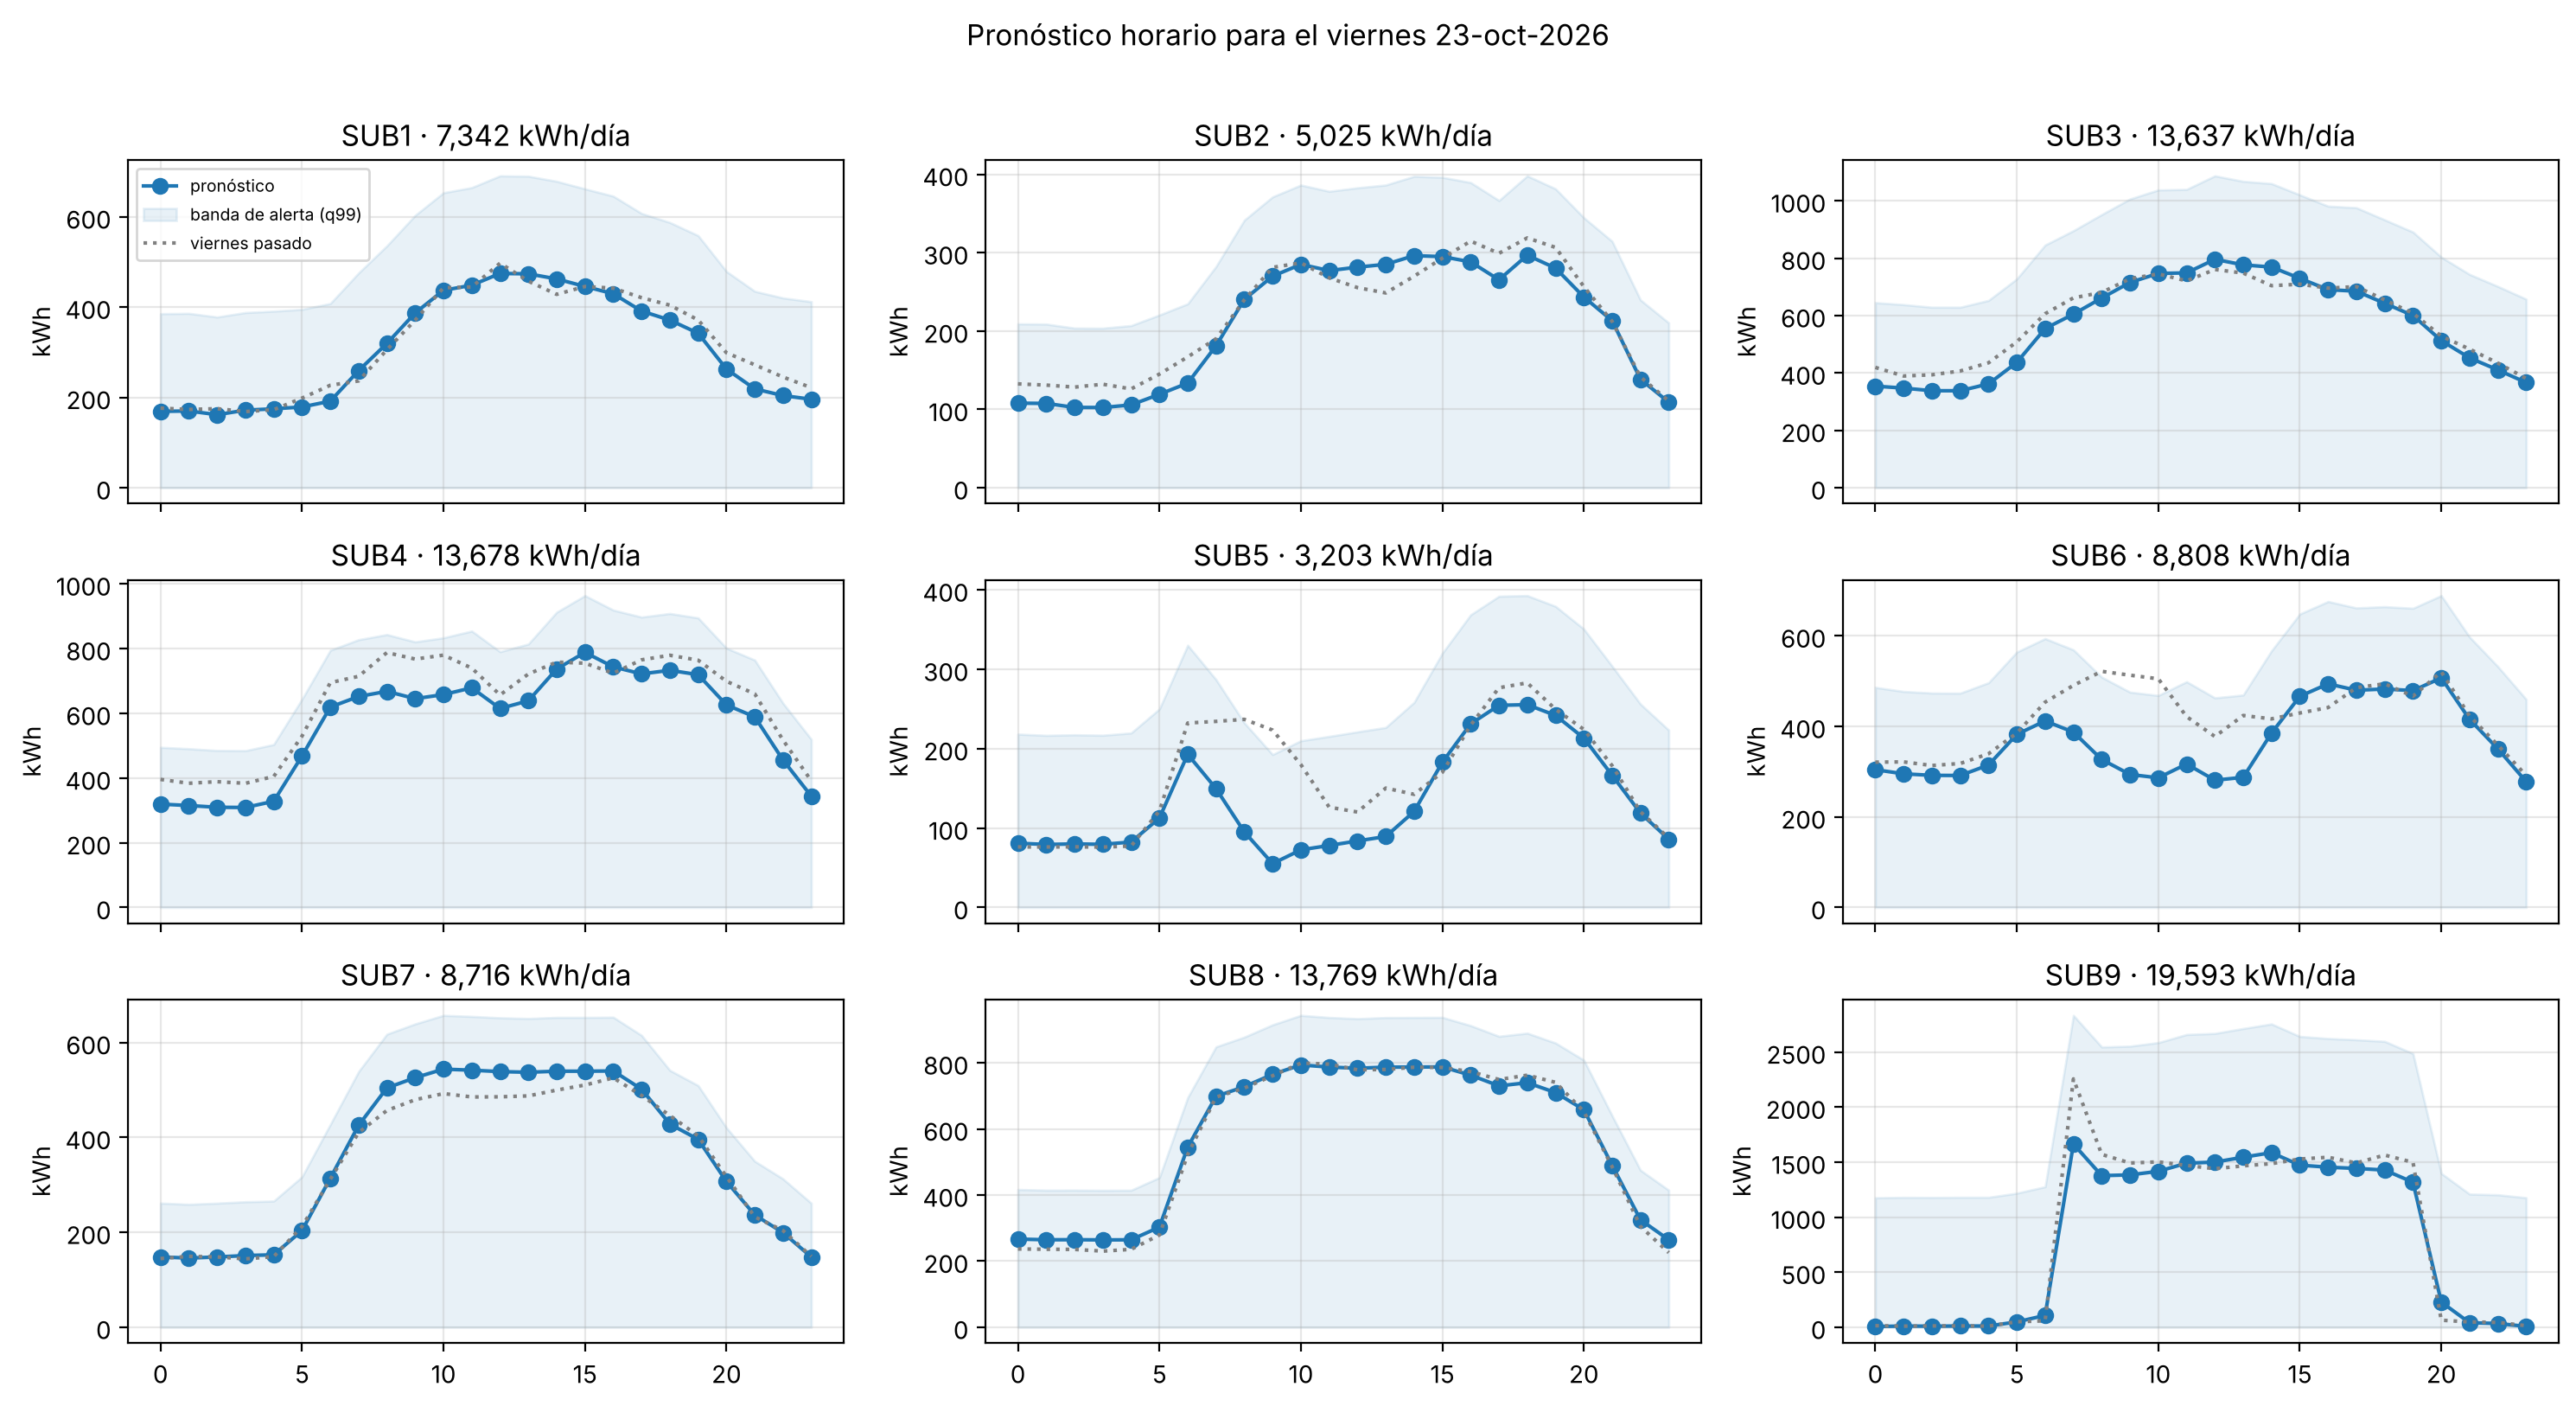

In [46]:
# =============================================================================
# 13.1 Función de producción y pronóstico del 23-oct-2026
# =============================================================================
def pronosticar_dia(fecha, crudo, modelo, umbral=UMBRALES[ALERTA_Q]):   # banda elegida en validación (Sección 12.3)
    # 1) Corta los DATOS CRUDOS a la medianoche: nada del día 'fecha' en adelante se usa
    fecha = pd.Timestamp(fecha)
    ultima_hora = fecha - pd.Timedelta(hours=1)               # <- CORTE DE LA EMISIÓN (23:00 del día anterior)
    # 2) Limpia (causal) y construye las 24 filas de cada subestación con las mismas pistas del entrenamiento
    T = tabla_desde_crudo(crudo.loc[:ultima_hora], hasta=fecha + pd.Timedelta(hours=23))
    filas = T[T.timestamp.dt.normalize() == fecha].copy()
    assert filas[["subestacion", "timestamp"]].drop_duplicates().shape[0] == 216, "se esperaban 9 subestaciones × 24 horas"
    # 3) Predice y agrega banda de alerta y costo
    filas["pronostico_kwh"] = modelo.predict(filas)
    filas["banda_alerta_kwh"] = filas.pronostico_kwh + filas.subestacion.map(umbral).astype(float) * filas.nivel_7d
    filas["costo_cop"] = filas.pronostico_kwh * tarifa(filas.timestamp)
    return filas[["timestamp", "subestacion", "pronostico_kwh", "banda_alerta_kwh", "costo_cop", "lag_168", "nivel_7d"]]

modelo_final = FABRICAS[MODELO_ELEGIDO]().fit(datos)          # entrenado con toda la historia disponible
manana = pronosticar_dia("2026-10-23", ancho_crudo, modelo_final)
print(f"Filas del pronóstico: {len(manana)} | combinaciones (subestación, hora) únicas: "
      f"{manana[['subestacion', 'timestamp']].drop_duplicates().shape[0]} (= 9 × 24)")

resumen_manana = manana.groupby("subestacion", observed=True).agg(
    kwh_dia=("pronostico_kwh", "sum"), pico_kwh=("pronostico_kwh", "max"),
    hora_pico=("pronostico_kwh", lambda s: manana.loc[s.idxmax(), "timestamp"].hour),
    costo_cop=("costo_cop", "sum")).round(0)
resumen_manana.loc["SUMA de las 9 subestaciones"] = [resumen_manana.kwh_dia.sum(), np.nan, np.nan, resumen_manana.costo_cop.sum()]
dia_cal = CAL.loc[pd.Timestamp('2026-10-23')]
print(f"Pronóstico emitido a las 00:00 del {pd.Timestamp('2026-10-23'):%A %d-%b-%Y} "
      f"(periodo: {dia_cal.periodo}, semana {dia_cal.semana_semestre} del semestre)")
display(resumen_manana)

fig, axes = plt.subplots(3, 3, figsize=(15, 8), sharex=True)
for ax, (k, g) in zip(axes.flat, manana.groupby("subestacion", observed=True)):
    h = g.timestamp.dt.hour
    ax.plot(h, g.pronostico_kwh, "o-", label="pronóstico")
    ax.fill_between(h, 0, g.banda_alerta_kwh, color="tab:blue", alpha=0.1, label=f"banda de alerta (q{int(ALERTA_Q*100)})")
    ax.plot(h, g.lag_168, ":", color="gray", label="viernes pasado")
    ax.set_title(f"{k} · {resumen_manana.loc[k, 'kwh_dia']:,.0f} kWh/día"); ax.set_ylabel("kWh")
axes[0, 0].legend(fontsize=7); plt.suptitle("Pronóstico horario para el viernes 23-oct-2026", y=1.01)
plt.tight_layout(); plt.show()

## 13.1b Modelo persistido y versionado

Para que el modelo salga del notebook (criterio 6 de Almacenamiento y Procesamiento) se guarda el modelo final en un archivo
`modelos/modelo_energia_v4.joblib` y se registra el experimento en **MLflow** (parámetros, métricas del test, origen de los datos
y el archivo).

Se guardan los **estimadores entrenados** (LightGBM y Random Forest de scikit-learn) junto con sus variables y las categorías de
`subestacion` y `periodo`, no la clase `Ensamble` de este notebook. Así cualquier programa (la API o Databricks) puede cargar el
archivo y pronosticar sin ejecutar este notebook. La celda comprueba que el modelo **recargado del archivo** da exactamente el
mismo pronóstico del 23-oct-2026 que el modelo en memoria.

*Versión:* **v4** del notebook (v2 = auditoría metodológica con calendario tentativo; v3 = calendario oficial 2026 y modelo
persistido; v4 = los datos se leen de Databricks). La ficha del modelo guarda **de qué tabla salió cada dato** (`fuente_datos`),
para saber con qué versión de los datos se entrenó. Dentro de Databricks el archivo queda en el Volume y el experimento en el
MLflow del workspace; en un computador, en `modelos/` y en `mlflow.db` (se consulta con
`mlflow ui --backend-store-uri sqlite:///mlflow.db`). Si MLflow no está disponible, el notebook sigue: el archivo `.joblib` ya
quedó guardado y comprobado.

In [47]:
# =============================================================================
# 13.1b Guardar y versionar el modelo final (para Databricks, la API y el tablero)
# =============================================================================
import joblib
from datetime import datetime

MODELOS = MOD                         # en Databricks: el Volume que lee 04_resultados; en un PC: modelos/
VERSION_MODELO = "v4"                 # versión del notebook: v4 = datos leídos de Databricks (Medallion)

def componentes_de(modelo):
    # Un ensamble guarda varios modelos; un modelo simple, uno solo
    return modelo.modelos if hasattr(modelo, "modelos") else [modelo]

def a_numero(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return v

artefacto = {
    "version": VERSION_MODELO,
    "modelo": MODELO_ELEGIDO,
    "creado": datetime.now().isoformat(timespec="seconds"),
    "entrenado_hasta": str(datos.timestamp.max()),
    "fuente_datos": dict(ORIGEN),     # de qué tabla (o archivo) salió cada dato
    "componentes": [{"tipo": m.tipo, "variables": list(m.variables), "relativo": m.relativo, "estimador": m.modelo}
                    for m in componentes_de(modelo_final)],
    "categorias": {c: list(pd.Categorical(datos[c]).categories) for c in CATEGORICAS},
    "umbral_alerta_relativo": {str(k): float(v) for k, v in dict(UMBRALES[ALERTA_Q]).items()},
    "metricas_test": {k: a_numero(v) for k, v in res_test.loc[MODELO_ELEGIDO].to_dict().items()},
    "params": {"lgbm": MEJORES_LGBM, "rf": MEJORES_RF},
    "versiones": VERSIONES,
}

def predecir_con_artefacto(art, filas):
    # Reproduce ModeloEnergia.predict sin depender de las clases del notebook (así lo usa la API)
    preds = []
    for comp in art["componentes"]:
        X = filas[comp["variables"]].copy()
        if comp["tipo"] == "ridge":
            X["sub_hora_lab"] = (filas.subestacion.astype(str) + "_" + filas.hora.astype(str) + "_"
                                 + filas.laboral.astype(str))
        for c, cats in art["categorias"].items():
            if c in X:
                X[c] = pd.Categorical(X[c], categories=cats)
                if comp["tipo"] == "rf":
                    X[c] = X[c].cat.codes
        p = comp["estimador"].predict(X)
        if comp["relativo"]:
            p = p * filas.nivel_7d.values
        preds.append(np.clip(p, 0, None))
    return np.mean(preds, axis=0)

# 1) Guardar el archivo y una ficha legible (sin los estimadores)
ruta_modelo = MODELOS / f"modelo_energia_{VERSION_MODELO}.joblib"
joblib.dump(artefacto, ruta_modelo, compress=3)
ficha = {k: v for k, v in artefacto.items() if k != "componentes"}
ficha["componentes"] = [{k: v for k, v in c.items() if k != "estimador"} for c in artefacto["componentes"]]
(MODELOS / f"ficha_modelo_{VERSION_MODELO}.json").write_text(json.dumps(ficha, ensure_ascii=False, indent=2, default=str))

# 2) Prueba funcional: el modelo RECARGADO del archivo pronostica igual que el de memoria
fecha_p = pd.Timestamp("2026-10-23")
T_p = tabla_desde_crudo(ancho_crudo.loc[:fecha_p - pd.Timedelta(hours=1)], hasta=fecha_p + pd.Timedelta(hours=23))
filas_p = T_p[T_p.timestamp.dt.normalize() == fecha_p]
recargado = joblib.load(ruta_modelo)
diferencia = np.abs(predecir_con_artefacto(recargado, filas_p) - modelo_final.predict(filas_p)).max()
assert diferencia < 1e-6, f"El modelo recargado no coincide (diferencia máxima {diferencia})"
print(f"Modelo guardado: {ruta_modelo} ({ruta_modelo.stat().st_size / 1e6:.1f} MB) · "
      f"recargado y comprobado: diferencia máxima {diferencia:.1e} kWh en {len(filas_p)} filas")

# 3) Registro del experimento en MLflow (si está instalado)
try:
    import mlflow
    if EN_DATABRICKS:                 # MLflow del workspace: el experimento vive en la carpeta del usuario
        usuario = spark.sql("SELECT current_user()").first()[0]
        mlflow.set_tracking_uri("databricks")
        mlflow.set_experiment(f"/Users/{usuario}/pronostico_energia_eafit")
    else:                             # en un PC: base SQLite local
        mlflow.set_tracking_uri(f"sqlite:///{Path('mlflow.db').resolve()}")
        mlflow.set_experiment("pronostico_energia_eafit")
    with mlflow.start_run(run_name=f"{MODELO_ELEGIDO} {VERSION_MODELO}"):
        mlflow.log_params({f"lgbm_{k}": v for k, v in MEJORES_LGBM.items()})
        mlflow.log_params({f"rf_{k}": v for k, v in MEJORES_RF.items()})
        mlflow.log_params({"modelo": MODELO_ELEGIDO, "version": VERSION_MODELO, "calendario": "2026 oficial, 2025 estimado",
                           "entrenado_hasta": artefacto["entrenado_hasta"], "modo_lectura": MODO_LECTURA,
                           "tabla_consumo": ORIGEN.get("consumo", "")[:250]})
        mlflow.log_metrics({f"test_{k.replace('%', 'pct')}": v for k, v in artefacto["metricas_test"].items()
                            if isinstance(v, float) and np.isfinite(v)})
        mlflow.log_artifact(str(ruta_modelo)); mlflow.log_artifact(str(MODELOS / f"ficha_modelo_{VERSION_MODELO}.json"))
    print("Experimento registrado en MLflow:", f"/Users/{usuario}/pronostico_energia_eafit" if EN_DATABRICKS else
          f"{Path('mlflow.db').resolve()} (ver con: mlflow ui --backend-store-uri sqlite:///mlflow.db)")
except Exception as e:                # MLflow es un registro adicional: si falla, el modelo ya quedó guardado y comprobado
    print(f"MLflow no disponible ({type(e).__name__}): el modelo queda versionado en", MODELOS.resolve())


Modelo guardado: modelos/modelo_energia_v4.joblib (1.8 MB) · recargado y comprobado: diferencia máxima 0.0e+00 kWh en 216 filas


2026/11/21 12:56:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/21 12:56:59 INFO mlflow.store.db.utils: Updating database tables


2026/11/21 12:57:00 INFO mlflow.tracking.fluent: Experiment with name 'pronostico_energia_eafit' does not exist. Creating a new experiment.


Experimento registrado en MLflow: <carpeta del proyecto>/modelo/mlflow.db (ver con: mlflow ui --backend-store-uri sqlite:///mlflow.db)


## 13.2 Casos concretos del test: dónde acierta, dónde falla y por qué

Revisamos cuatro días reales del test (pronosticados sin conocerlos):

1. **Martes 15-sep-2026**, día normal de clases.
2. **Lunes 12-oct-2026**, festivo (Día de la Raza).
3. **Martes 13-oct-2026**, día después del festivo: la "trampa del lunes" (H5). Ayer fue festivo, así que copiar "ayer" es engañoso.
4. **La subestación-día con mayor error (en kWh) del test**, para entender el límite del modelo.

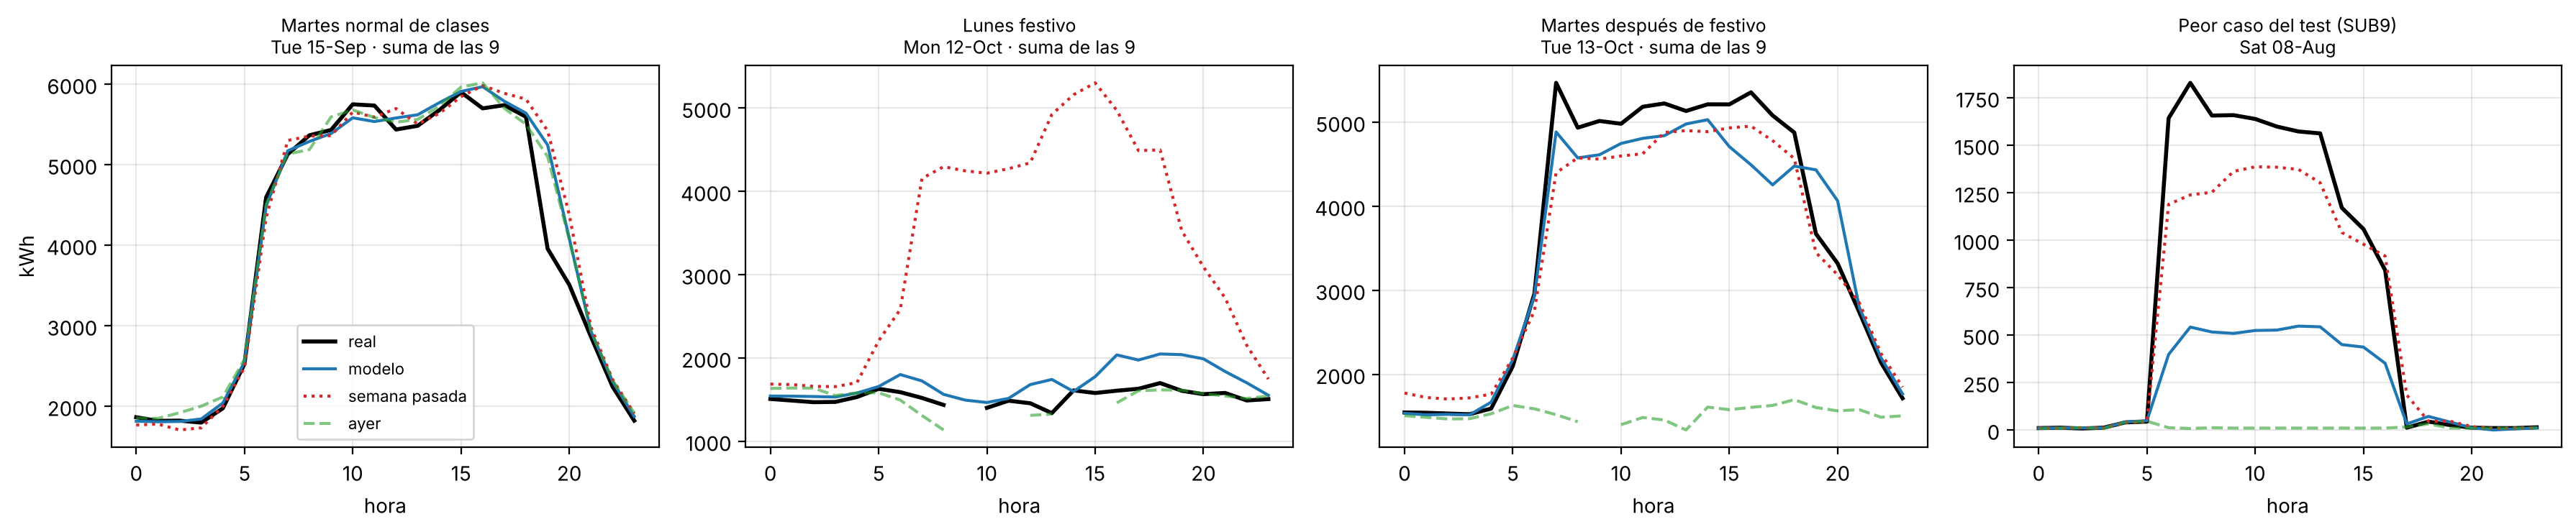

,caso,fecha,kWh real del día,WAPE modelo %,WAPE semana pasada %,WAPE ayer %
0,Martes normal de clases,2026-09-15,97738.6,3.7,4.9,4.0
1,Lunes festivo,2026-10-12,35179.7,12.1,119.0,5.0
2,Martes después de festivo,2026-10-13,88045.8,8.1,7.9,54.3
3,Peor caso del test (SUB9),2026-08-08,16478.0,66.6,19.2,98.1


In [48]:
# =============================================================================
# 13.2 Comparación real vs modelo vs regla simple en días concretos
# =============================================================================
# Suma de las 9 subestaciones por hora (solo horas con las 9 presentes, para no mezclar coberturas)
suma9_h = pred_test.groupby("timestamp")[["kwh", "pred", "lag_168", "lag_24"]].sum(min_count=9)
# Peor caso = subestación-día completo con mayor error ABSOLUTO en kWh (el relativo exagera días de consumo casi nulo)
err_dia = sd.assign(ae=(sd.kwh - sd.pred).abs()).groupby(["subestacion", "dia"], observed=True).ae.sum()
peor_sub, peor_dia = err_dia.idxmax()
casos = [("Martes normal de clases", "2026-09-15", None), ("Lunes festivo", "2026-10-12", None),
         ("Martes después de festivo", "2026-10-13", None), (f"Peor caso del test ({peor_sub})", peor_dia, peor_sub)]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
resumen_casos = []
for ax, (titulo, f, sub) in zip(axes, casos):
    f = pd.Timestamp(f)
    if sub is None:
        d = suma9_h.loc[f: f + pd.Timedelta(hours=23)]
    else:
        d = pred_test[(pred_test.subestacion == sub) & (pred_test.timestamp.dt.normalize() == f)].set_index("timestamp")[["kwh", "pred", "lag_168", "lag_24"]]
    h = d.index.hour
    ax.plot(h, d.kwh, "k-", lw=2, label="real"); ax.plot(h, d.pred, "-", color="tab:blue", label="modelo")
    ax.plot(h, d.lag_168, ":", color="tab:red", label="semana pasada")
    ax.plot(h, d.lag_24, "--", color="tab:green", alpha=0.6, label="ayer")
    ax.set_title(f"{titulo}\n{f:%a %d-%b}" + ("" if sub else " · suma de las 9"), fontsize=9); ax.set_xlabel("hora")
    resumen_casos.append({"caso": titulo, "fecha": f.date(), "kWh real del día": d.kwh.sum(),
                          "WAPE modelo %": 100 * wape(d.kwh, d.pred),
                          "WAPE semana pasada %": 100 * wape(d.kwh, d.lag_168),
                          "WAPE ayer %": 100 * wape(d.kwh, d.lag_24)})
axes[0].set_ylabel("kWh"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
display(pd.DataFrame(resumen_casos).round(1))

## 13.3 ¿Qué variables pesan? Explicación con SHAP

SHAP reparte cada predicción entre las variables: cuánto "empujó" cada una hacia arriba o hacia abajo frente al promedio. Lo aplicamos al LightGBM que realmente pronosticó la semana analizada (el modelo elegido). Recuerda que el modelo predice el consumo **relativo** (kWh / nivel_7d).

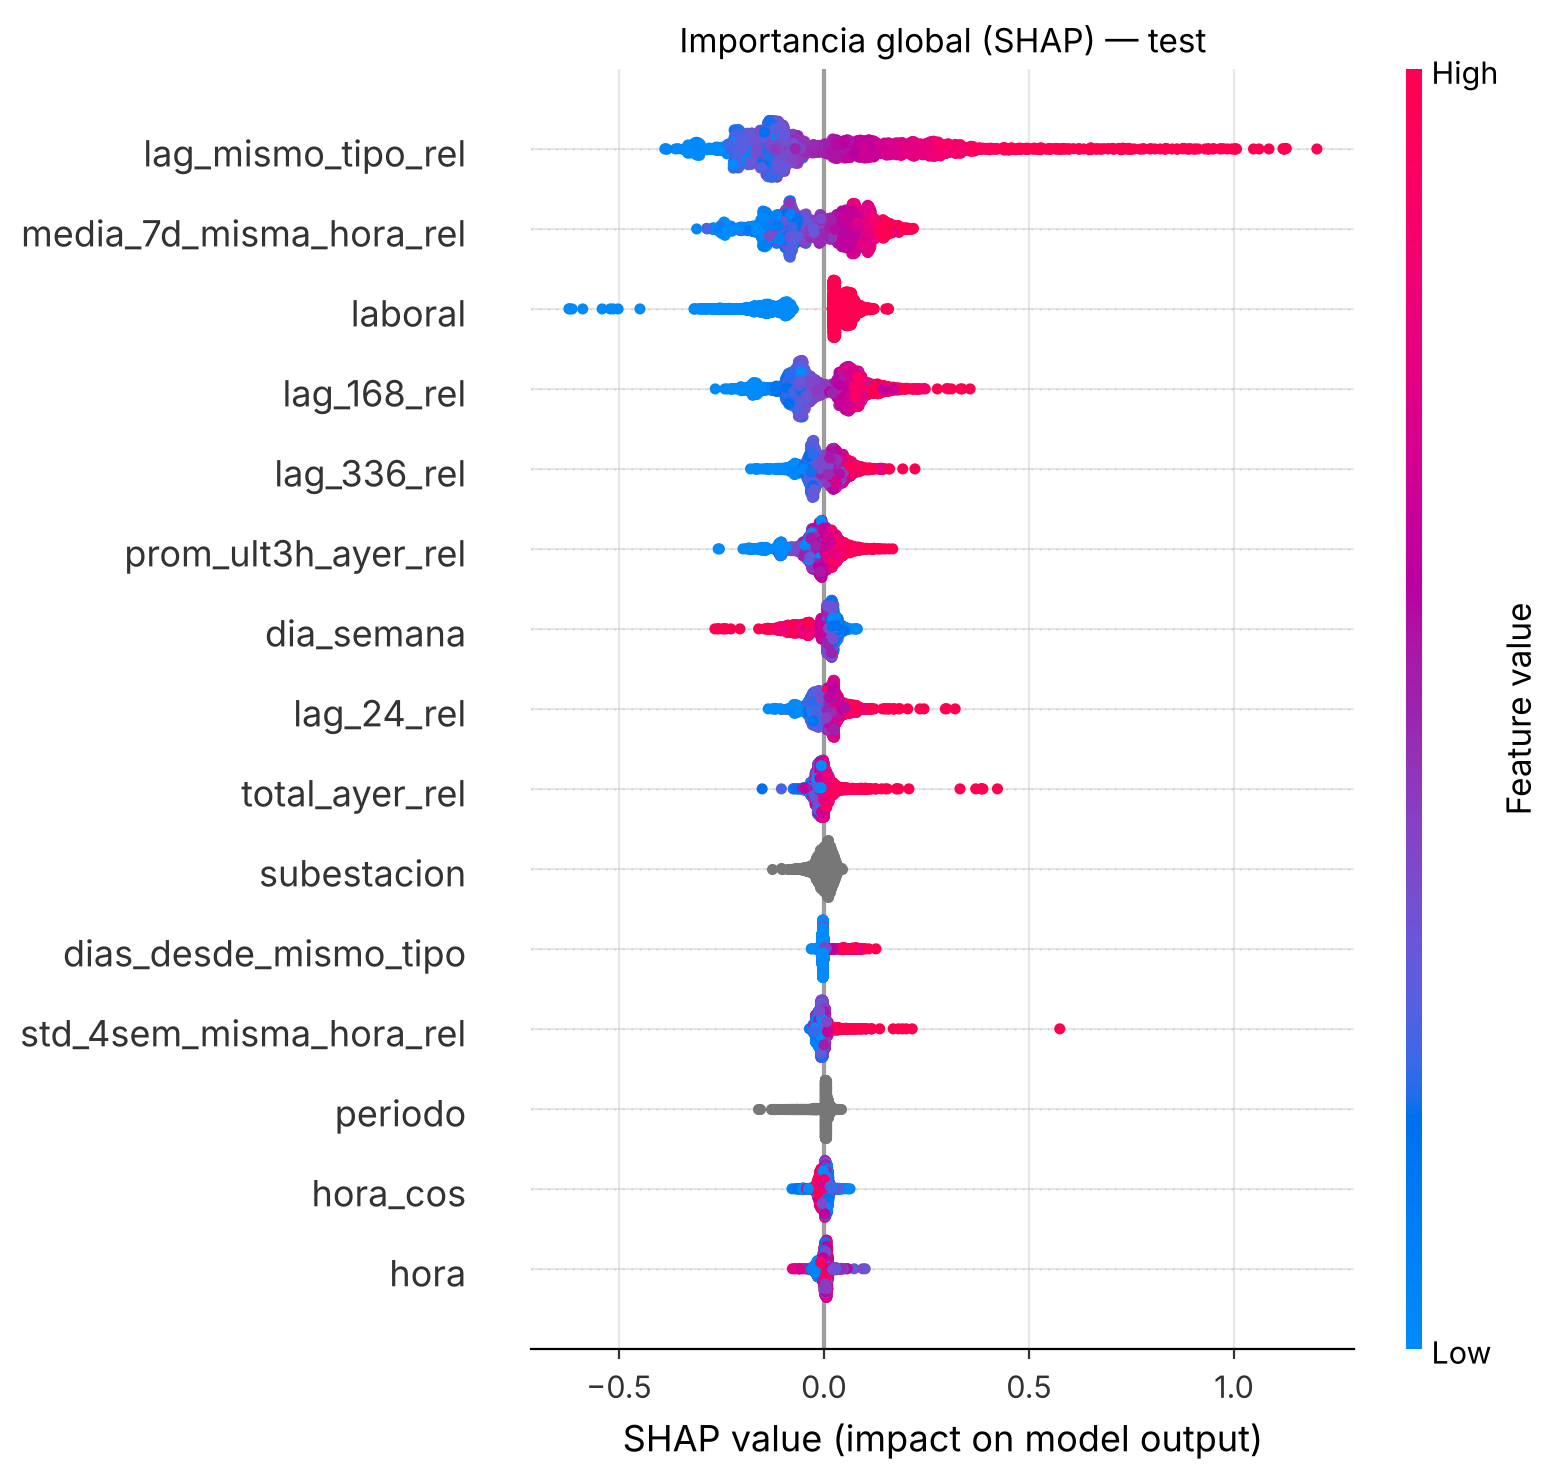

SUB8 2026-10-13 15:00 — base (promedio relativo) = 1.006


,variable,valor,aporte_SHAP
4,lag_mismo_tipo_rel,1.632104,0.291
2,lag_168_rel,1.637167,0.081
3,lag_336_rel,1.983491,0.076
21,laboral,1,0.076
7,media_7d_misma_hora_rel,1.196662,0.055
15,dia_semana,1,0.041


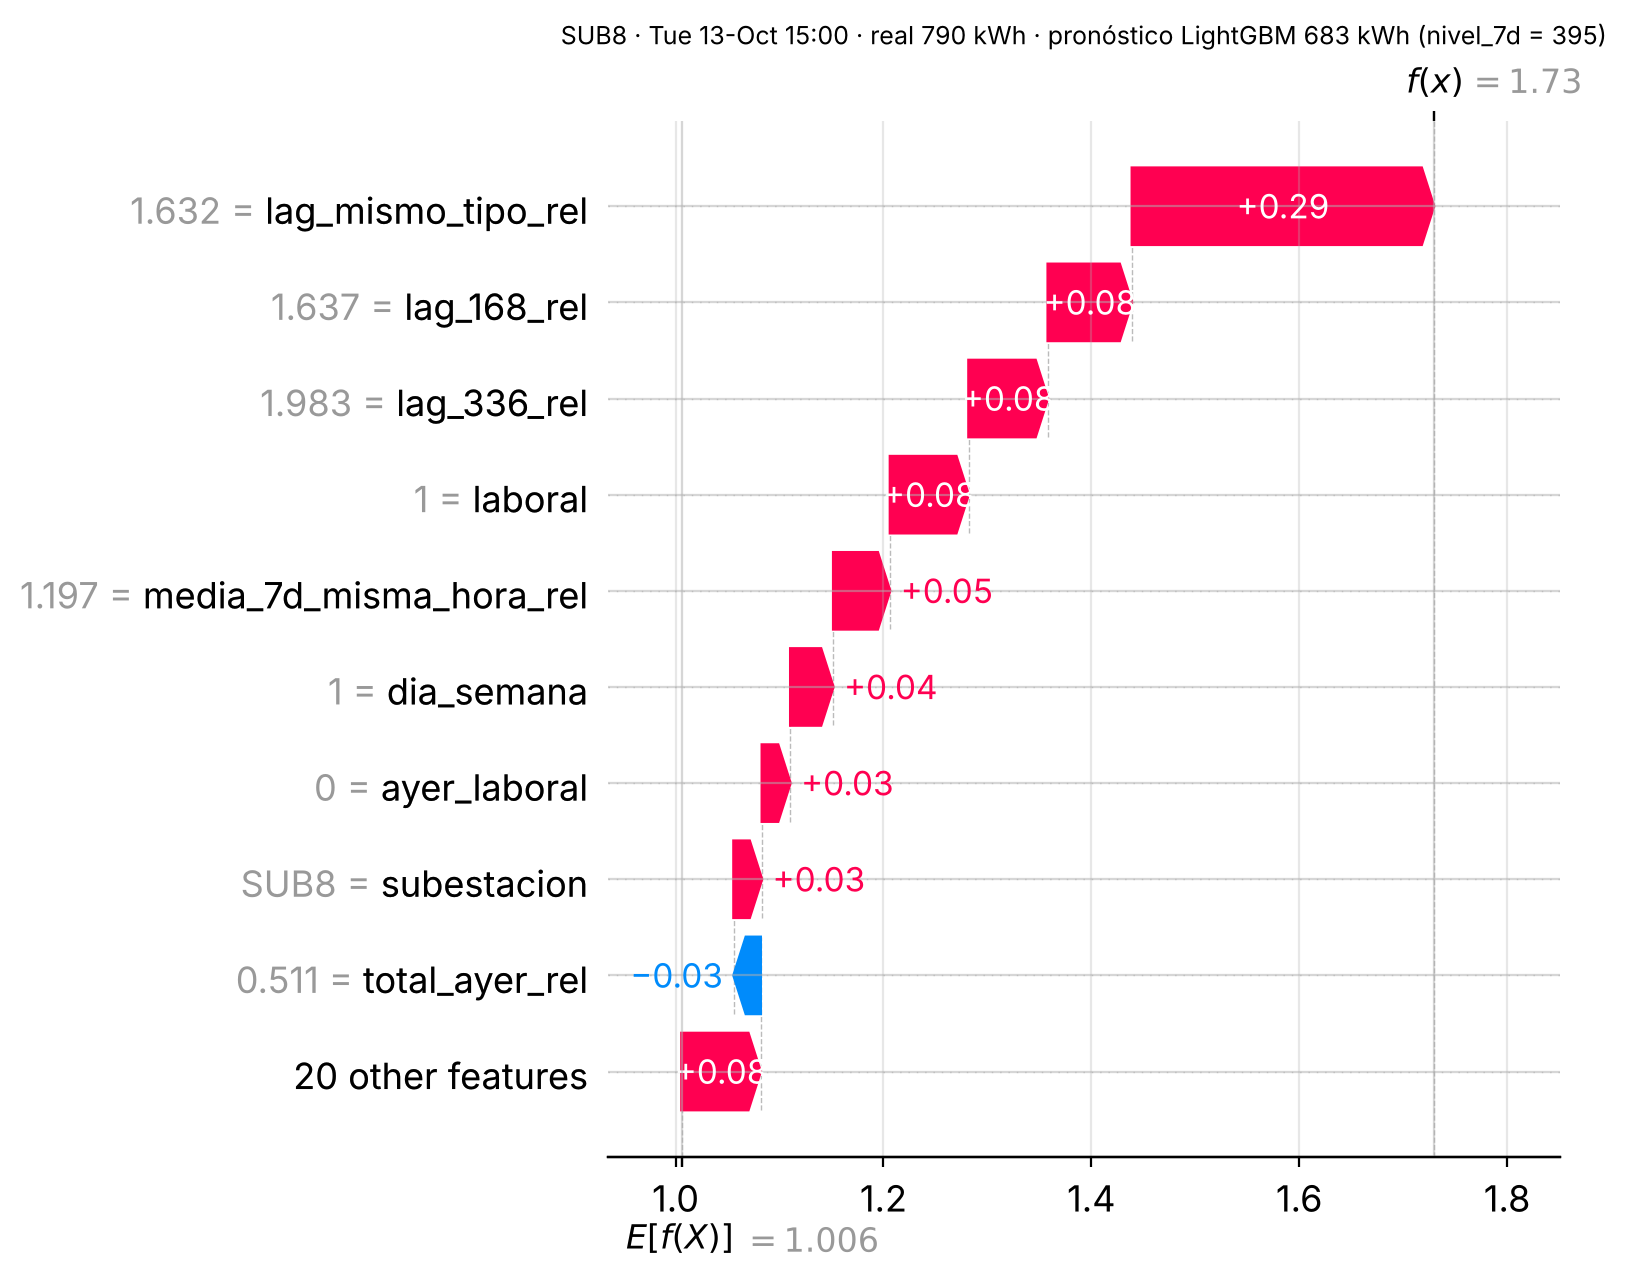

SUB8 2026-10-12 15:00 — base (promedio relativo) = 1.006


,variable,valor,aporte_SHAP
21,laboral,0,-0.185
4,lag_mismo_tipo_rel,0.447733,-0.172
19,festivo,1,-0.107
2,lag_168_rel,1.487083,0.084
7,media_7d_misma_hora_rel,1.224079,0.060
3,lag_336_rel,1.712230,0.058


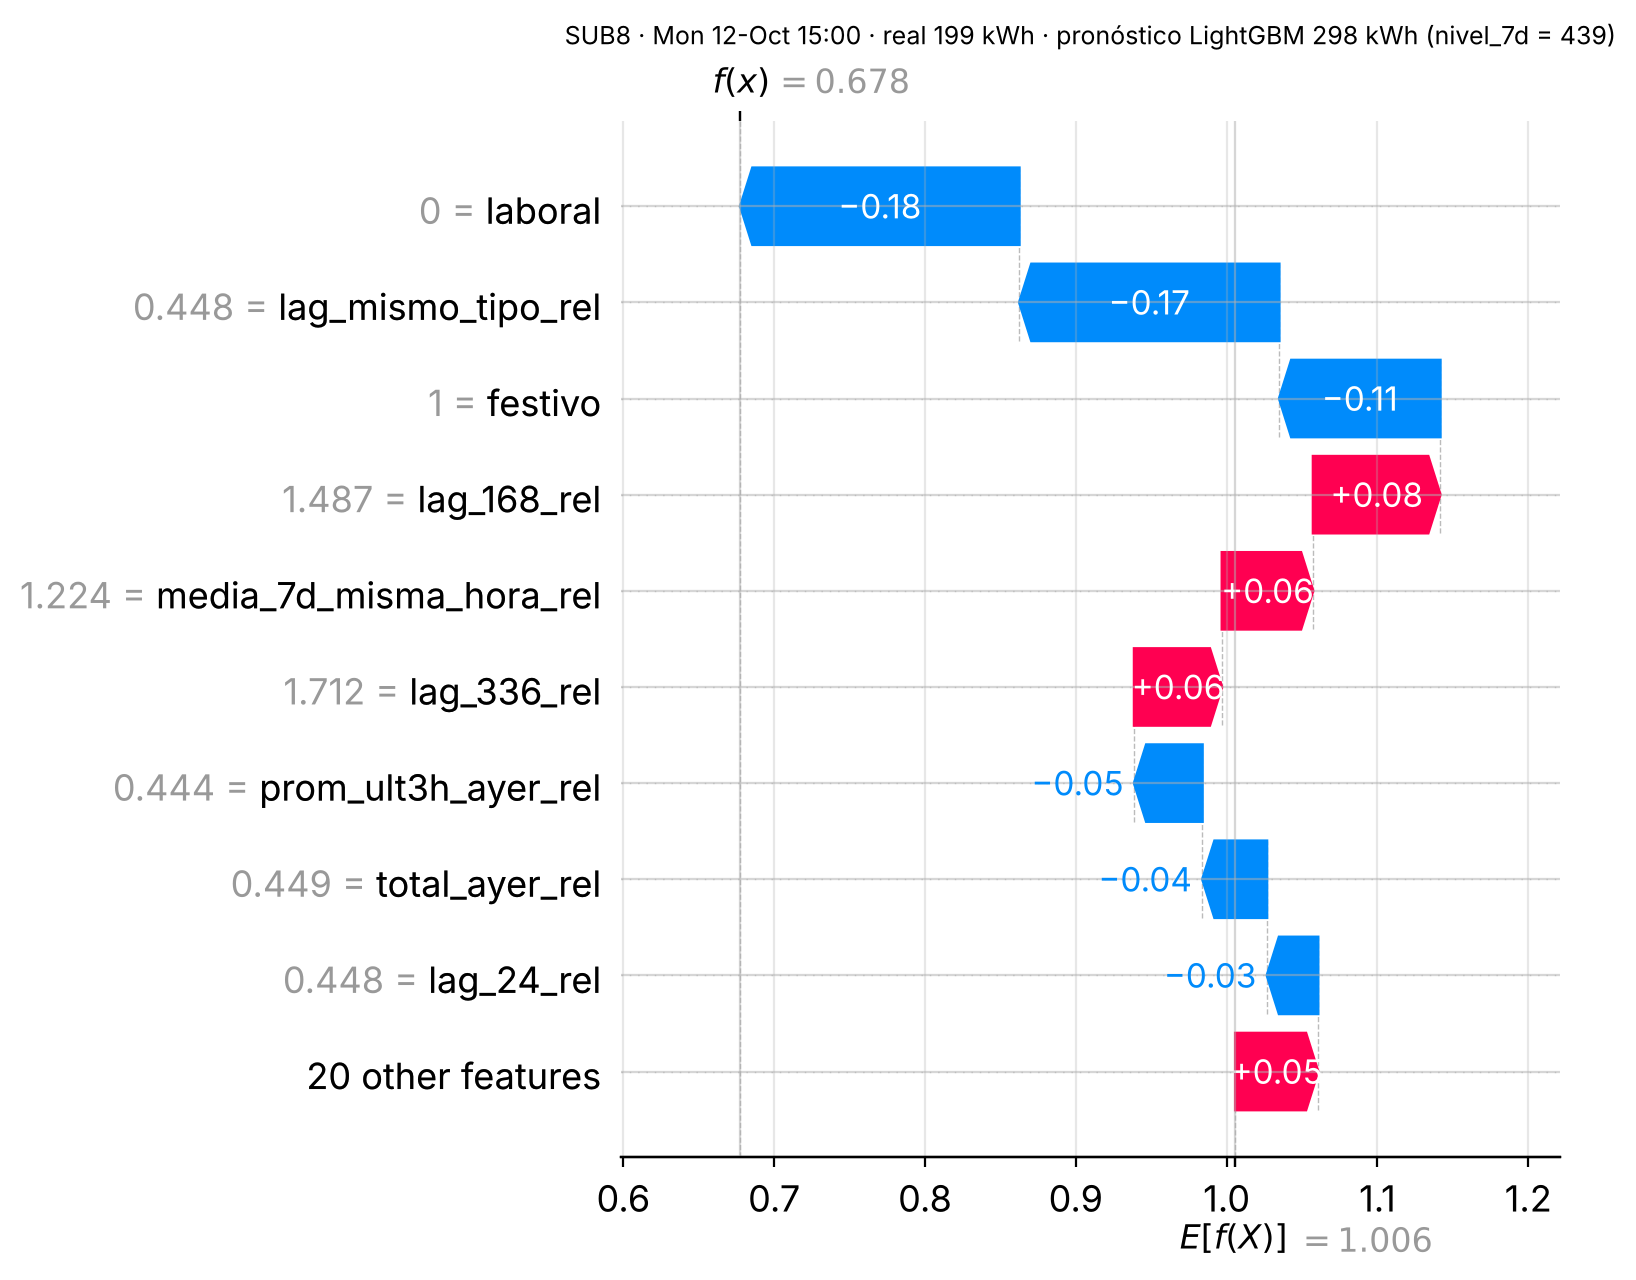

In [49]:
# =============================================================================
# 13.3 SHAP: importancia global y explicación de casos
# =============================================================================
import shap
bloque_oct13 = max(b for b in MODELOS_POR_BLOQUE if b <= pd.Timestamp("2026-10-13"))
m_exp = MODELOS_POR_BLOQUE[bloque_oct13]                     # el LightGBM que realmente pronosticó esa semana
explicador = shap.TreeExplainer(m_exp.modelo)

muestra = test.sample(3000, random_state=SEMILLA)
sv = explicador.shap_values(m_exp._X(muestra))
shap.summary_plot(sv, m_exp._X(muestra), max_display=15, show=False)
plt.title("Importancia global (SHAP) — test"); plt.tight_layout(); plt.show()

def explicar(sub, ts):
    fila = test[(test.subestacion == sub) & (test.timestamp == pd.Timestamp(ts))]
    e = explicador(m_exp._X(fila))
    top = pd.DataFrame({"variable": e.feature_names, "valor": [str(v)[:8] for v in e.data[0]], "aporte_SHAP": e.values[0]})
    top = top.reindex(top.aporte_SHAP.abs().sort_values(ascending=False).index).head(6)
    print(f"{sub} {ts} — base (promedio relativo) = {e.base_values[0]:.3f}"); display(top.round(3))
    shap.plots.waterfall(e[0], max_display=10, show=False)
    real = fila.kwh.iloc[0]; pred = m_exp.predict(fila)[0]
    plt.title(f"{sub} · {pd.Timestamp(ts):%a %d-%b %H:%M} · real {real:.0f} kWh · pronóstico LightGBM {pred:.0f} kWh "
              f"(nivel_7d = {fila.nivel_7d.iloc[0]:.0f})", fontsize=9)
    plt.tight_layout(); plt.show()

explicar("SUB8", "2026-10-13 15:00")      # martes después del festivo
explicar("SUB8", "2026-10-12 15:00")      # lunes festivo

**Cómo se interpretan los casos** (tabla de 13.2 y explicaciones SHAP):

- **Martes normal (15-sep):** el modelo (≈ 3,7 %), "ayer" (≈ 4,0 %) y "semana pasada" (≈ 4,9 %) aciertan casi igual. En días normales la semana se repite; **el valor del modelo no está en los días fáciles**.
- **Lunes festivo (12-oct):** "semana pasada" copia un lunes laboral y se equivoca más de **100 %**. El modelo (≈ 12,1 %) sabe que es festivo. En SHAP (SUB8, 15:00): `lag_mismo_tipo` (el domingo anterior), `laboral = 0` y `festivo = 1` empujan el pronóstico **hacia abajo**; `lag_168` (el lunes anterior) empuja hacia arriba, pero pesa menos. (Aquí "ayer" también funciona, porque ayer fue domingo.)
- **Martes después del festivo (13-oct):** copiar "ayer" (el festivo) falla con ≈ 54 % de error: es la **trampa del lunes** de H5. El modelo (≈ 8,1 %) la evita: en SHAP la variable que más empuja es `lag_mismo_tipo` (el viernes anterior, laboral) y `lag_24` ni siquiera aparece entre las 6 más importantes: **el modelo aprendió a no fiarse de "ayer" cuando ayer no fue laboral**. Ese día "semana pasada" fue algo mejor (≈ 8 %): el modelo subestimó un poco porque la semana anterior fue de **receso** y su `nivel_7d` quedó bajo. Es una limitación honesta: después de un receso, el nivel reciente tarda unos días en recuperarse.
- **Peor caso del test (SUB9, sábado 8-ago, después del festivo del viernes 7):** la climatización funcionó casi como un día laboral. El modelo, sabiendo que era un sábado de puente, esperaba un consumo mucho menor (cerca de un tercio de lo observado en el día) y se equivocó ≈ 67 %. La regla "semana pasada" se acercó más (≈ 19 %) porque el sábado anterior también se había encendido, algo que el modelo trató como excepcional. Es el segundo caso con mayor diferencia observado − pronosticado del periodo, y nada de lo disponible a medianoche permitía saber que ese sábado habría actividad (¿un evento?). Si existiera una **agenda de eventos** (no disponible) este error podría reducirse; mientras tanto, es exactamente el tipo de día que debe disparar una **alerta**.

## 13.4 Cómo lo usaría quien toma la decisión

1. **00:05 cada día:** se ejecuta `pronosticar_dia` con los datos crudos hasta las 23:00 (limpieza automática y causal R1-R4 incluida).
2. **07:00 — reporte al jefe de energía:** tabla como la de 13.1: kWh y costo esperado por subestación, hora pico y banda de alerta.
3. **Durante el día / al día siguiente:** si una subestación supera la banda elegida en validación (ver 12.3) durante el número mínimo de horas → alerta y revisión (¿equipo encendido? ¿evento no informado? ¿falla de medición?).
4. **Cada lunes:** reentrenar con la semana nueva; **cada mes:** recalibrar la banda y revisar el WAPE por subestación.
5. **Finanzas:** suma de los pronósticos diarios × tarifa (estimada) para el presupuesto; la diferencia observada − pronosticada en días atípicos es una referencia de orden de magnitud, no un precio de alquiler.

---
# 14. Conclusiones y guía para la sustentación

## 14.1 Conclusiones

1. Formulamos el problema como **regresión supervisada de forecasting tabular**: pronóstico horario a 24 horas, emitido a medianoche, con un **modelo global** para 9 subestaciones y objetivo normalizado por el nivel reciente.
2. El EDA guio cada decisión: reglas físicas de limpieza (ahora **causales**: nada de lo que se sabe a medianoche depende del futuro), rezagos de 24/168 horas, calendario académico fijo y conocido de antemano (2026 oficial), `lag_mismo_tipo` para la trampa de los lunes y normalización por `nivel_7d` para escalas distintas y el cambio de SUB3.
3. Con validación **walk-forward** (4 pliegues), ajuste con **Optuna** y un **test reservado** evaluado **emisión por emisión** (83 emisiones a las 00:00, reentrenando cada 7 días), el modelo elegido por la regla fijada antes del test (**LightGBM ajustado**) obtiene un **WAPE horario de ≈ 9,3 %** frente a ≈ 17,2 % de la regla "semana pasada" (**−46 %**) en las 17 829 horas comparables, y le gana en las 9 subestaciones.
4. En totales, el error de la **suma de las nueve subestaciones** en los **60 días con cobertura completa** es ≈ 3,1 % vs ≈ 6,8 % de la regla. **No hay ninguna semana completa** con las 9 subestaciones, así que no se reporta un error semanal de esa suma; por subestación-semana completa el error es ≈ 2,0 % vs ≈ 7,8 %.
5. Con las variables probadas (temperatura media y máxima, precipitación, temperatura horaria; NASA POWER) el clima **no mejora** el pronóstico en validación, ni siquiera con datos perfectos del mismo día; no se concluye nada sobre otras variables. La radiación solar, que no se pudo probar fuera de muestra, podría ayudar en los bloques con paneles.
6. En pesos **estimados** (tarifa de COP 524,02/kWh para el test), la **reducción estimada del error de planeación** equivale a ≈ 7,7 % del costo estimado de la energía frente a no tener modelo. El sistema de alertas, con una combinación elegida en validación y congelada (**banda q99, ≥ 2 horas**), genera ≈ 1,3 alertas por semana en la reevaluación retrospectiva del test, con sensibilidad ≈ 19 % y precisión ≈ 40 % sobre los días atípicos de la regla 1,5×. La diferencia observado − pronosticado en días atípicos es un orden de magnitud (mucho mayor en SUB9), no un precio de alquiler.

## 14.2 Próximos pasos

- Conseguir la **agenda de eventos** (fecha, bloque, asistentes) → variable de entrada y precio por evento.
- Datos de **inversores solares** o pronóstico de **radiación** → mejorar SUB5, SUB4 y SUB6.
- Confirmar con el área técnica **qué falta** entre la suma de las nueve series y el medidor general (hipótesis: otras subestaciones del inventario, como la principal, parqueadero sur y Llanogrande) e incorporar esos medidores si corresponde.
- Extensión: horizonte de **7 días** (la misma tabla, con rezagos ≥ 168 h) y **intervalos de predicción** por cuantiles.

## 14.3 Preguntas probables en la sustentación (y cómo responderlas)

| Pregunta | Respuesta corta |
|---|---|
| ¿Por qué no un ARIMA/SARIMA? | Son modelos **locales** (uno por serie), lineales y con un solo ciclo; aquí hay 9 series, dos ciclos (diario y semanal), calendario académico y festivos. La Sesión 3 muestra que el ML tabular global maneja eso de forma natural. La comparación justa es contra los baselines temporales, que sí incluimos. |
| ¿Por qué WAPE y no MAPE? | El MAPE se dispara cuando el consumo es pequeño (SUB9 de noche, casi cero). El WAPE pondera por volumen, que es lo que cuesta dinero. |
| ¿Cómo saben que no hay fuga? | Prueba 5.4 desde los **datos crudos**: para varios días (incluidos los cercanos a huecos y a festivos) se reconstruye limpieza + variables + predicción con los datos recortados a las 23:00, y también destruyendo el futuro; las variables y las predicciones son idénticas. La limpieza se comprobó en 83 cortes (4.1b). El test se simuló emisión por emisión y se usó una sola vez. |
| ¿Por qué no usaron la hora anterior? | A medianoche no se conoce el consumo de las 14:00 del día siguiente. Todas las pistas miran 24 horas atrás o más. |
| ¿Por qué normalizar por `nivel_7d` y no por la media del entrenamiento? | Porque se adapta solo a cambios de nivel (SUB3, inicio de semestre) y se calcula con el pasado inmediato, sin fuga. El experimento E1 lo confirma. |
| ¿Por qué un solo modelo para todas las subestaciones? | Comparte patrones (horas, festivos, periodos) y ayuda a series con poca historia (SUB3, SUB1). E2 lo confirma. |
| ¿Por qué no sacaron los días atípicos del entrenamiento? | Lo probamos (E5) y empeora: esos días también enseñan. Su error se reporta aparte. |
| ¿Qué significa el valor en pesos? | **Reducción estimada del error de planeación**, **no** ahorro en la factura, y calculada con una tarifa **estimada** (COP 524,02/kWh, promedio ene-jun 2026). El ahorro aparece si se actúa sobre las alertas y el pronóstico. |
| ¿Por qué no hay un error semanal? | Porque en el test ninguna semana tiene los 7 días completos de las 9 subestaciones (faltan datos de alguna subestación casi todas las semanas). Reportar una cifra semanal sumando días o subestaciones faltantes sería engañoso; se reporta el semanal por subestación y se rotulan los parciales. |
| ¿Cómo eligieron el umbral de las alertas? | En validación, con un criterio explícito (máximo 7 alertas por semana, ≈ 1 por día; supuesto a confirmar con mantenimiento) y maximizando los días atípicos detectados. Se congeló antes de mirar el test; el test es una reevaluación retrospectiva. |
| ¿Qué pasa si cambian un transformador otra vez? | La normalización se adapta en ~1 semana; las alertas avisan del cambio; se recomienda registrar los cambios y reentrenar. |
| ¿La subida de SUB3 en abril fue una transferencia de SUB9? | Es una **hipótesis**: coincide en el tiempo con el silencio de SUB9, pero no hay registro de la maniobra. |
| ¿Por qué eligieron LightGBM y no el ensamble, si el ensamble tuvo menor error en validación? | La regla, fijada antes del test: menor WAPE medio de validación; si dos candidatos están a menos de 0,1 puntos, gana el más simple. El ensamble ganó por solo 0,08 puntos (11,09 % vs 11,17 %), así que la regla elige LightGBM: un modelo en vez de dos. En el test quedan prácticamente empatados (9,32 % vs 9,38 %). En la versión anterior, con el calendario tentativo, la diferencia era 0,17 y se eligió el ensamble: la regla es la misma, los datos cambiaron. |
| ¿Qué cambió en la versión 3? | El calendario académico oficial de 2026 (2026-2 empieza el 13-jul, no el 20) y 2025 estimado con el mismo patrón; con eso cambia la `semana_semestre` de todo el test. Además, el modelo final queda guardado (`modelos/modelo_energia_v3.joblib`), comprobado al recargarlo y registrado en MLflow. |
| ¿Qué cambió en la versión 4? | Los datos ya no se leen de los Excel: salen de las tablas del pipeline Medallion en Databricks (Silver, valor original), con una celda que comprueba que coinciden exactamente con los archivos originales. Como los datos de entrada son los mismos, el modelo y las cifras no cambian. El EDA que describe la calidad de toda la historia quedó en Databricks; aquí queda el que justifica decisiones del modelo. |
| ¿Por qué el modelo no usa los datos ya limpios de Silver o de Gold? | Porque esa limpieza describe toda la historia y puede mirar el futuro (percentil de toda la serie, relleno de huecos con la lectura siguiente). El modelo necesita una limpieza **causal** para no hacer trampa y para poder reconstruir el pronóstico desde el dato original recortado a las 23:00 (prueba 5.4). La sección 4.1c muestra que las dos limpiezas cuentan la misma historia. |
| ¿Por qué el error del test es menor que el de validación? | Agosto-octubre es casi todo periodo de clases (más regular); la validación incluía intersemestral y recesos, más difíciles. Lo clave es que no empeoró con datos nuevos. |

## 14.5 Qué quedó sin resolver o sin ejecutar (transparencia)

- **Todas las celdas de este notebook se ejecutaron de principio a fin** en una sola corrida (versiones en la celda 2). Lo que **no** se hizo:
  - **Reentrenamiento diario** en el test: se reentrena cada 7 días (12 reentrenamientos); entre ellos el modelo no cambia.
  - **Pronóstico de radiación o de temperatura** como entrada: no hay histórico de pronósticos; el clima solo se probó como observado (ayer) y como "oráculo".
  - **Agenda de eventos** y **generación solar horaria**: no disponibles; ningún día atípico se llama "evento confirmado".
  - **Lectura desde Databricks:** la versión entregada se ejecutó con la fuente que indica la celda 2.1 (ver su salida). Para que
    la ejecución quede hecha contra las tablas del pipeline, se corre una vez dentro de Databricks; si las tablas traen los
    mismos datos (lo comprueban 3.1 y 3.8), las cifras son las mismas.
- **Supuestos sin confirmar:** la capacidad de revisión de alertas (7 por semana), el calendario de 2025 (estimado con el de 2026), y la tarifa de agosto-octubre de 2026 (estimada con el promedio de enero-junio).
- **Hipótesis sin confirmar:** la transferencia de carga SUB9 → SUB3 (abril 2026) y la causa exacta de la diferencia entre la suma de las nueve series y el medidor general.
- **Limitaciones de los resultados:** solo 32 subestación-días atípicos en el test; ninguna semana completa con las 9 subestaciones; 33 horas sin referencia semanal; SUB1 y SUB3 con poca historia.

---
*Notebook reproducible: ejecutar de arriba a abajo. Semilla fija = 42. Salidas guardadas en `resultados/` y `modelos/` (en Databricks, en el Volume del modelo).*

## 14.4 Resumen de las correcciones: resultado anterior / resultado corregido / causa

Esta tabla se genera con **los valores de esta ejecución** (columna "corregido") junto a los de la **versión anterior** del notebook (columna "anterior", copiados de esa versión). Sirve para defender por qué cambió cada cifra. Las cifras "anteriores" **no son metas**: son solo la referencia de lo que se había reportado.

In [50]:
# =============================================================================
# 14.4 Tabla "anterior / corregido / causa" (valores corregidos = los de esta ejecución; en la versión pública, kWh y COP escalados)
# =============================================================================
f2 = lambda x: f"{x:,.2f}"
mod, ref_ = MODELO_ELEGIDO, "Seasonal naive (semana pasada)"
eh = escalas.set_index("escala")
fila = lambda nombre, ant, nuevo, causa: {"cifra": nombre, "anterior (v1)": ant, "corregido (esta ejecución)": nuevo, "causa de la diferencia": causa}
a_dia = eh.loc["diaria (suma de las 9 subestaciones, días completos)"]
tab_cambios = pd.DataFrame([
    fila("Horas evaluadas / planeadas", "17.829 / 17.928", f"{len(cmp):,} comparables / {len(pred_test):,} planeadas ({int(pred_test.tiene_medicion.sum()):,} con medición)",
         "Ahora se distinguen planeadas, con medición válida y comparables con la regla (las cifras de v1 ya eran las comparables)"),
    fila("Efecto de la limpieza causal sobre los datos", "R3 usaba 3 h de futuro y el p99 de toda la serie", f"{int(r3_nuevo.values.sum())} horas marcadas por R3 causal vs {int(r3_anterior.values.sum())} por la anterior; la anterior descartaba {int(solo_ant.values.sum())} que la causal conserva y la causal descarta {int(solo_nuevo.values.sum())} que la anterior conservaba (SUB3, 14-15 abr)",
         "Cambio mínimo en los datos (≈ 0,005 % de las horas): la regla de referencia, que no depende de ningún modelo, da exactamente el mismo WAPE de test (17,162 %) en ambas versiones"),
    fila("Modelo elegido (regla fijada antes del test)", "LightGBM ajustado (el ensamble quedó a < 0,1 puntos)", MODELO_ELEGIDO,
         (lambda d: f"Diferencia de validación entre LightGBM ajustado y el ensamble: {d:.2f} puntos, "
         + ("menor que 0,1: la regla elige el más simple" if d < 0.1 else "mayor que 0,1: la regla elige el ensamble")
         + ". En la v2 (calendario tentativo) el ensamble ganaba por 0,17 puntos; con el calendario oficial (v3) LightGBM mejoró")(ranking.loc['LightGBM ajustado', 'WAPE_medio'] - ranking.loc['Ensamble LightGBM + RF', 'WAPE_medio'])),
    fila("WAPE de validación (modelo elegido vs regla)", "11,193 % (LightGBM) vs 22,606 %", f"{ranking.loc[MODELO_ELEGIDO, 'WAPE_medio']:.3f} % ({MODELO_ELEGIDO}) vs {ranking.loc['Seasonal naive (semana pasada)', 'WAPE_medio']:.3f} %",
         "Se entrena también con las filas sin lag_168 y se vuelve a buscar hiperparámetros; la comparación sigue siendo sobre las mismas filas comparables"),
    fila("WAPE horario modelo (test)", "9,434 % (LightGBM ajustado)", f"{res_test.loc[MODELO_ELEGIDO, 'WAPE_%']:.3f} % ({MODELO_ELEGIDO}); LightGBM ajustado solo: {res_test.loc['LightGBM ajustado', 'WAPE_%']:.3f} %",
         "Diferencia de milésimas de punto: dentro del ruido. No se atribuye a la limpieza (ver fila de efecto de la limpieza); viene del reentrenamiento y la nueva búsqueda de hiperparámetros"),
    fila("WAPE horario regla semana pasada", "17,162 %", f"{res_test.loc[ref_, 'WAPE_%']:.3f} %", "Idéntico: los valores reales del test no cambiaron con la limpieza causal"),
    fila("MAE modelo / regla (kWh)", "(cifra absoluta no publicada)", f"{res_test.loc[MODELO_ELEGIDO, 'MAE_kWh']:.3f} / {res_test.loc[ref_, 'MAE_kWh']:.3f}", "Igual que arriba"),
    fila("WAPE diario por subestación (modelo vs regla)", "5,64 % vs 12,97 %", f"{eh.loc['diaria (subestación-día completo)', 'WAPE modelo %']} % vs {eh.loc['diaria (subestación-día completo)', 'WAPE semana pasada %']} %",
         "Mismo criterio (24 h por subestación-día); cambia solo el modelo"),
    fila("WAPE diario de la suma de las 9 (modelo vs regla)", "3,44 % vs 10,32 % (83 días; 23 de ellos sumaban solo 6 a 8 subestaciones)",
         f"{a_dia['WAPE modelo %']} % vs {a_dia['WAPE semana pasada %']} % ({len(dias_completos)} días con 9 × 24 h)",
         "Solo días con 216 horas comparables; antes se sumaban días con subestaciones faltantes, y eso inflaba el error de la regla"),
    fila("WAPE semanal de la suma de las 9", "1,69 % vs 7,88 %", f"No calculable: {len(sem_completas)} semanas con 7 días × 9 series completos" if len(sem_completas) == 0 else
         f"{100*wape(sem_completas.kwh, sem_completas.pred):.2f} % vs {100*wape(sem_completas.kwh, sem_completas.lag_168):.2f} % ({len(sem_completas)} semanas)",
         "Antes se sumaban semanas con días y subestaciones incompletos; no era una semana. Se reporta el semanal por subestación (semanas completas) y un resultado parcial rotulado"),
    fila("WAPE días normales (modelo vs regla)", "8,7 % vs 16,6 %", f"{tab_atip.loc['día normal', 'WAPE_modelo_%']} % vs {tab_atip.loc['día normal', 'WAPE_semana_pasada_%']} %", "Igual que el WAPE horario"),
    fila("WAPE días atípicos (modelo vs regla)", "33,6 % vs 37,7 %", f"{tab_atip.loc['día atípico', 'WAPE_modelo_%']} % vs {tab_atip.loc['día atípico', 'WAPE_semana_pasada_%']} %", "Igual que el WAPE horario (32 subestación-días: muestra pequeña)"),
    fila("Reducción del error horario en COP", "(cifra absoluta no publicada)", f"≈ COP {negocio.iloc[0, 2]/1e6:,.1f} M en {n_dias_cmp} días (tarifa ESTIMADA 524,02)",
         "Mismas filas comparables; ahora rotulado como reducción estimada del error de planeación"),
    fila("Error del presupuesto diario (% del costo)", "10,3 % → 3,4 % (83 días, algunos incompletos)", f"{negocio.iloc[2, 0]:.1f} % → {negocio.iloc[2, 1]:.1f} % ({len(cd)} días completos)", "Solo días completos de las 9 subestaciones"),
    fila("Alertas (combinación y resultado en test)", "q95 / 3 h elegida mirando el test: ≈ 7,5 alertas/semana; 62,5 % de atípicos detectados; solo 20 de 89 alertas coincidían con un atípico",
         f"{'q'+str(int(ALERTA_Q*100))} / {ALERTA_H} h elegida en validación: {r_test['alertas por semana']:.1f} alertas/semana; sensibilidad {r_test['% atípicos detectados (sensibilidad)']:.1f} %; precisión {r_test['% alertas que caen en día atípico (precisión)']:.1f} % ({r_test['atípicos con alerta']} de {r_test['alertas']} alertas)",
         "La combinación se eligió en validación con un criterio explícito (≤ 7 alertas/semana) y se congeló antes del test; la sensibilidad baja porque la regla es más estricta, y se reportan sensibilidad y precisión"),
    fila("Días atípicos: valor típico en COP", "mediana de excesos positivos (n = 85, solo positivos; cifra absoluta no publicada)",
         f"mediana con signo ≈ COP {eventos.cop_diferencia.median():,.0f} (n = {len(eventos)}; {int((eventos.kwh_diferencia > 0).sum())} por encima, {int((eventos.kwh_diferencia <= 0).sum())} por debajo)",
         "Se conservan todos los casos (antes solo los positivos) y se rotula como diferencia observado − pronosticado"),
])
pd.set_option("display.max_colwidth", 200)
display(tab_cambios.set_index("cifra"))
pd.set_option("display.max_colwidth", 50)

,anterior (v1),corregido (esta ejecución),causa de la diferencia
cifra,,,
Horas evaluadas / planeadas,17.829 / 17.928,"17,829 comparables / 17,928 planeadas (17,862 con medición)","Ahora se distinguen planeadas, con medición válida y comparables con la regla (las cifras de v1 ya eran las comparables)"
Efecto de la limpieza causal sobre los datos,R3 usaba 3 h de futuro y el p99 de toda la serie,"7 horas marcadas por R3 causal vs 5 por la anterior; la anterior descartaba 1 que la causal conserva y la causal descarta 3 que la anterior conservaba (SUB3, 14-15 abr)","Cambio mínimo en los datos (≈ 0,005 % de las horas): la regla de referencia, que no depende de ningún modelo, da exactamente el mismo WAPE de test (17,162 %) en ambas versiones"
Modelo elegido (regla fijada antes del test),"LightGBM ajustado (el ensamble quedó a < 0,1 puntos)",LightGBM ajustado,"Diferencia de validación entre LightGBM ajustado y el ensamble: 0.08 puntos, menor que 0,1: la regla elige el más simple. En la v2 (calendario tentativo) el ensamble ganaba por 0,17 puntos; con el..."
WAPE de validación (modelo elegido vs regla),"11,193 % (LightGBM) vs 22,606 %",11.166 % (LightGBM ajustado) vs 22.550 %,Se entrena también con las filas sin lag_168 y se vuelve a buscar hiperparámetros; la comparación sigue siendo sobre las mismas filas comparables
WAPE horario modelo (test),"9,434 % (LightGBM ajustado)",9.315 % (LightGBM ajustado); LightGBM ajustado solo: 9.315 %,Diferencia de milésimas de punto: dentro del ruido. No se atribuye a la limpieza (ver fila de efecto de la limpieza); viene del reentrenamiento y la nueva búsqueda de hiperparámetros
WAPE horario regla semana pasada,"17,162 %",17.162 %,Idéntico: los valores reales del test no cambiaron con la limpieza causal
MAE modelo / regla (kWh),(cifra absoluta no publicada),35.773 / 65.906,Igual que arriba
WAPE diario por subestación (modelo vs regla),"5,64 % vs 12,97 %",5.49 % vs 12.97 %,Mismo criterio (24 h por subestación-día); cambia solo el modelo
WAPE diario de la suma de las 9 (modelo vs regla),"3,44 % vs 10,32 % (83 días; 23 de ellos sumaban solo 6 a 8 subestaciones)",3.09 % vs 6.8 % (60 días con 9 × 24 h),"Solo días con 216 horas comparables; antes se sumaban días con subestaciones faltantes, y eso inflaba el error de la regla"


In [51]:
# =============================================================================
# 14.4 Guardar resultados para el tablero (curso de Visualización) y para el informe
# =============================================================================
pred_test.to_csv(RES / "pronosticos_test.csv", index=False)           # 83 emisiones × 216 filas, con cobertura y banderas
registro_limpieza.to_csv(RES / "registro_limpieza.csv", index=False)  # valor original + motivo de cada hora descartada
tabla_val_alertas.to_csv(RES / "alertas_validacion.csv")             # selección del umbral (solo validación)
resumen_alertas_test.to_frame().to_csv(RES / "alertas_test_retrospectivo.csv")
tab_cambios.to_csv(RES / "resumen_correcciones.csv", index=False)
manana.to_csv(RES / "pronostico_2026-10-23.csv", index=False)
res_test.to_csv(RES / "metricas_test.csv")
ranking.to_csv(RES / "ranking_validacion.csv")
eventos.to_csv(RES / "diferencia_dias_atipicos.csv", index=False)
pd.DataFrame(UMBRALES).to_csv(RES / "umbrales_alerta_relativos.csv")
print("Archivos guardados en", RES.resolve())
for f in sorted(RES.iterdir()): print("  -", f.name)
print("Origen de los datos de esta ejecución:")
for k, v in ORIGEN.items(): print(f"  - {k}: {v}")

Archivos guardados en <carpeta del proyecto>/modelo/resultados
  - alertas_test_retrospectivo.csv
  - alertas_validacion.csv
  - diferencia_dias_atipicos.csv
  - mejores_parametros_lgbm.json
  - metricas_test.csv
  - pronostico_2026-10-23.csv
  - pronosticos_test.csv
  - ranking_validacion.csv
  - registro_limpieza.csv
  - resumen_correcciones.csv
  - umbrales_alerta_relativos.csv
Origen de los datos de esta ejecución:
  - consumo: archivo ../datos/Subestaciones_15_abril_2025_-_22_oct_2026.xlsx
  - capacidad: valores confirmados por la universidad (escritos en 3.1b)
  - demanda_total: archivo ../datos/consumo_total.xlsx
  - clima: archivo ../datos/clima_nasa_power_eafit.csv


## 14.4b Publicar los resultados en Databricks

El notebook `04_resultados` de Databricks carga estos archivos a tablas Gold (`gold_pronosticos_test`, `gold_metricas_test`,
`gold_modelos`, ...) que consume el tablero. Dentro de Databricks no hay nada que hacer: los archivos ya quedaron en el Volume.
Desde un computador con credenciales, la celda los sube al Volume con el SDK de Databricks (`pip install databricks-sdk`); sin
credenciales, indica cómo subirlos a mano.

In [52]:
# =============================================================================
# 14.4b Publicar resultados/ y modelos/ en el Volume del modelo
# =============================================================================
SUBIR_A_DATABRICKS = True             # solo aplica fuera de Databricks y con credenciales
if EN_DATABRICKS:
    print(f"Los archivos ya están en el Volume ({RES} y {MOD}). Siguiente paso: correr 04_resultados.")
elif MODO_LECTURA == "conector" and SUBIR_A_DATABRICKS:
    try:
        from databricks.sdk import WorkspaceClient
        w = WorkspaceClient(host="https://" + CREDENCIALES["DATABRICKS_SERVER_HOSTNAME"].replace("https://", "").rstrip("/"),
                            token=CREDENCIALES["DATABRICKS_TOKEN"])
        subidos = 0
        for carpeta in (RES, MOD):
            for f in sorted(p for p in carpeta.iterdir() if p.is_file()):
                with open(f, "rb") as contenido:
                    w.files.upload(f"{RUTA_VOLUME_MODELO}/{carpeta.name}/{f.name}", contenido, overwrite=True)
                subidos += 1
        print(f"✅ {subidos} archivos subidos a {RUTA_VOLUME_MODELO}. Siguiente paso: correr 04_resultados en Databricks.")
    except Exception as e:
        print(f"⚠️ No se pudieron subir ({type(e).__name__}: {e}). Subirlos a mano (ver abajo).")
else:
    print("Para publicarlos en Databricks: Catalog → workspace → eafit_energia → Volume 'bronze' → carpeta 'modelo' → "
          "'Upload to this volume', con las carpetas resultados/ y modelos/; o con la CLI de Databricks:\n"
          f"  databricks fs cp -r resultados dbfs:{RUTA_VOLUME_MODELO}/resultados --overwrite\n"
          f"  databricks fs cp -r modelos dbfs:{RUTA_VOLUME_MODELO}/modelos --overwrite\n"
          "Después, correr 04_resultados.")

Para publicarlos en Databricks: Catalog → workspace → eafit_energia → Volume 'bronze' → carpeta 'modelo' → 'Upload to this volume', con las carpetas resultados/ y modelos/; o con la CLI de Databricks:
  databricks fs cp -r resultados dbfs:/Volumes/workspace/eafit_energia/bronze/modelo/resultados --overwrite
  databricks fs cp -r modelos dbfs:/Volumes/workspace/eafit_energia/bronze/modelo/modelos --overwrite
Después, correr 04_resultados.
